# VK Case Champ 2026 — разведочный анализ датасета

> **После Q&A.** Основной результат — оформленные заказы собственных продавцов внутри VK. Оплата внутри VK добровольна. Заказы Партнёра включают прямые переходы. Графики ниже сохраняют исходный разведочный анализ. Для стратегии и защиты используйте [актуальные материалы](../presentation/README.md).

**Кейс:** развитие социальной коммерции для бизнес-сообществ ВКонтакте.
**Данные:** `sources/dataset.xlsx` — 7 листов синтетических обезличенных данных за сентябрь 2026.

Ноутбук отвечает на три вопроса, которые нужны для стратегии:

1. **Кто продаёт и кто нет** — где в пути «каталог → приём заказов в VK (чекаут) → онлайн-оплата и доставка → заказ» теряются товарные сообщества.
2. **Что отличает продающих** — аудитория, товарный контент, трафик на карточку, тематика, реклама, цена.
3. **Как работает Маркет ВКонтакте против Партнёра** — воронка, источники трафика, категории, покупатели, динамика.

В конце — сверки данных (где листы расходятся между собой) и сводка выводов.

| Раздел | Содержание |
|---|---|
| 0 | Настройка и загрузка |
| 1 | Обзор листов и качества данных |
| 2 | Бизнес-сообщества: структура, воронка инструментов, концентрация |
| 3 | Что связано с наличием заказов |
| 4 | Сегментация товарных продавцов |
| 5 | Маркет ВКонтакте vs Партнёр |
| 6 | Сверки и расхождения |
| 7 | Выводы для стратегии |

> Все показатели — **за один месяц (сентябрь 2026)**. «Есть заказ» = хотя бы один заказ через чекаут за 30 дней. Корреляции в разделе 3 — описательные, не причинные.

## 0. Настройка и загрузка

In [1]:
# В Colab всё нужное уже установлено. Данные подтягиваются из публичного репозитория,
# либо из локальной папки, если ноутбук запущен из клона репозитория.
import io, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_URL = "https://raw.githubusercontent.com/Shadovv-Government/vs_case_champ/main/sources/dataset.xlsx"
LOCAL = [Path("sources/dataset.xlsx"), Path("../../sources/dataset.xlsx"), Path("dataset.xlsx"), Path("/content/dataset.xlsx")]

src = next((p for p in LOCAL if p.exists()), None)
if src is None:
    src = io.BytesIO(urllib.request.urlopen(DATA_URL).read())
    print("Датасет загружен из GitHub")
else:
    print(f"Датасет загружен локально: {src}")

xls = pd.ExcelFile(src)
print("Листы:", xls.sheet_names)

Датасет загружен локально: ..\sources\dataset.xlsx


Листы: ['Бизнесы', 'Маркет Вконтакте — итоги', 'Маркет Вконтакте — по дням', 'Маркет Вконтакте — источники', 'Маркет Вконтакте — категории', 'Покупатели', 'Покупатели по регионам']


In [2]:
# ---------- Оформление графиков: единая палитра и стиль ----------
VK, PARTNER = "#2a78d6", "#eb6834"                      # Маркет ВКонтакте / Партнёр — во всех графиках
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
GOOD, BAD = "#0ca30c", "#d03b3b"

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": INK2,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False,
    "legend.fontsize": 10, "figure.dpi": 110, "savefig.dpi": 150, "lines.linewidth": 2,
})
try:
    get_ipython().run_line_magic("config", "InlineBackend.figure_format = 'retina'")
except Exception:
    pass

def ru(x, d=0):
    # Число в русском формате: 1 234 567,8
    if pd.isna(x):
        return "—"
    return f"{x:,.{d}f}".replace(",", " ").replace(".", ",")

def pct(x, d=1):
    return ru(100 * x, d) + "%"

def finish(fig, title, subtitle=None, note=None, top=0.84):
    # Заголовок-вывод слева сверху, подзаголовок с пояснением, источник снизу.
    fig.tight_layout(rect=[0, 0.04 if note else 0, 1, top])
    fig.text(0.012, 0.985, title, fontsize=15, fontweight="bold", color=INK, ha="left", va="top")
    if subtitle:
        fig.text(0.012, 0.985 - 0.075 * (6 / fig.get_figheight()), subtitle, fontsize=10.5, color=INK2, ha="left", va="top")
    if note:
        fig.text(0.012, 0.008, note, fontsize=8.5, color=MUTED, ha="left", va="bottom")
    plt.show()

def hbar_labels(ax, bars, labels, inside=False, color=INK, pad=4):
    for b, t in zip(bars, labels):
        w = b.get_width()
        ax.annotate(t, (w, b.get_y() + b.get_height() / 2), xytext=(pad, 0), textcoords="offset points",
                    va="center", ha="left", fontsize=9.5, color=color)

def vbar_labels(ax, bars, labels, color=INK, pad=4, fs=9.5):
    for b, t in zip(bars, labels):
        ax.annotate(t, (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, pad), textcoords="offset points",
                    ha="center", va="bottom", fontsize=fs, color=color)

def hgrid(ax):
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.grid(axis="y", visible=False)
    ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(True); ax.spines["left"].set_color(BASE)

print("Стиль настроен")

Стиль настроен


In [3]:
# ---------- Лист «Бизнесы»: короткие имена колонок ----------
biz_raw = pd.read_excel(xls, "Бизнесы")
COLS = {
    "ID бизнеса": "id", "Тематика": "topic", "Тип бизнеса (товары / услуги)": "type",
    "Число подписчиков": "subs", "Посты за 30 дней": "posts", "Клипы за 30 дней": "clips",
    "Посты с товаром за 30 дней": "posts_p", "Клипы с товаром за 30 дней": "clips_p",
    "Просмотры обычного контента": "v_reg", "Лайки обычного контента": "l_reg", "Репосты обычного контента": "r_reg",
    "Просмотры товарного контента": "v_prod", "Лайки товарного контента": "l_prod", "Репосты товарного контента": "r_prod",
    "Открытия карточки товара из контента": "opens", "Товары загружены": "loaded",
    "Число активных товаров в каталоге": "active", "Подключён чекаут": "checkout",
    "Подключена доставка": "delivery", "Подключена оплата": "payment",
    "Автор оригинального контента (оценка модели)": "orig", "Участие в реферальной программе": "ref",
    "Заказы через чекаут": "orders", "GMV через чекаут, ₽": "gmv", "Средний чек, ₽": "aov",
    "Траты на рекламу всего, ₽": "ads", "Число активных услуг": "services", "Медианная цена товара, ₽": "price",
}
assert set(COLS) == set(biz_raw.columns), "Структура листа изменилась"
biz = biz_raw.rename(columns=COLS)
biz["has_order"] = biz.orders > 0
biz["pubs"] = biz.posts + biz.clips
biz["pubs_p"] = biz.posts_p + biz.clips_p

GOODS_TYPES = ["товарное", "товарное и услужное"]
goods = biz[biz.type.isin(GOODS_TYPES)].copy()     # фокус кейса — продажа товаров
print(f"Сообществ: {ru(len(biz))}, уникальных ID: {ru(biz.id.nunique())}, тематик: {biz.topic.nunique()}")
print(f"Товарных и смешанных: {ru(len(goods))}")
biz.head()

Сообществ: 9 754, уникальных ID: 9 754, тематик: 42
Товарных и смешанных: 4 158


,id,topic,type,subs,posts,clips,posts_p,clips_p,v_reg,l_reg,r_reg,v_prod,l_prod,r_prod,opens,loaded,active,checkout,delivery,payment,orig,ref,orders,gmv,aov,ads,services,price,has_order,pubs,pubs_p
0,9308,Мода и стиль,без каталога,2800,66,1,22,1,1000000,51694,268,3800000,103250,1287,8372,0,0,0,0,0,1.0,1,0,0,NaN,0,0,NaN,False,67,23
1,3078,Спорт,без каталога,98000,7,46,0,7,550000,16429,10479,2300000,49299,28344,5818,0,0,1,0,0,1.0,1,0,0,NaN,0,0,NaN,False,53,7
2,5330,Образование,товарное,12000,380,0,26,0,380000,2530,636,1300000,1999,1065,6749,700,693,1,1,1,1.0,1,83,17150,208.0,0,0,169.0,True,380,26
3,5072,Развлечения и хобби,товарное,5200,12,0,20,0,260000,319,37,1200000,1380,1266,550,4986,4887,1,1,1,0.0,0,2,6250,2648.0,0,0,1325.0,True,12,20
4,6398,Личный блог,без каталога,440,35,20,7,12,530000,1915,455,1100000,2584,1228,10859,0,0,0,0,0,1.0,1,0,0,NaN,0,0,NaN,False,55,19


## 1. Обзор листов и качества данных

Семь листов делятся на две несвязанные части: **«Бизнесы»** (одна строка = одно сообщество) и **агрегаты Маркета** (итоги, дни, источники, категории, покупатели, регионы). Общего ключа между ними нет: сопоставлять можно только на уровне выводов, не строк.

In [4]:
DESC = {
    "Бизнесы": "Сообщества: тематика, тип, контент, инструменты торговли, заказы, реклама",
    "Маркет Вконтакте — итоги": "Месячные метрики Маркета и Партнёра + общие метрики Маркета",
    "Маркет Вконтакте — по дням": "Ежедневная динамика за 1–30 сентября",
    "Маркет Вконтакте — источники": "Открытия карточки по источникам трафика",
    "Маркет Вконтакте — категории": "Открытия карточки и заказы по 18 категориям",
    "Покупатели": "Покупатели и заказы по полу и возрасту",
    "Покупатели по регионам": "Покупатели и заказы по регионам",
}
overview = pd.DataFrame([
    {"Лист": s, "Строк": pd.read_excel(xls, s).shape[0], "Колонок": pd.read_excel(xls, s).shape[1], "Что внутри": DESC.get(s, "")}
    for s in xls.sheet_names
])
overview.style.hide(axis="index").set_properties(**{"text-align": "left"})

Лист,Строк,Колонок,Что внутри
Бизнесы,9754,28,"Сообщества: тематика, тип, контент, инструменты торговли, заказы, реклама"
Маркет Вконтакте — итоги,26,4,Месячные метрики Маркета и Партнёра + общие метрики Маркета
Маркет Вконтакте — по дням,30,19,Ежедневная динамика за 1–30 сентября
Маркет Вконтакте — источники,7,5,Открытия карточки по источникам трафика
Маркет Вконтакте — категории,18,5,Открытия карточки и заказы по 18 категориям
Покупатели,15,6,Покупатели и заказы по полу и возрасту
Покупатели по регионам,89,5,Покупатели и заказы по регионам


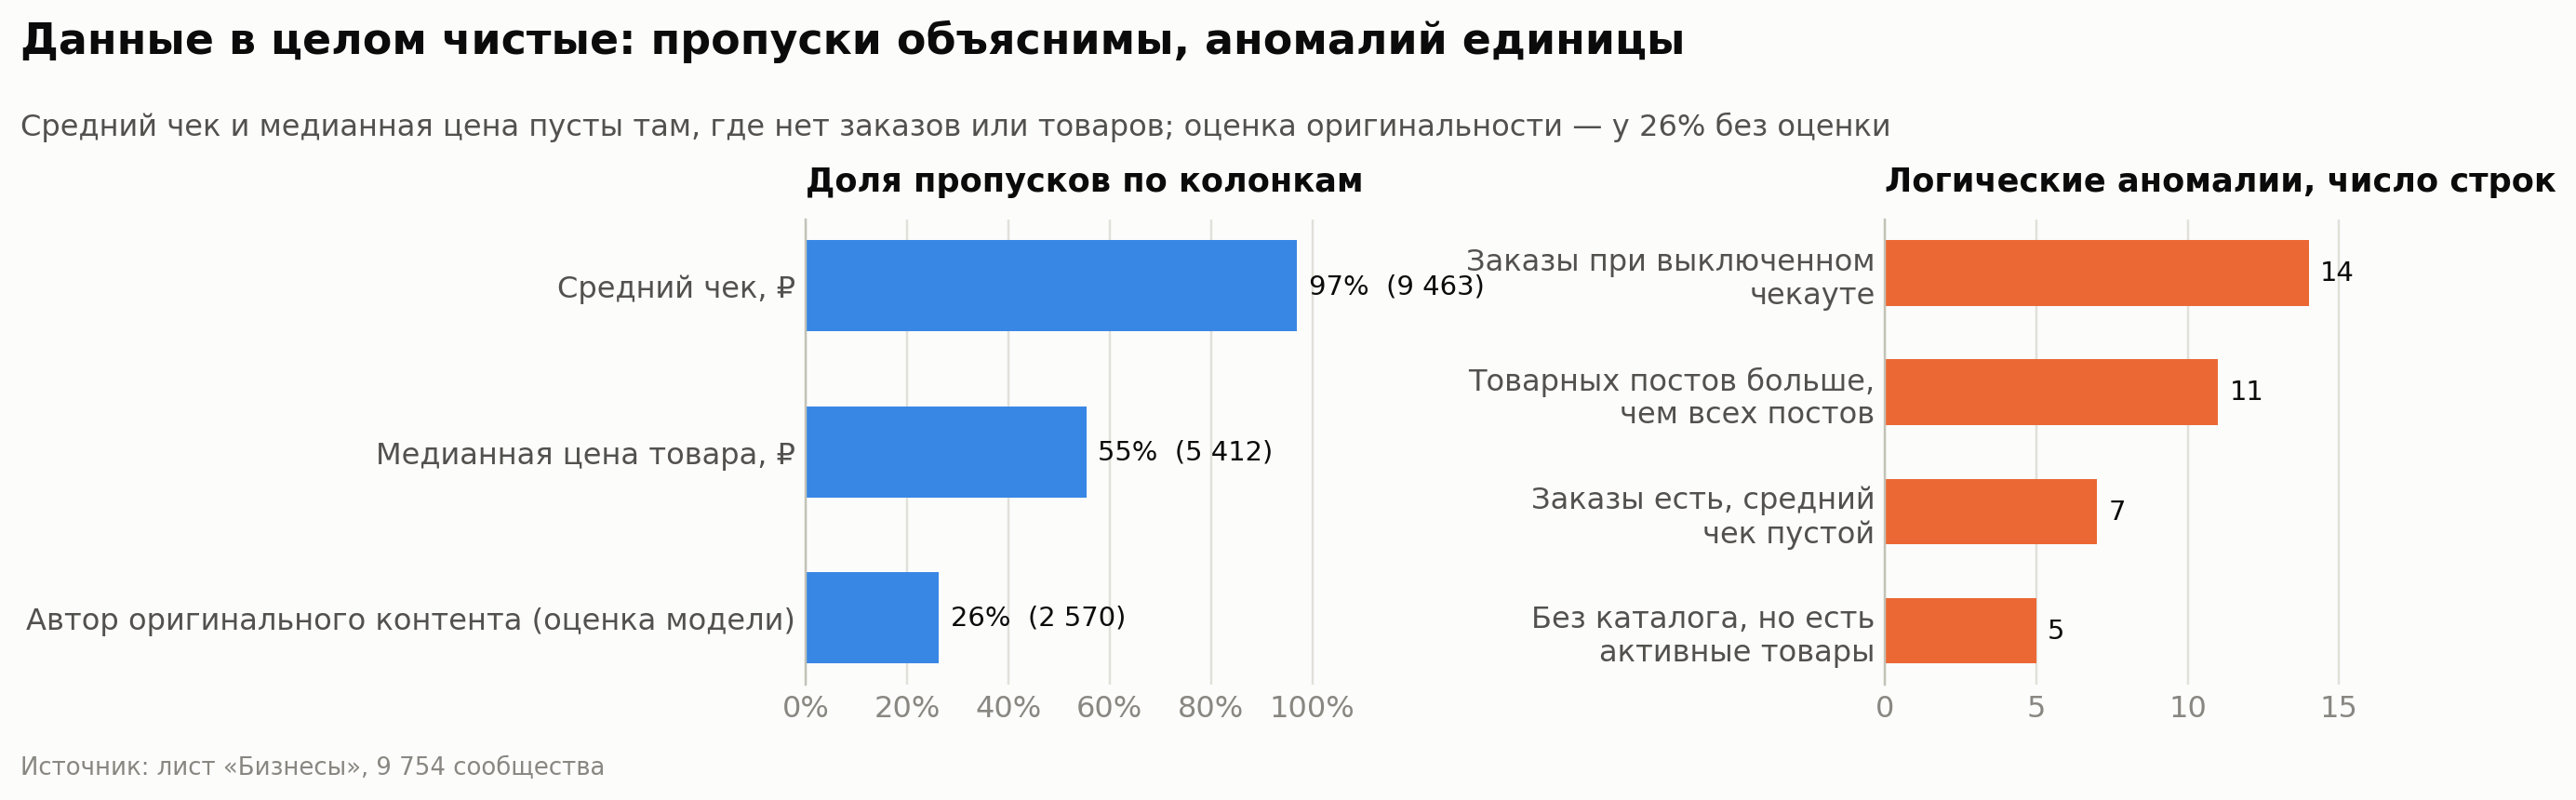

In [5]:
# Пропуски и аномалии в листе «Бизнесы»
miss = (biz_raw.isna().sum() / len(biz_raw)).loc[lambda s: s > 0].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})

ax = axes[0]
bars = ax.barh(miss.index, miss.values, color=SEQ[3], height=0.55)
hbar_labels(ax, bars, [f"{pct(v, 0)}  ({ru(biz_raw[c].isna().sum())})" for c, v in miss.items()])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1.15); hgrid(ax)
ax.set_title("Доля пропусков по колонкам")

anom = pd.Series({
    "Товарных постов больше,\nчем всех постов": int((biz.posts_p > biz.posts).sum()),
    "Заказы при выключенном\nчекауте": int(((biz.checkout == 0) & biz.has_order).sum()),
    "Заказы есть, средний\nчек пустой": int((biz.has_order & biz.aov.isna()).sum()),
    "Без каталога, но есть\nактивные товары": int(((biz.type == "без каталога") & (biz.active > 0)).sum()),
}).sort_values()
ax = axes[1]
bars = ax.barh(anom.index, anom.values, color=CAT[1], height=0.55)
hbar_labels(ax, bars, [ru(v) for v in anom.values]); hgrid(ax)
ax.set_xlim(0, anom.max() * 1.25)
ax.set_title("Логические аномалии, число строк")
finish(fig, "Данные в целом чистые: пропуски объяснимы, аномалий единицы",
       "Средний чек и медианная цена пусты там, где нет заказов или товаров; оценка оригинальности — у 26% без оценки",
       "Источник: лист «Бизнесы», 9 754 сообщества")

## 2. Бизнес-сообщества: структура, воронка инструментов, концентрация

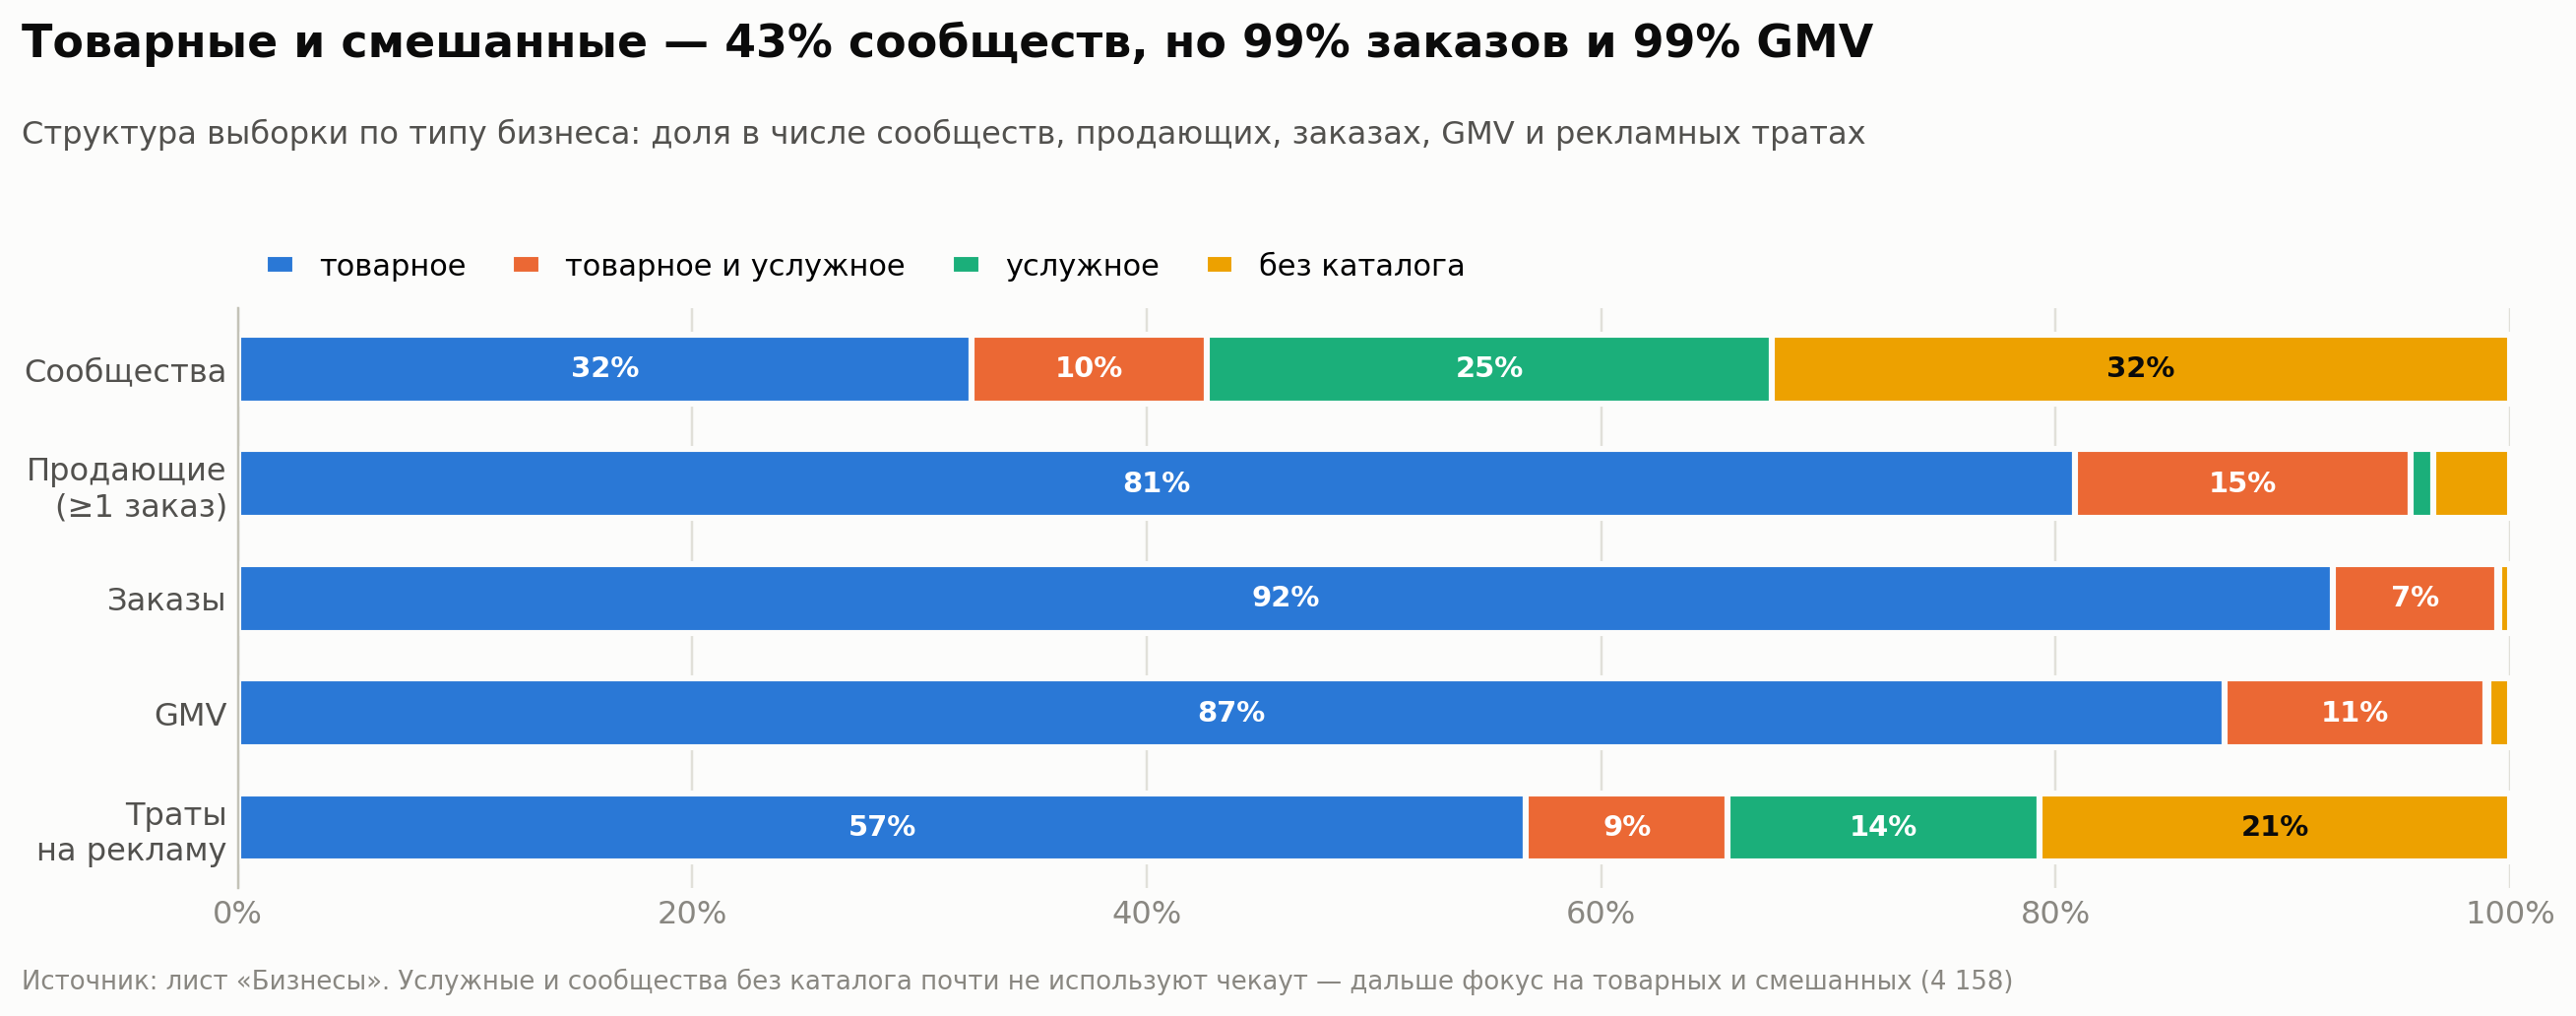

,сообществ,заказов,"GMV, ₽",продающих,"реклама, ₽",доля_продающих
type,,,,,,
товарное,3150,3207,8720487,241,52371953,"7,7%"
товарное и услужное,1008,251,1144580,44,8188489,"4,4%"
услужное,2428,4,14310,3,12683672,"0,1%"
без каталога,3168,16,93650,10,19119300,"0,3%"


In [6]:
TYPE_ORDER = ["товарное", "товарное и услужное", "услужное", "без каталога"]
TYPE_COL = dict(zip(TYPE_ORDER, CAT[:4]))
by_type = biz.groupby("type").agg(n=("id", "size"), orders=("orders", "sum"), gmv=("gmv", "sum"),
                                  sellers=("has_order", "sum"), ads=("ads", "sum")).reindex(TYPE_ORDER)
shares = by_type[["n", "sellers", "orders", "gmv", "ads"]] / by_type[["n", "sellers", "orders", "gmv", "ads"]].sum()
rows = {"n": "Сообщества", "sellers": "Продающие\n(≥1 заказ)", "orders": "Заказы", "gmv": "GMV", "ads": "Траты\nна рекламу"}

fig, ax = plt.subplots(figsize=(12, 4.6))
left = np.zeros(len(rows))
for t in TYPE_ORDER:
    vals = shares.loc[t, list(rows)].values
    bars = ax.barh(list(rows.values()), vals, left=left, color=TYPE_COL[t], height=0.6, edgecolor=SURF, linewidth=2, label=t)
    for b, v, l in zip(bars, vals, left):
        if v > 0.06:
            ax.text(l + v / 2, b.get_y() + b.get_height() / 2, pct(v, 0), ha="center", va="center",
                    color=INK if TYPE_COL[t] == CAT[3] else "white", fontsize=9.5, fontweight="bold")
    left += vals
ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1); hgrid(ax)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1, columnspacing=1.5)
gs = shares.loc[GOODS_TYPES].sum()
finish(fig, f"Товарные и смешанные — {pct(gs['n'], 0)} сообществ, но {pct(gs['orders'], 0)} заказов и {pct(gs['gmv'], 0)} GMV",
       "Структура выборки по типу бизнеса: доля в числе сообществ, продающих, заказах, GMV и рекламных тратах",
       "Источник: лист «Бизнесы». Услужные и сообщества без каталога почти не используют чекаут — дальше фокус на товарных и смешанных (4 158)",
       top=0.80)
by_type.assign(доля_продающих=lambda d: (d.sellers / d.n).map(pct)).rename(columns={"n": "сообществ", "sellers": "продающих", "orders": "заказов", "gmv": "GMV, ₽", "ads": "реклама, ₽"})

### 2.1 Воронка инструментов торговли

**Как читать признаки.** «Подключён чекаут» — сообщество принимает заказы внутри VK (корзина и оформление, как в определении брифа). «Подключена оплата» и «Подключена доставка» — это, судя по данным, **онлайн-оплата и интеграция со службой доставки**, а не сама возможность оплатить и получить товар. Заказ можно оформить и без них: оплату и отправку продавец согласует с покупателем вручную, обычно в сообщениях. Это подтверждают сами данные: у сообществ без онлайн-оплаты и доставки за месяц 1 791 заказ, онлайн-оплата подключена лишь у 2,6% сообществ, а на уровне Маркета оплачено внутри VK 1,2% заказов. На Q&A уточнили, что оплата внутри VK добровольна, а признаки инструментов фиксируют конец периода. Точное определение флага доставки требует уточнения.

Приём заказов включён почти у всех товарных сообществ, но **онлайн-оплату или доставку** подключили единицы, и именно на этом шаге резко меняется доля продающих.

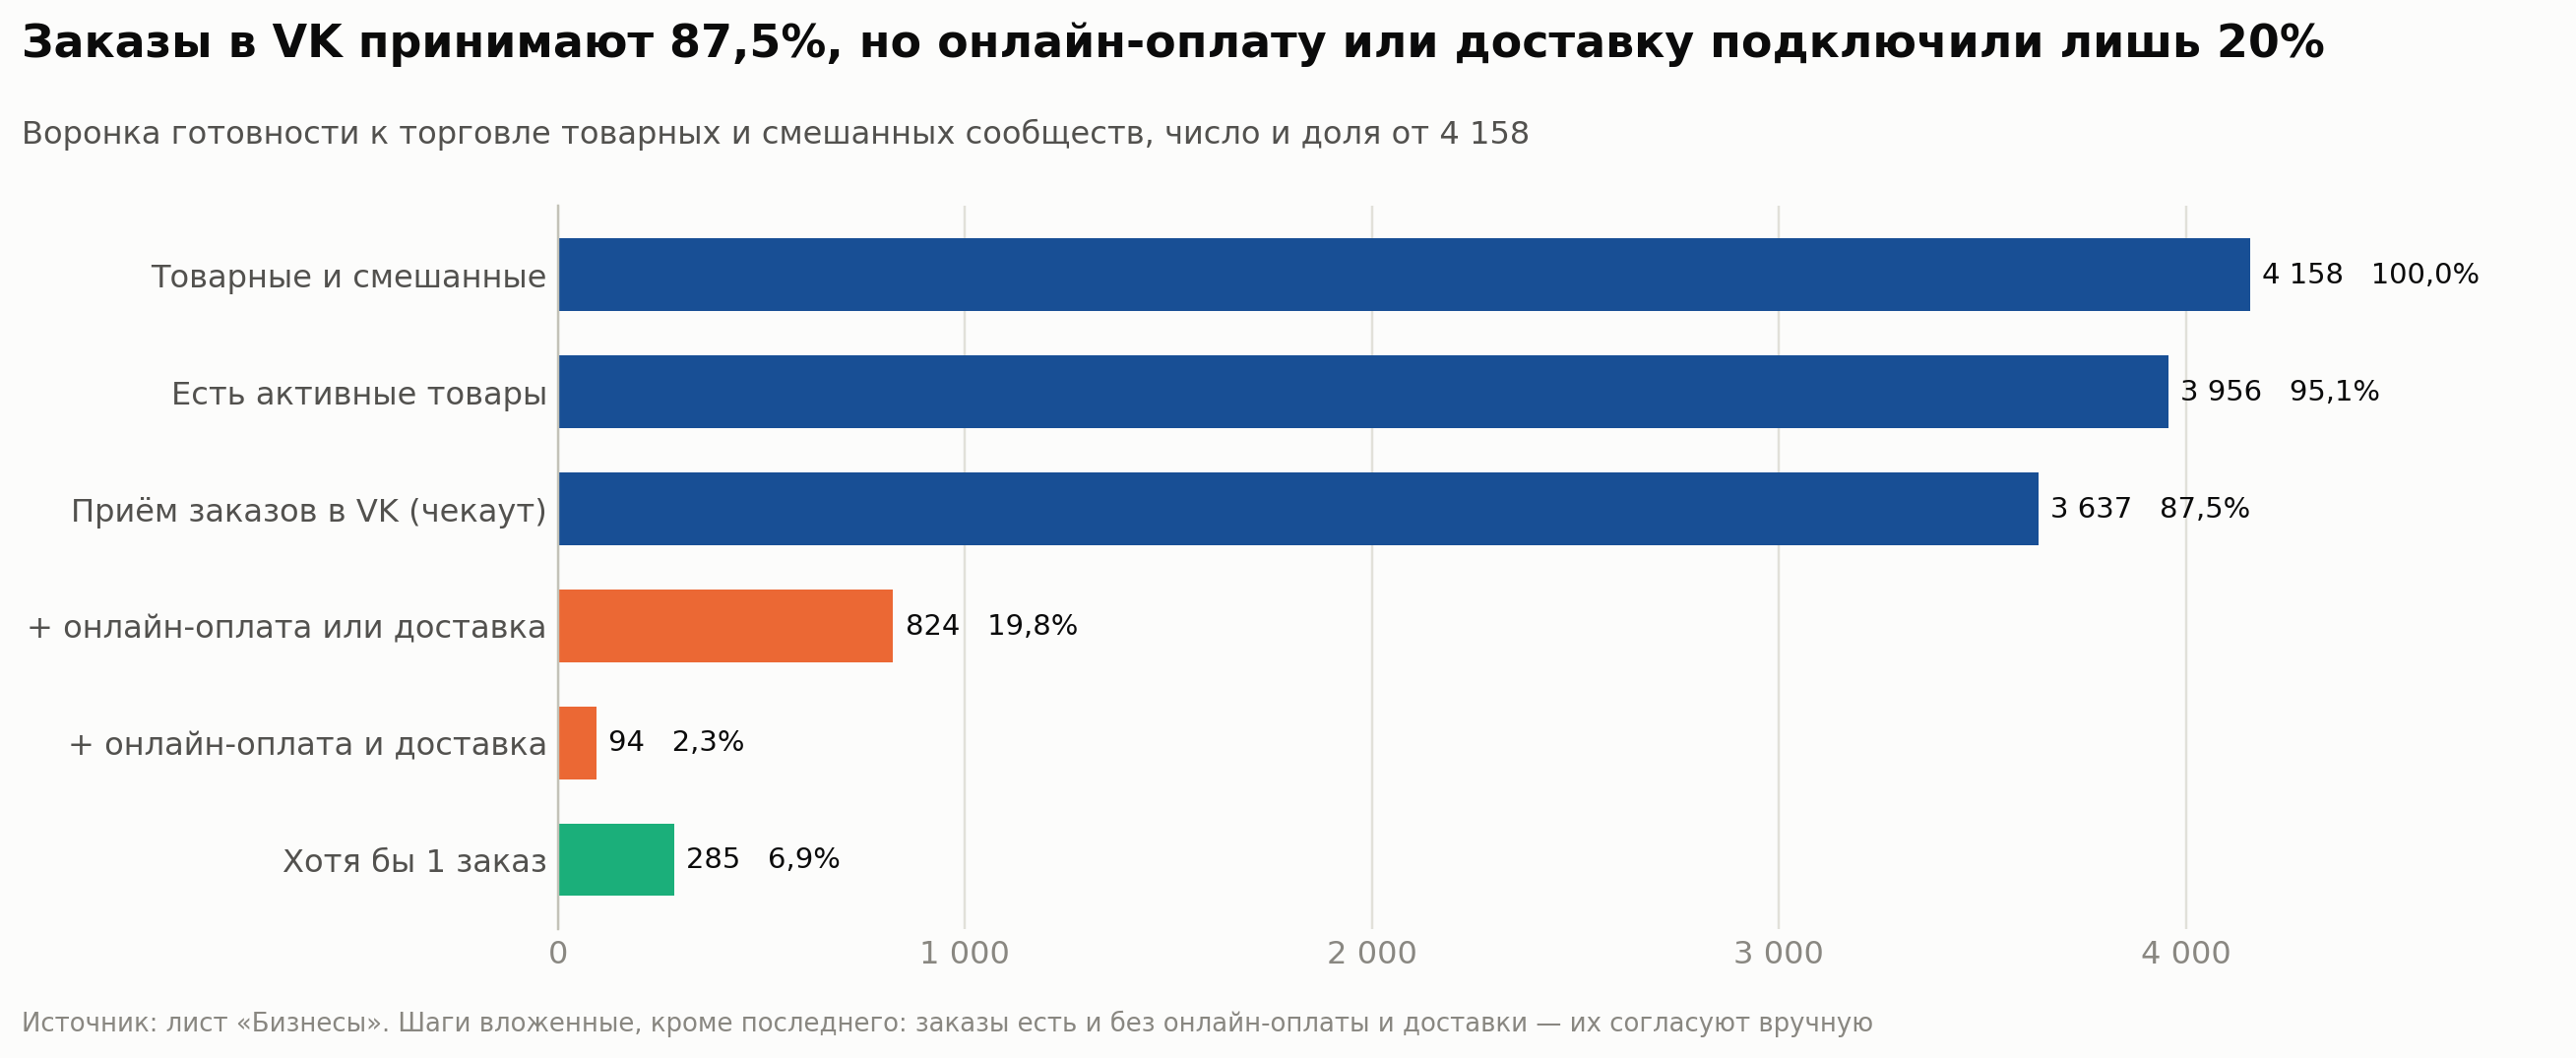

In [7]:
steps = pd.Series({
    "Товарные и смешанные": len(goods),
    "Есть активные товары": (goods.active > 0).sum(),
    "Приём заказов в VK (чекаут)": ((goods.active > 0) & (goods.checkout == 1)).sum(),
    "+ онлайн-оплата или доставка": ((goods.active > 0) & (goods.checkout == 1) & ((goods.delivery == 1) | (goods.payment == 1))).sum(),
    "+ онлайн-оплата и доставка": ((goods.active > 0) & (goods.checkout == 1) & (goods.delivery == 1) & (goods.payment == 1)).sum(),
    "Хотя бы 1 заказ": goods.has_order.sum(),
})
fig, ax = plt.subplots(figsize=(12, 4.8))
colors = [SEQ[5]] * 3 + [CAT[1]] * 2 + [CAT[2]]
bars = ax.barh(steps.index, steps.values, color=colors, height=0.62)
hbar_labels(ax, bars, [f"{ru(v)}   {pct(v / steps.iloc[0], 1)}" for v in steps.values])
ax.invert_yaxis(); ax.set_xlim(0, steps.max() * 1.18); hgrid(ax)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: ru(v)))
finish(fig, "Заказы в VK принимают 87,5%, но онлайн-оплату или доставку подключили лишь 20%",
       "Воронка готовности к торговле товарных и смешанных сообществ, число и доля от 4 158",
       "Источник: лист «Бизнесы». Шаги вложенные, кроме последнего: заказы есть и без онлайн-оплаты и доставки — их согласуют вручную")

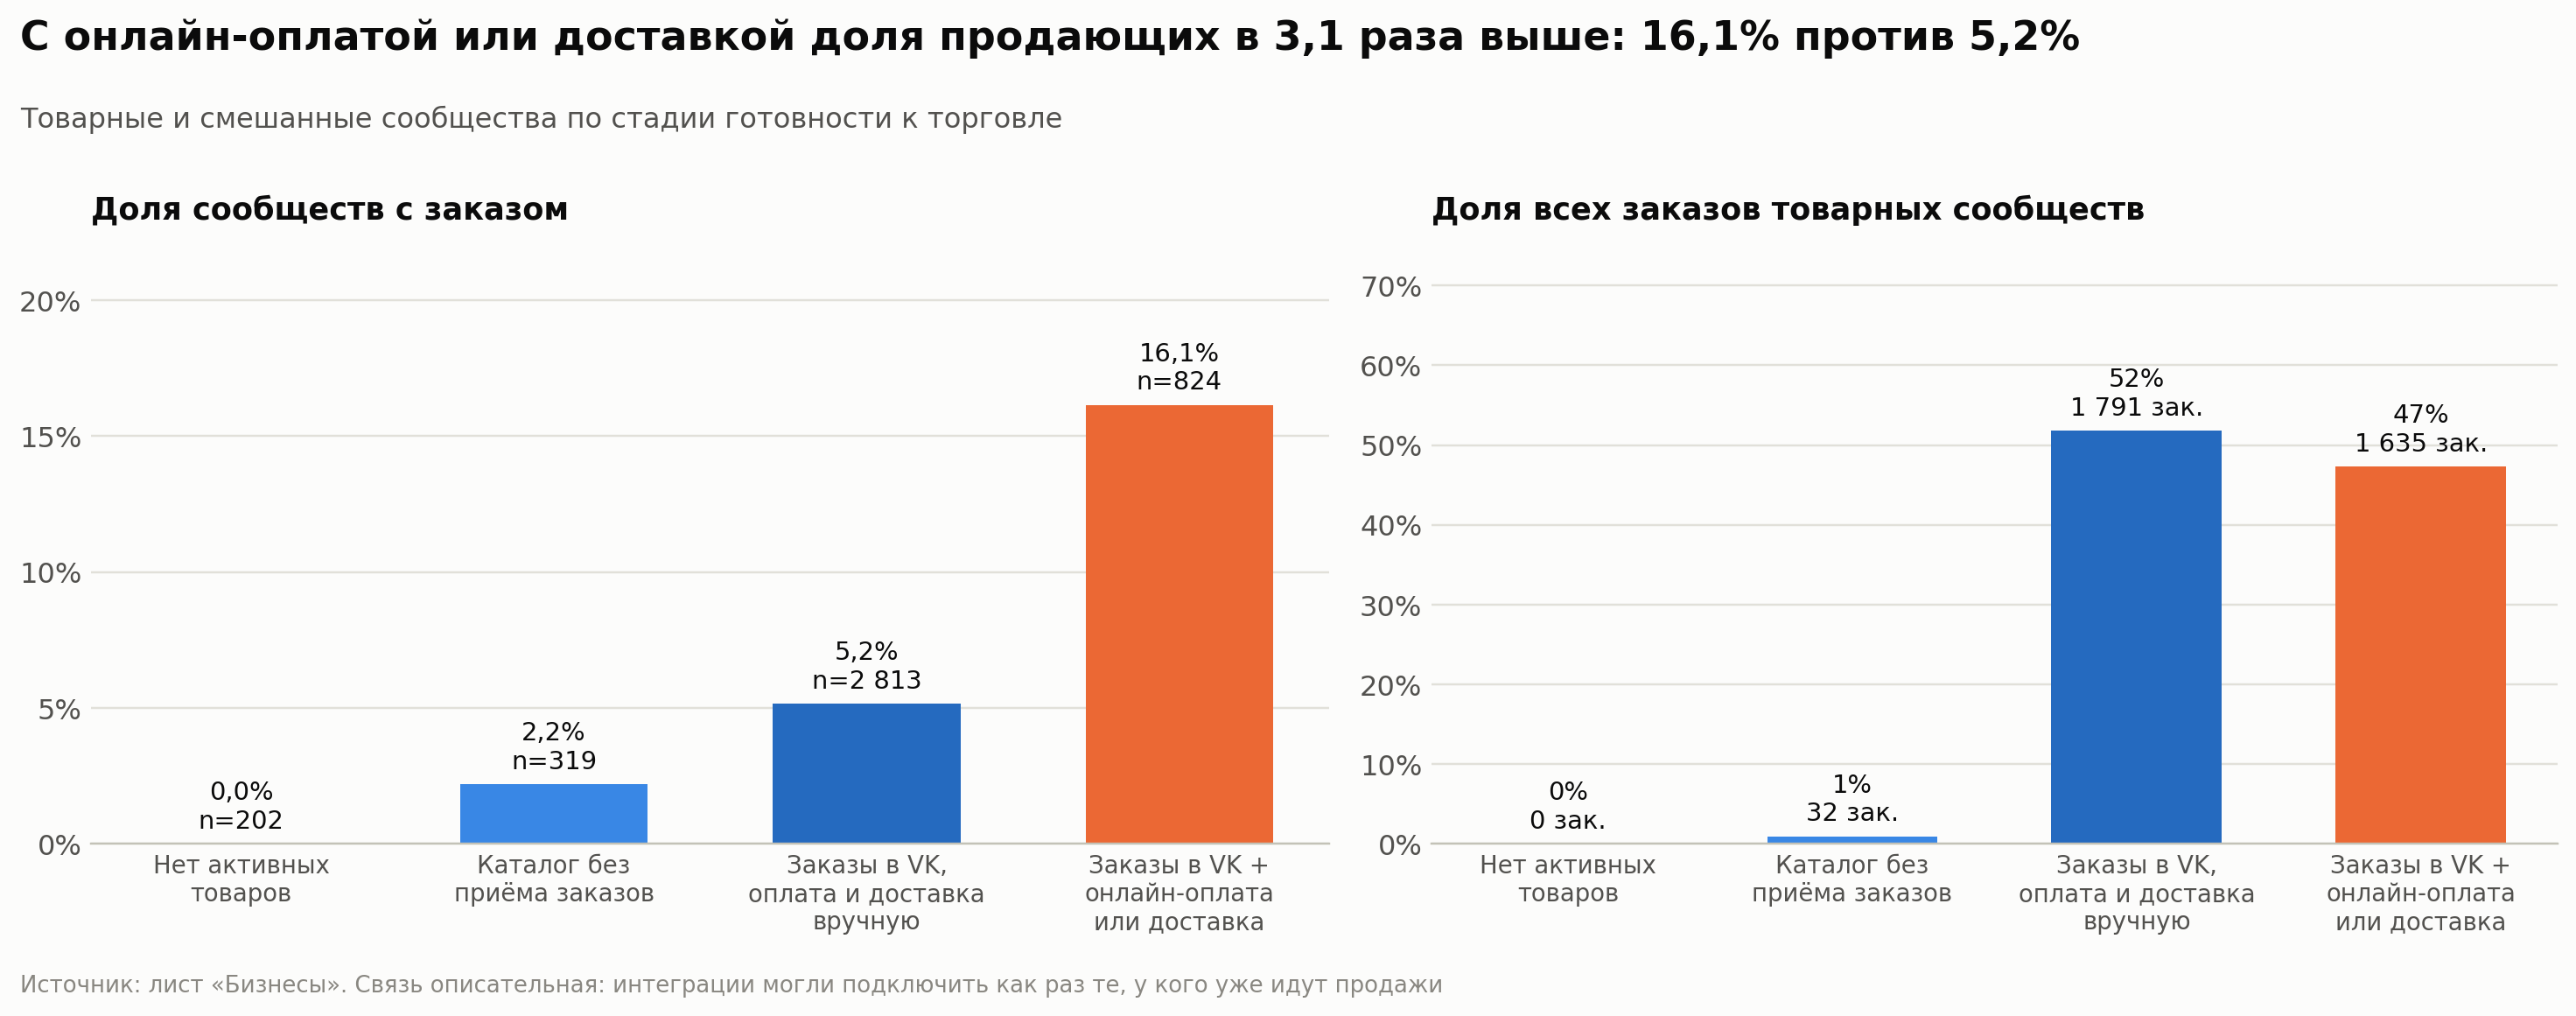

,сообществ,доля с заказом,заказов,продающих,заказов на продающего
stage,,,,,
1. Нет активных товаров,202,"0,0%",0,0,NaN
2. Каталог без приёма заказов,319,"2,2%",32,7,4.6
"3. Заказы в VK, оплата и доставка вручную",2813,"5,2%",1791,145,12.4
4. Заказы в VK + онлайн-оплата или доставка,824,"16,1%",1635,133,12.3


In [8]:
def stage(d):
    return np.select(
        [d.active == 0, d.checkout == 0, (d.delivery == 0) & (d.payment == 0)],
        ["1. Нет активных товаров", "2. Каталог без приёма заказов", "3. Заказы в VK, оплата и доставка вручную"],
        default="4. Заказы в VK + онлайн-оплата или доставка")
goods["stage"] = stage(goods)
st = goods.groupby("stage").agg(n=("id", "size"), rate=("has_order", "mean"), orders=("orders", "sum"),
                                sellers=("has_order", "sum"))
st["per_seller"] = st.orders / st.sellers.replace(0, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
labels = ["Нет активных\nтоваров", "Каталог без\nприёма заказов", "Заказы в VK,\nоплата и доставка\nвручную", "Заказы в VK +\nонлайн-оплата\nили доставка"]
bars = ax.bar(labels, st.rate, color=[SEQ[2], SEQ[3], SEQ[4], CAT[1]], width=0.6)
vbar_labels(ax, bars, [f"{pct(r)}\nn={ru(n)}" for r, n in zip(st.rate, st.n)])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_ylim(0, 0.22)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05)); ax.set_title("Доля сообществ с заказом")
ax = axes[1]
bars = ax.bar(labels, st.orders / st.orders.sum(), color=[SEQ[2], SEQ[3], SEQ[4], CAT[1]], width=0.6)
vbar_labels(ax, bars, [f"{pct(v, 0)}\n{ru(o)} зак." for v, o in zip(st.orders / st.orders.sum(), st.orders)])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_ylim(0, 0.75)
ax.set_title("Доля всех заказов товарных сообществ")
for a in axes: a.tick_params(axis="x", labelsize=9, colors=INK2)
lift = st.rate.iloc[3] / st.rate.iloc[2]
finish(fig, f"С онлайн-оплатой или доставкой доля продающих в {ru(lift, 1)} раза выше: {pct(st.rate.iloc[3])} против {pct(st.rate.iloc[2])}",
       "Товарные и смешанные сообщества по стадии готовности к торговле",
       "Источник: лист «Бизнесы». Связь описательная: интеграции могли подключить как раз те, у кого уже идут продажи")
st.assign(rate=st.rate.map(pct), per_seller=st.per_seller.round(1)).rename(columns={"n": "сообществ", "rate": "доля с заказом", "orders": "заказов", "sellers": "продающих", "per_seller": "заказов на продающего"})

### 2.2 Кто подключает онлайн-оплату и доставку

Почему 80% сообществ принимают заказы, но не подключают онлайн-оплату и доставку? Прямого ответа в данных нет: причины видны только в интервью и при прохождении настройки. Но данные показывают, **у кого** интеграции есть, а это сужает круг объяснений.

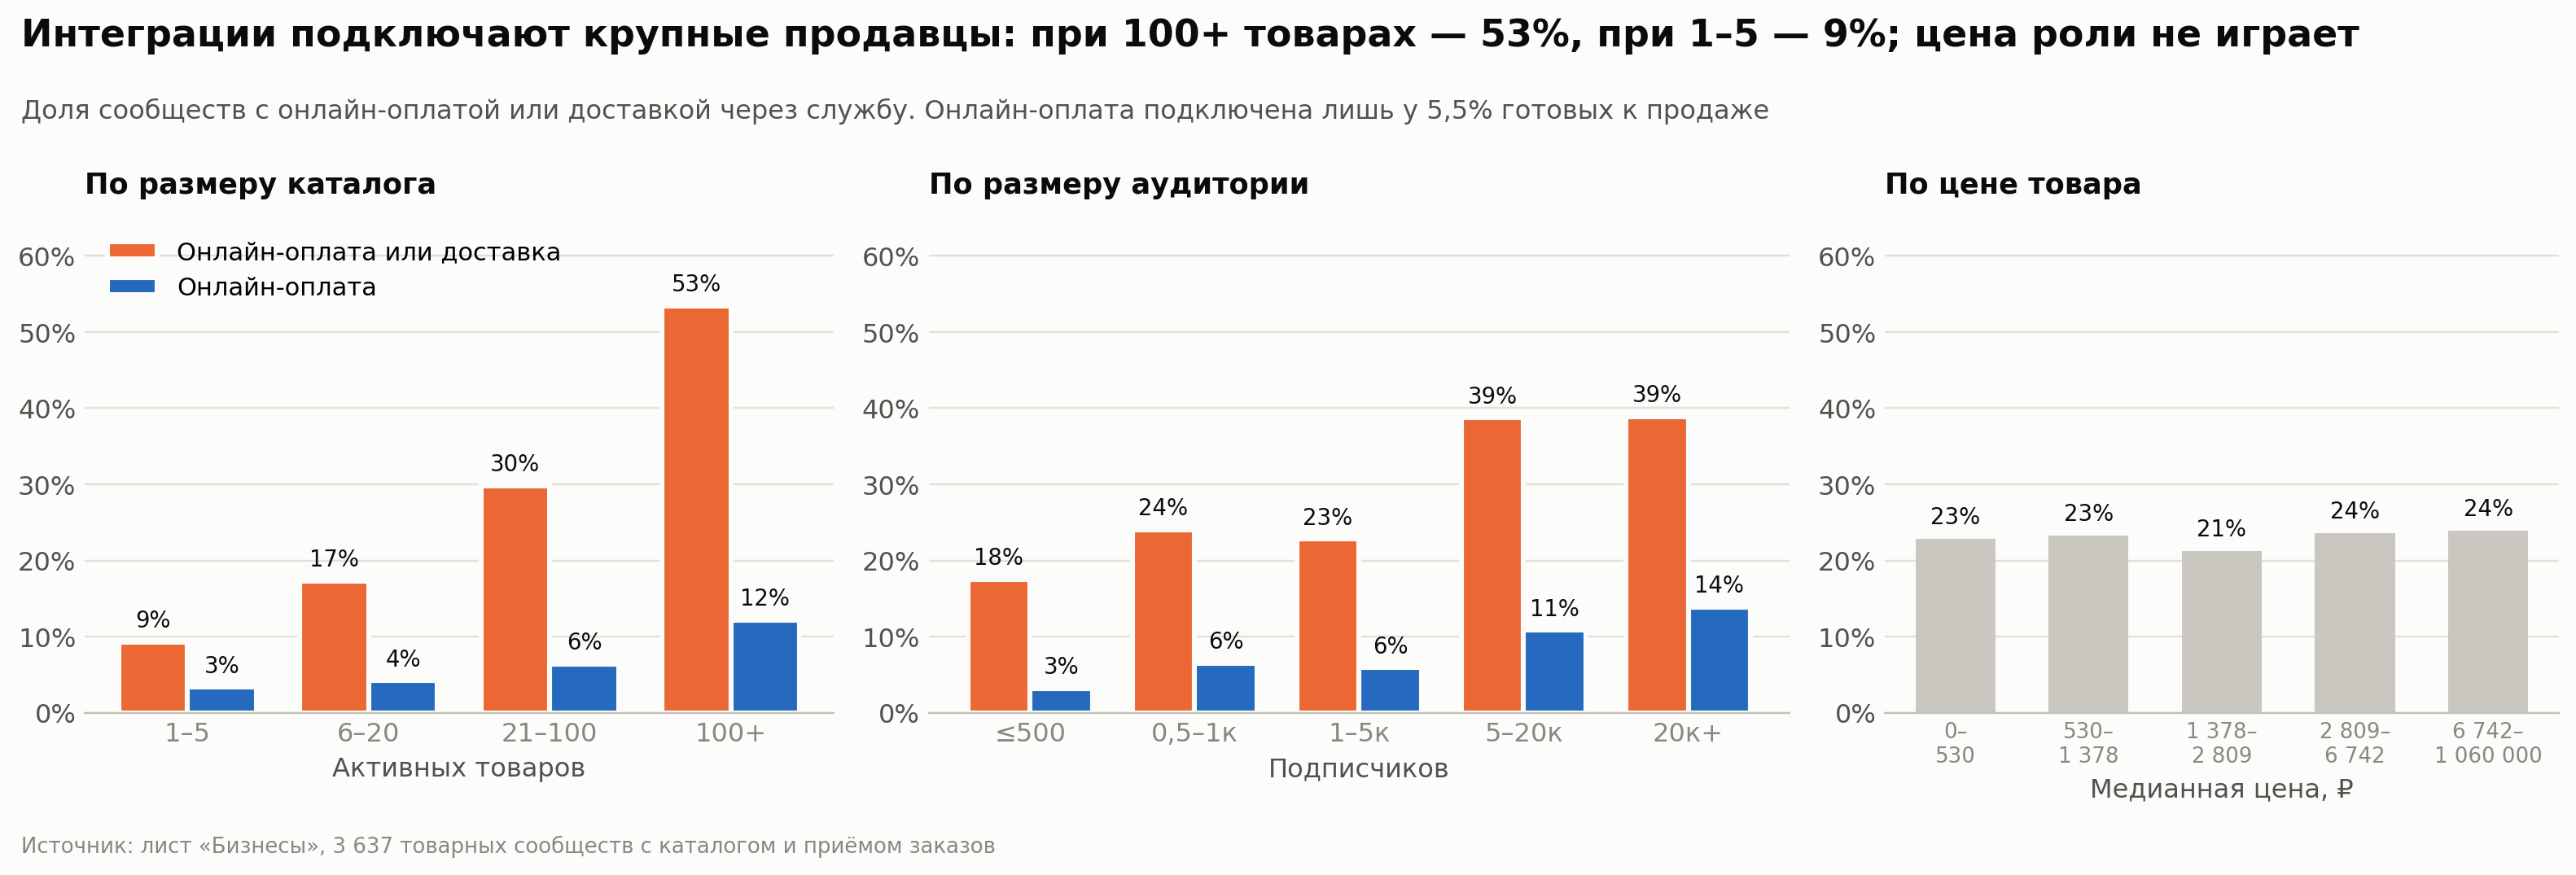

,продающих,заказов,медиана_заказов,среднее_заказов
Без онлайн-оплаты и доставки,145,1791,2.0,12.4
С онлайн-оплатой или доставкой,133,1635,2.0,12.3


In [9]:
r2 = goods[(goods.active > 0) & (goods.checkout == 1)].copy()
r2["integ"] = (r2.delivery == 1) | (r2.payment == 1)
by_cat = r2.groupby(pd.cut(r2.active, [0, 5, 20, 100, 1e9], labels=["1–5", "6–20", "21–100", "100+"]), observed=True).agg(
    n=("id", "size"), integ=("integ", "mean"), pay=("payment", "mean"))
by_sub = r2.groupby(pd.cut(r2.subs, [-1, 500, 1000, 5000, 20000, 1e9], labels=["≤500", "0,5–1к", "1–5к", "5–20к", "20к+"]), observed=True).agg(
    n=("id", "size"), integ=("integ", "mean"), pay=("payment", "mean"))
by_price = r2.groupby(pd.qcut(r2.price, 5), observed=True).agg(n=("id", "size"), integ=("integ", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.8), gridspec_kw={"width_ratios": [1, 1.15, 0.9]})
for ax, tab, title, xl in [(axes[0], by_cat, "По размеру каталога", "Активных товаров"),
                           (axes[1], by_sub, "По размеру аудитории", "Подписчиков")]:
    x = np.arange(len(tab)); w = 0.38
    b1 = ax.bar(x - w / 2, tab.integ, w, color=CAT[1], label="Онлайн-оплата или доставка", edgecolor=SURF, linewidth=2)
    b2 = ax.bar(x + w / 2, tab.pay, w, color=SEQ[4], label="Онлайн-оплата", edgecolor=SURF, linewidth=2)
    vbar_labels(ax, b1, [pct(v, 0) for v in tab.integ], fs=9); vbar_labels(ax, b2, [pct(v, 0) for v in tab.pay], fs=9)
    ax.set_xticks(x, tab.index.astype(str)); ax.set_xlabel(xl); ax.set_ylim(0, 0.65)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_title(title)
axes[0].legend(loc="upper left")
ax = axes[2]
lab = [f"{ru(max(i.left, 0))}–" + "\n" + f"{ru(i.right)}" for i in by_price.index]
bars = ax.bar(lab, by_price.integ, color="#c9c7c0", width=0.6)
vbar_labels(ax, bars, [pct(v, 0) for v in by_price.integ], fs=9)
ax.set_ylim(0, 0.65); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_xlabel("Медианная цена, ₽")
ax.set_title("По цене товара"); ax.tick_params(axis="x", labelsize=8.5)
finish(fig, f"Интеграции подключают крупные продавцы: при 100+ товарах — {pct(by_cat.integ.iloc[-1], 0)}, при 1–5 — {pct(by_cat.integ.iloc[0], 0)}; цена роли не играет",
       f"Доля сообществ с онлайн-оплатой или доставкой через службу. Онлайн-оплата подключена лишь у {pct(r2.payment.mean())} готовых к продаже",
       "Источник: лист «Бизнесы», 3 637 товарных сообществ с каталогом и приёмом заказов")

sell = r2[r2.has_order].groupby("integ").agg(продающих=("id", "size"), заказов=("orders", "sum"),
                                             медиана_заказов=("orders", "median"), среднее_заказов=("orders", "mean"))
sell.index = ["Без онлайн-оплаты и доставки", "С онлайн-оплатой или доставкой"]
sell.round(1)

**Что видно в данных:**

- Онлайн-оплату и доставку подключают **крупные и активные** продавцы: чем больше каталог и аудитория, тем выше доля. Цена товара почти ни на что не влияет — значит, дело не в том, что дешёвый товар «не окупает» доставку.
- **Онлайн-оплата — самое слабое звено** (около 5% против ~20% для доставки). На уровне Маркета внутри VK оплачено 1,2% заказов.
- Те, кто продаёт **без** интеграций, продают не меньше: медиана 2 заказа, в среднем 12 — как и у продавцов с интеграциями. Для уже продающего продавца ручная договорённость в переписке работает.
- Внутри одной группы по размеру аудитории сообщества с интеграциями продают в 2–3 раза чаще. Это не доказывает причину: у продавцов с потоком заказов больше поводов настроить интеграции.

**Три объяснения, которые надо проверить интервью и прохождением настройки:**

| Объяснение | Чьё «упущение» | Что за него в данных | Как проверить |
|---|---|---|---|
| Продавцу не нужно: заказов мало, удобнее договориться в сообщениях, есть свои способы оплаты и отправки | Ни чьё — рациональный выбор продавца | Продающие без интеграций продают столько же; интеграции растут вместе с размером | Интервью: как продавец сейчас принимает оплату и отправляет заказ |
| Настройка сложная или требует условий (статус ИП/самозанятого, договор, габариты товаров, касса) | Платформа: высокий порог входа | Онлайн-оплата у 5% против ~20% у доставки; малые каталоги почти не подключают | Пройти настройку Магазина 2.0 самим, вопрос на Q&A |
| Продавец не знает о возможностях или не видит выгоды: инструменты не связаны в один путь | Платформа: обнаружимость и коммуникация | Бриф: «инструментов немало, но они не складываются в целостный опыт» | Тест понятности, интервью, A/B-подсказка в кабинете |

Скорее всего, работают все три, а доля каждого разная для разных сегментов. Решение кейса — путь, который снимает их по очереди: показать выгоду, упростить подключение, дать первый спрос.

### 2.3 Концентрация продаж

Большинство продающих сообществ получают 1–2 заказа в месяц, а основной объём делают несколько крупных продавцов. Любые средние по выборке нужно читать с этой поправкой.

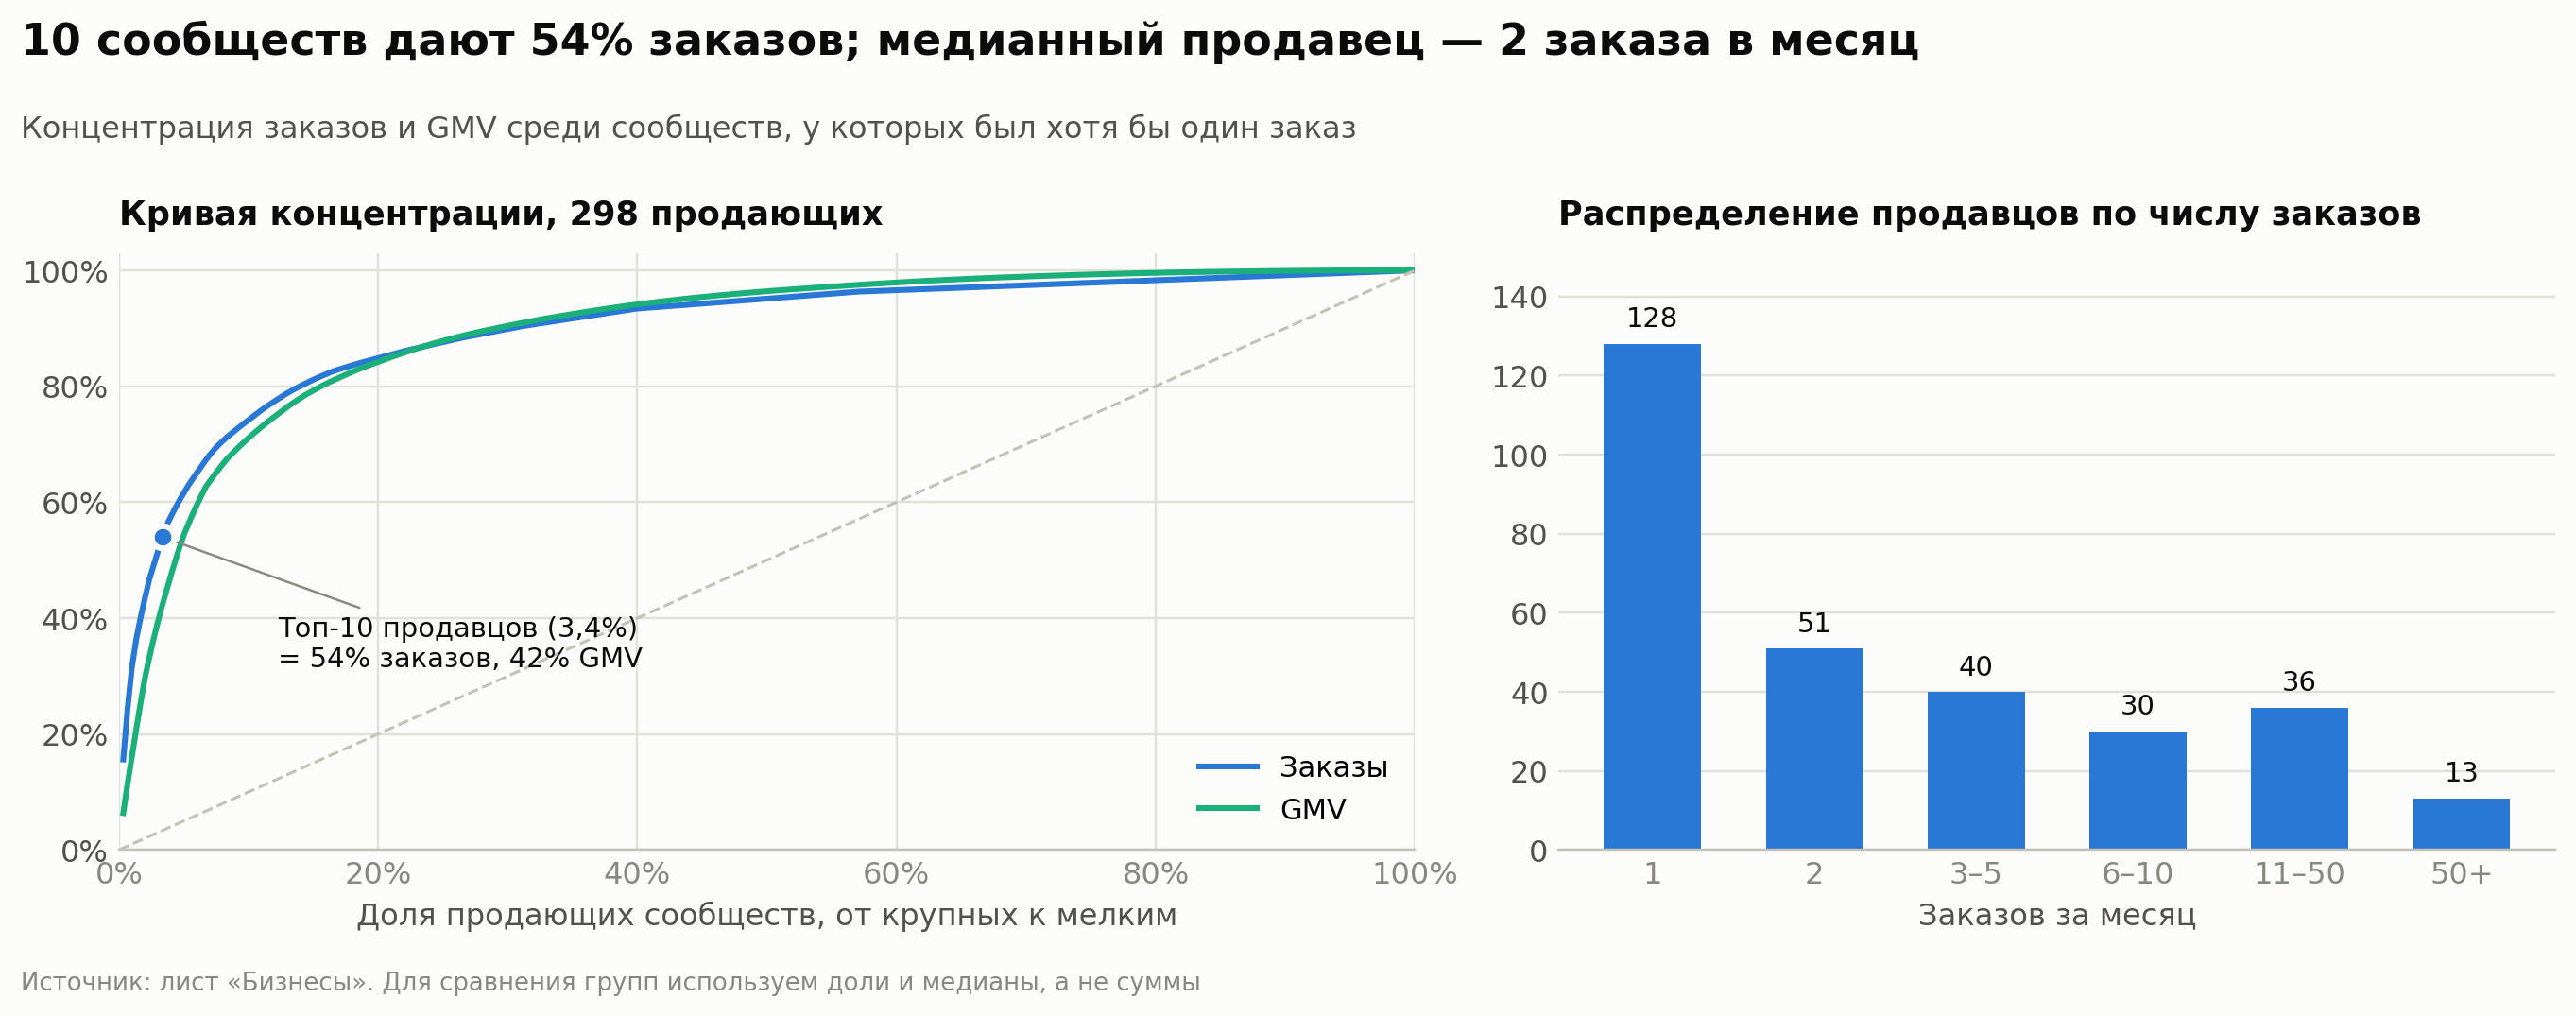

In [10]:
sellers = biz[biz.has_order].sort_values("orders", ascending=False)
cum_o = sellers.orders.cumsum() / sellers.orders.sum()
cum_g = sellers.sort_values("gmv", ascending=False).gmv.cumsum() / sellers.gmv.sum()
x = np.arange(1, len(sellers) + 1) / len(sellers)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.plot(x, cum_o.values, color=VK, label="Заказы")
ax.plot(x, cum_g.values, color=CAT[2], label="GMV")
ax.plot([0, 1], [0, 1], color=BASE, lw=1, ls="--")
top10_o, top10_g = cum_o.iloc[9], cum_g.iloc[9]
ax.scatter([10 / len(sellers)], [top10_o], s=60, color=VK, edgecolor=SURF, linewidth=2, zorder=5)
ax.annotate(f"Топ-10 продавцов ({pct(10 / len(sellers))})\n= {pct(top10_o, 0)} заказов, {pct(top10_g, 0)} GMV",
            (10 / len(sellers), top10_o), xytext=(40, -45), textcoords="offset points", fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Доля продающих сообществ, от крупных к мелким"); ax.set_ylim(0, 1.03); ax.set_xlim(0, 1)
ax.legend(loc="lower right"); ax.grid(axis="x", color=GRID)
ax.set_title(f"Кривая концентрации, {ru(len(sellers))} продающих")

ax = axes[1]
bins = pd.cut(sellers.orders, [0, 1, 2, 5, 10, 50, 1e6], labels=["1", "2", "3–5", "6–10", "11–50", "50+"])
cnt = bins.value_counts().sort_index()
bars = ax.bar(cnt.index.astype(str), cnt.values, color=VK, width=0.6)
vbar_labels(ax, bars, [ru(v) for v in cnt.values])
ax.set_xlabel("Заказов за месяц"); ax.set_ylim(0, cnt.max() * 1.18)
ax.set_title("Распределение продавцов по числу заказов")
finish(fig, f"10 сообществ дают {pct(top10_o, 0)} заказов; медианный продавец — {ru(sellers.orders.median())} заказа в месяц",
       "Концентрация заказов и GMV среди сообществ, у которых был хотя бы один заказ",
       "Источник: лист «Бизнесы». Для сравнения групп используем доли и медианы, а не суммы")

## 3. Что связано с наличием заказов

Сравниваем долю сообществ с заказом в разрезе характеристик — **только товарные и смешанные, которые принимают заказы в VK и имеют активные товары** (3 637), чтобы не смешивать «не может продавать» и «не продаёт».

In [11]:
ready = goods[(goods.active > 0) & (goods.checkout == 1)].copy()
base_rate = ready.has_order.mean()
print(f"База сравнения: {ru(len(ready))} сообществ, доля с заказом {pct(base_rate)}")

def rate_by(d, col, bins=None, labels=None):
    key = pd.cut(d[col], bins, labels=labels) if bins is not None else d[col]
    return d.groupby(key, observed=True).agg(n=("id", "size"), rate=("has_order", "mean"), orders=("orders", "sum"))

def rate_panel(ax, tab, title, color=VK, xlabel=None):
    bars = ax.bar(tab.index.astype(str), tab.rate, color=color, width=0.62)
    vbar_labels(ax, bars, [f"{pct(r, 0)}\nn={ru(n)}" for r, n in zip(tab.rate, tab.n)], fs=9)
    ax.axhline(base_rate, color=MUTED, lw=1, ls="--")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_ylim(0, max(tab.rate.max() * 1.35, 0.1))
    ax.set_title(title); ax.tick_params(axis="x", labelsize=9, colors=INK2)
    if xlabel: ax.set_xlabel(xlabel)

База сравнения: 3 637 сообществ, доля с заказом 7,6%


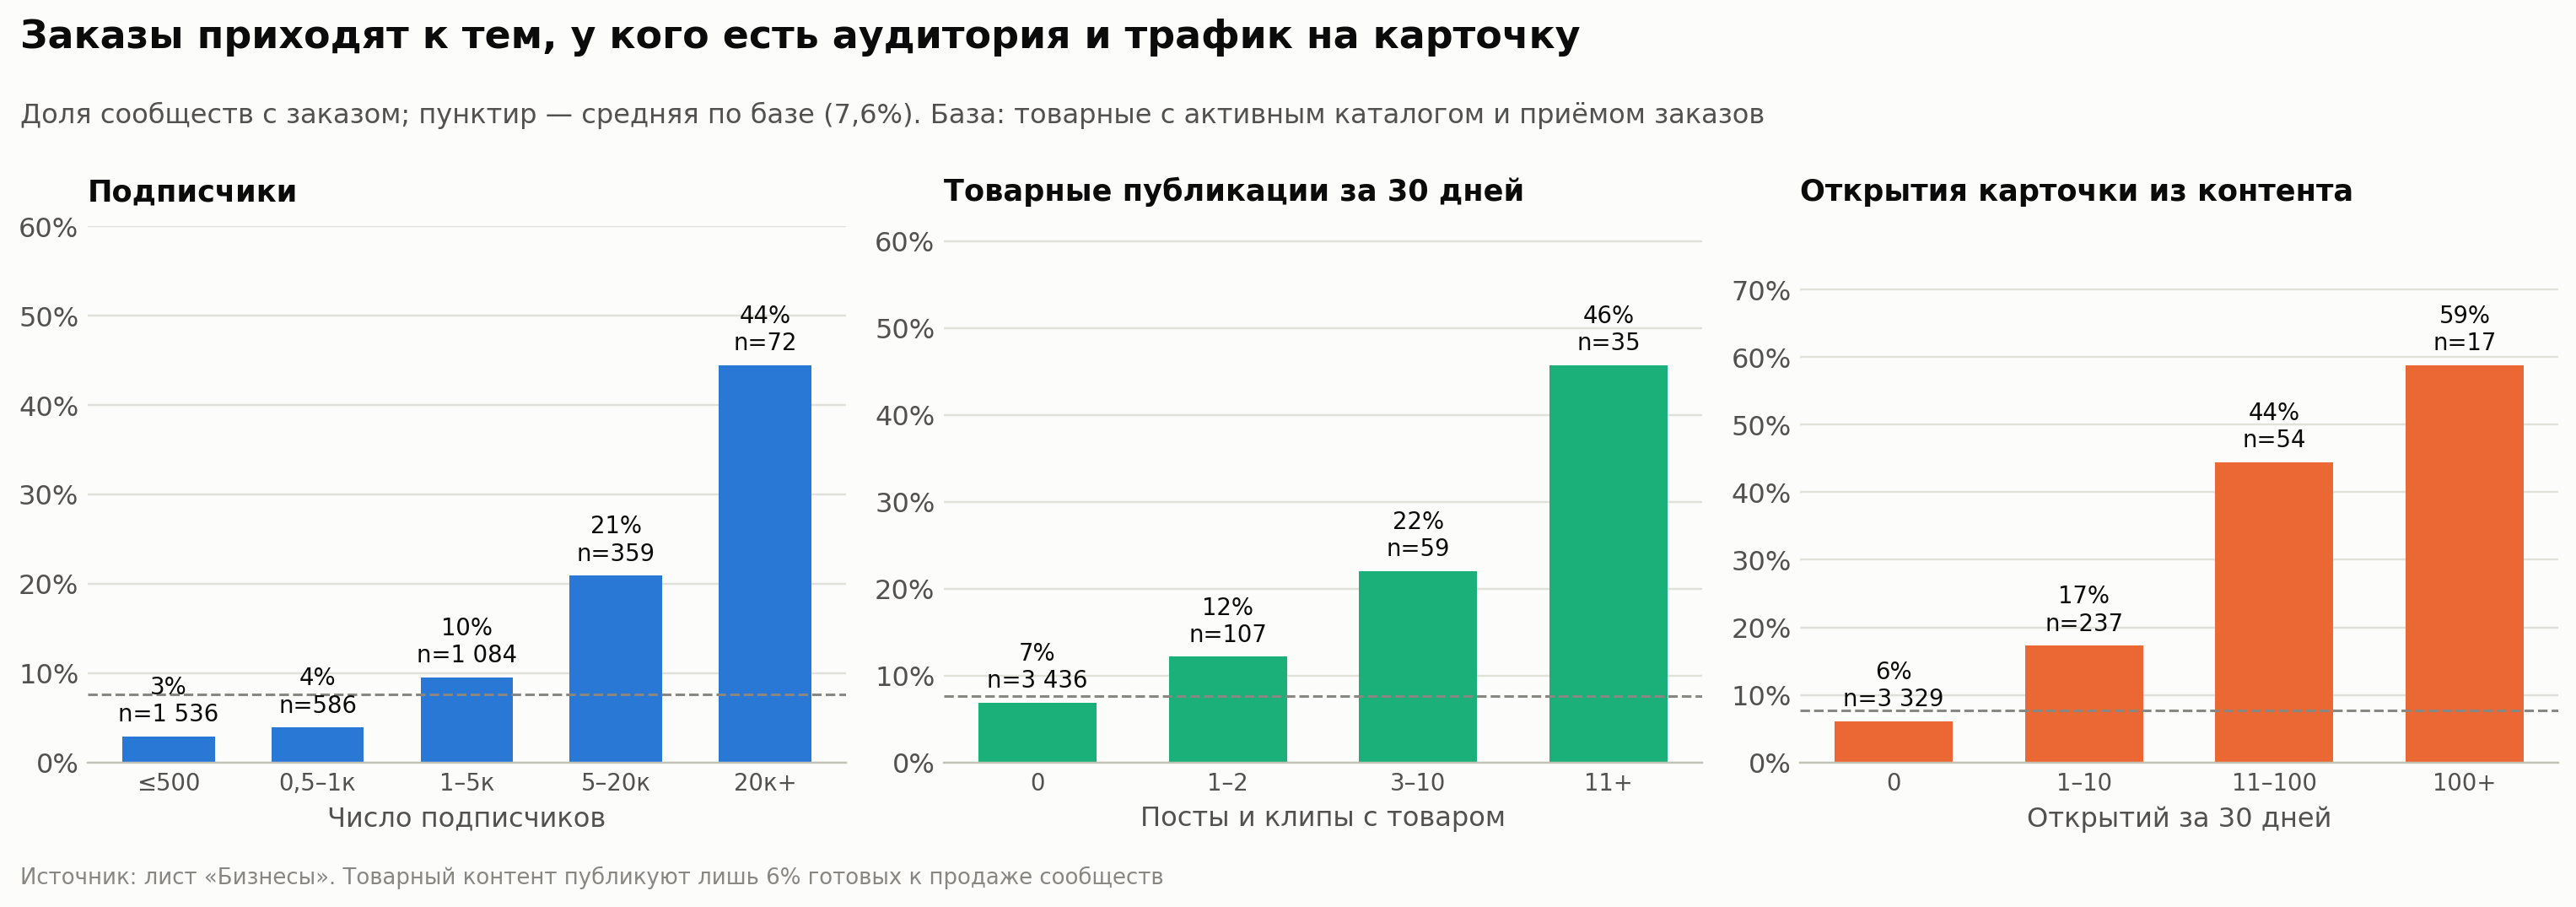

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
rate_panel(axes[0], rate_by(ready, "subs", [-1, 500, 1000, 5000, 20000, 1e9], ["≤500", "0,5–1к", "1–5к", "5–20к", "20к+"]),
           "Подписчики", xlabel="Число подписчиков")
rate_panel(axes[1], rate_by(ready, "pubs_p", [-1, 0, 2, 10, 1e9], ["0", "1–2", "3–10", "11+"]),
           "Товарные публикации за 30 дней", color=CAT[2], xlabel="Посты и клипы с товаром")
rate_panel(axes[2], rate_by(ready, "opens", [-1, 0, 10, 100, 1e9], ["0", "1–10", "11–100", "100+"]),
           "Открытия карточки из контента", color=CAT[1], xlabel="Открытий за 30 дней")
finish(fig, "Заказы приходят к тем, у кого есть аудитория и трафик на карточку",
       f"Доля сообществ с заказом; пунктир — средняя по базе ({pct(base_rate)}). База: товарные с активным каталогом и приёмом заказов",
       "Источник: лист «Бизнесы». Товарный контент публикуют лишь "
       + pct((ready.pubs_p > 0).mean(), 0) + " готовых к продаже сообществ")

### 3.1 Распространяется ли товарный контент хуже обычного?

В брифе это заявлено как проблема. Проверяем на сообществах, у которых за месяц были **и обычные, и товарные публикации**: просмотры на одну публикацию и вовлечённость (лайки / просмотры).

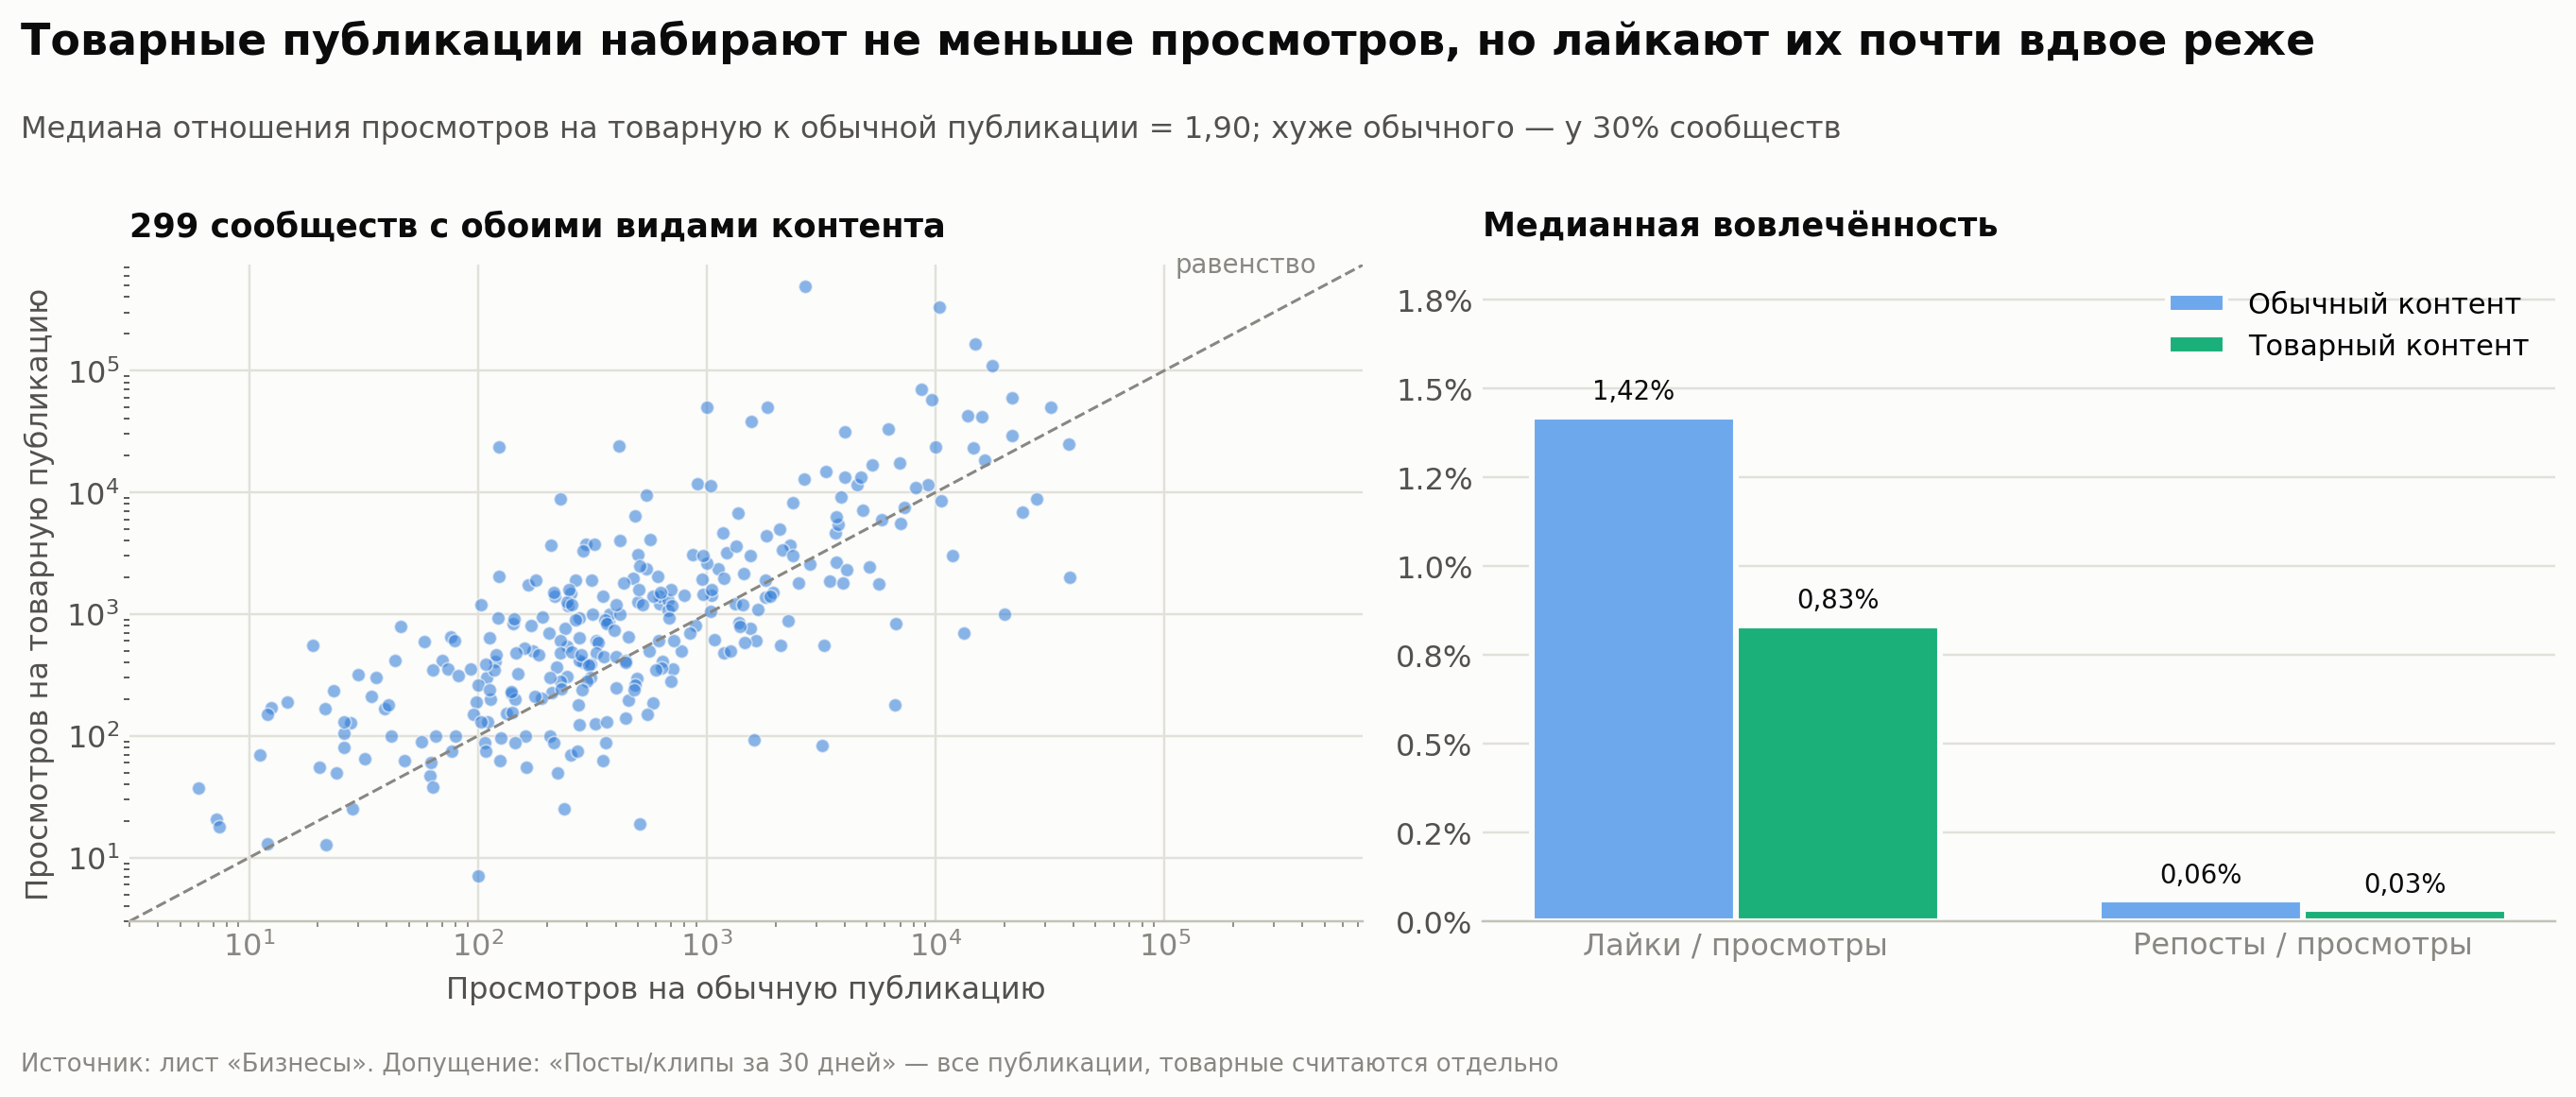

Открытий карточки на 1 000 просмотров товарного контента (вся выборка): 2,89


In [13]:
both = biz[(biz.pubs > 0) & (biz.pubs_p > 0) & (biz.v_reg > 0) & (biz.v_prod > 0)].copy()
both["vpp_reg"] = both.v_reg / both.pubs
both["vpp_prod"] = both.v_prod / both.pubs_p
both["er_reg"] = both.l_reg / both.v_reg
both["er_prod"] = both.l_prod / both.v_prod
ratio = (both.vpp_prod / both.vpp_reg)
share_worse = (ratio < 1).mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
ax.scatter(both.vpp_reg, both.vpp_prod, s=22, color=VK, alpha=0.55, edgecolor=SURF, linewidth=0.6)
lim = [3, max(both.vpp_reg.max(), both.vpp_prod.max()) * 1.5]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--"); ax.text(lim[1] / 1.6, lim[1] / 1.15, "равенство", color=MUTED, fontsize=9, ha="right")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Просмотров на обычную публикацию"); ax.set_ylabel("Просмотров на товарную публикацию")
ax.grid(axis="x", color=GRID); ax.set_title(f"{ru(len(both))} сообществ с обоими видами контента")

ax = axes[1]
m = pd.DataFrame({"Обычный": [both.er_reg.median(), (both.r_reg / both.v_reg).median()],
                  "Товарный": [both.er_prod.median(), (both.r_prod / both.v_prod).median()]},
                 index=["Лайки / просмотры", "Репосты / просмотры"])
xx = np.arange(len(m)); w = 0.36
b1 = ax.bar(xx - w / 2, m["Обычный"], w, color=SEQ[2], label="Обычный контент", edgecolor=SURF, linewidth=2)
b2 = ax.bar(xx + w / 2, m["Товарный"], w, color=CAT[2], label="Товарный контент", edgecolor=SURF, linewidth=2)
vbar_labels(ax, b1, [pct(v, 2) for v in m["Обычный"]], fs=9); vbar_labels(ax, b2, [pct(v, 2) for v in m["Товарный"]], fs=9)
ax.set_xticks(xx, m.index); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_ylim(0, m.values.max() * 1.3); ax.legend(loc="upper right"); ax.set_title("Медианная вовлечённость")
finish(fig, f"Товарные публикации набирают не меньше просмотров, но лайкают их почти вдвое реже",
       f"Медиана отношения просмотров на товарную к обычной публикации = {ru(ratio.median(), 2)}; хуже обычного — у {pct(share_worse, 0)} сообществ",
       "Источник: лист «Бизнесы». Допущение: «Посты/клипы за 30 дней» — все публикации, товарные считаются отдельно")
print(f"Открытий карточки на 1 000 просмотров товарного контента (вся выборка): {ru(1000 * biz.opens.sum() / biz.v_prod.sum(), 2)}")

### 3.2 Тематика, реклама, рефералка, оригинальность, цена

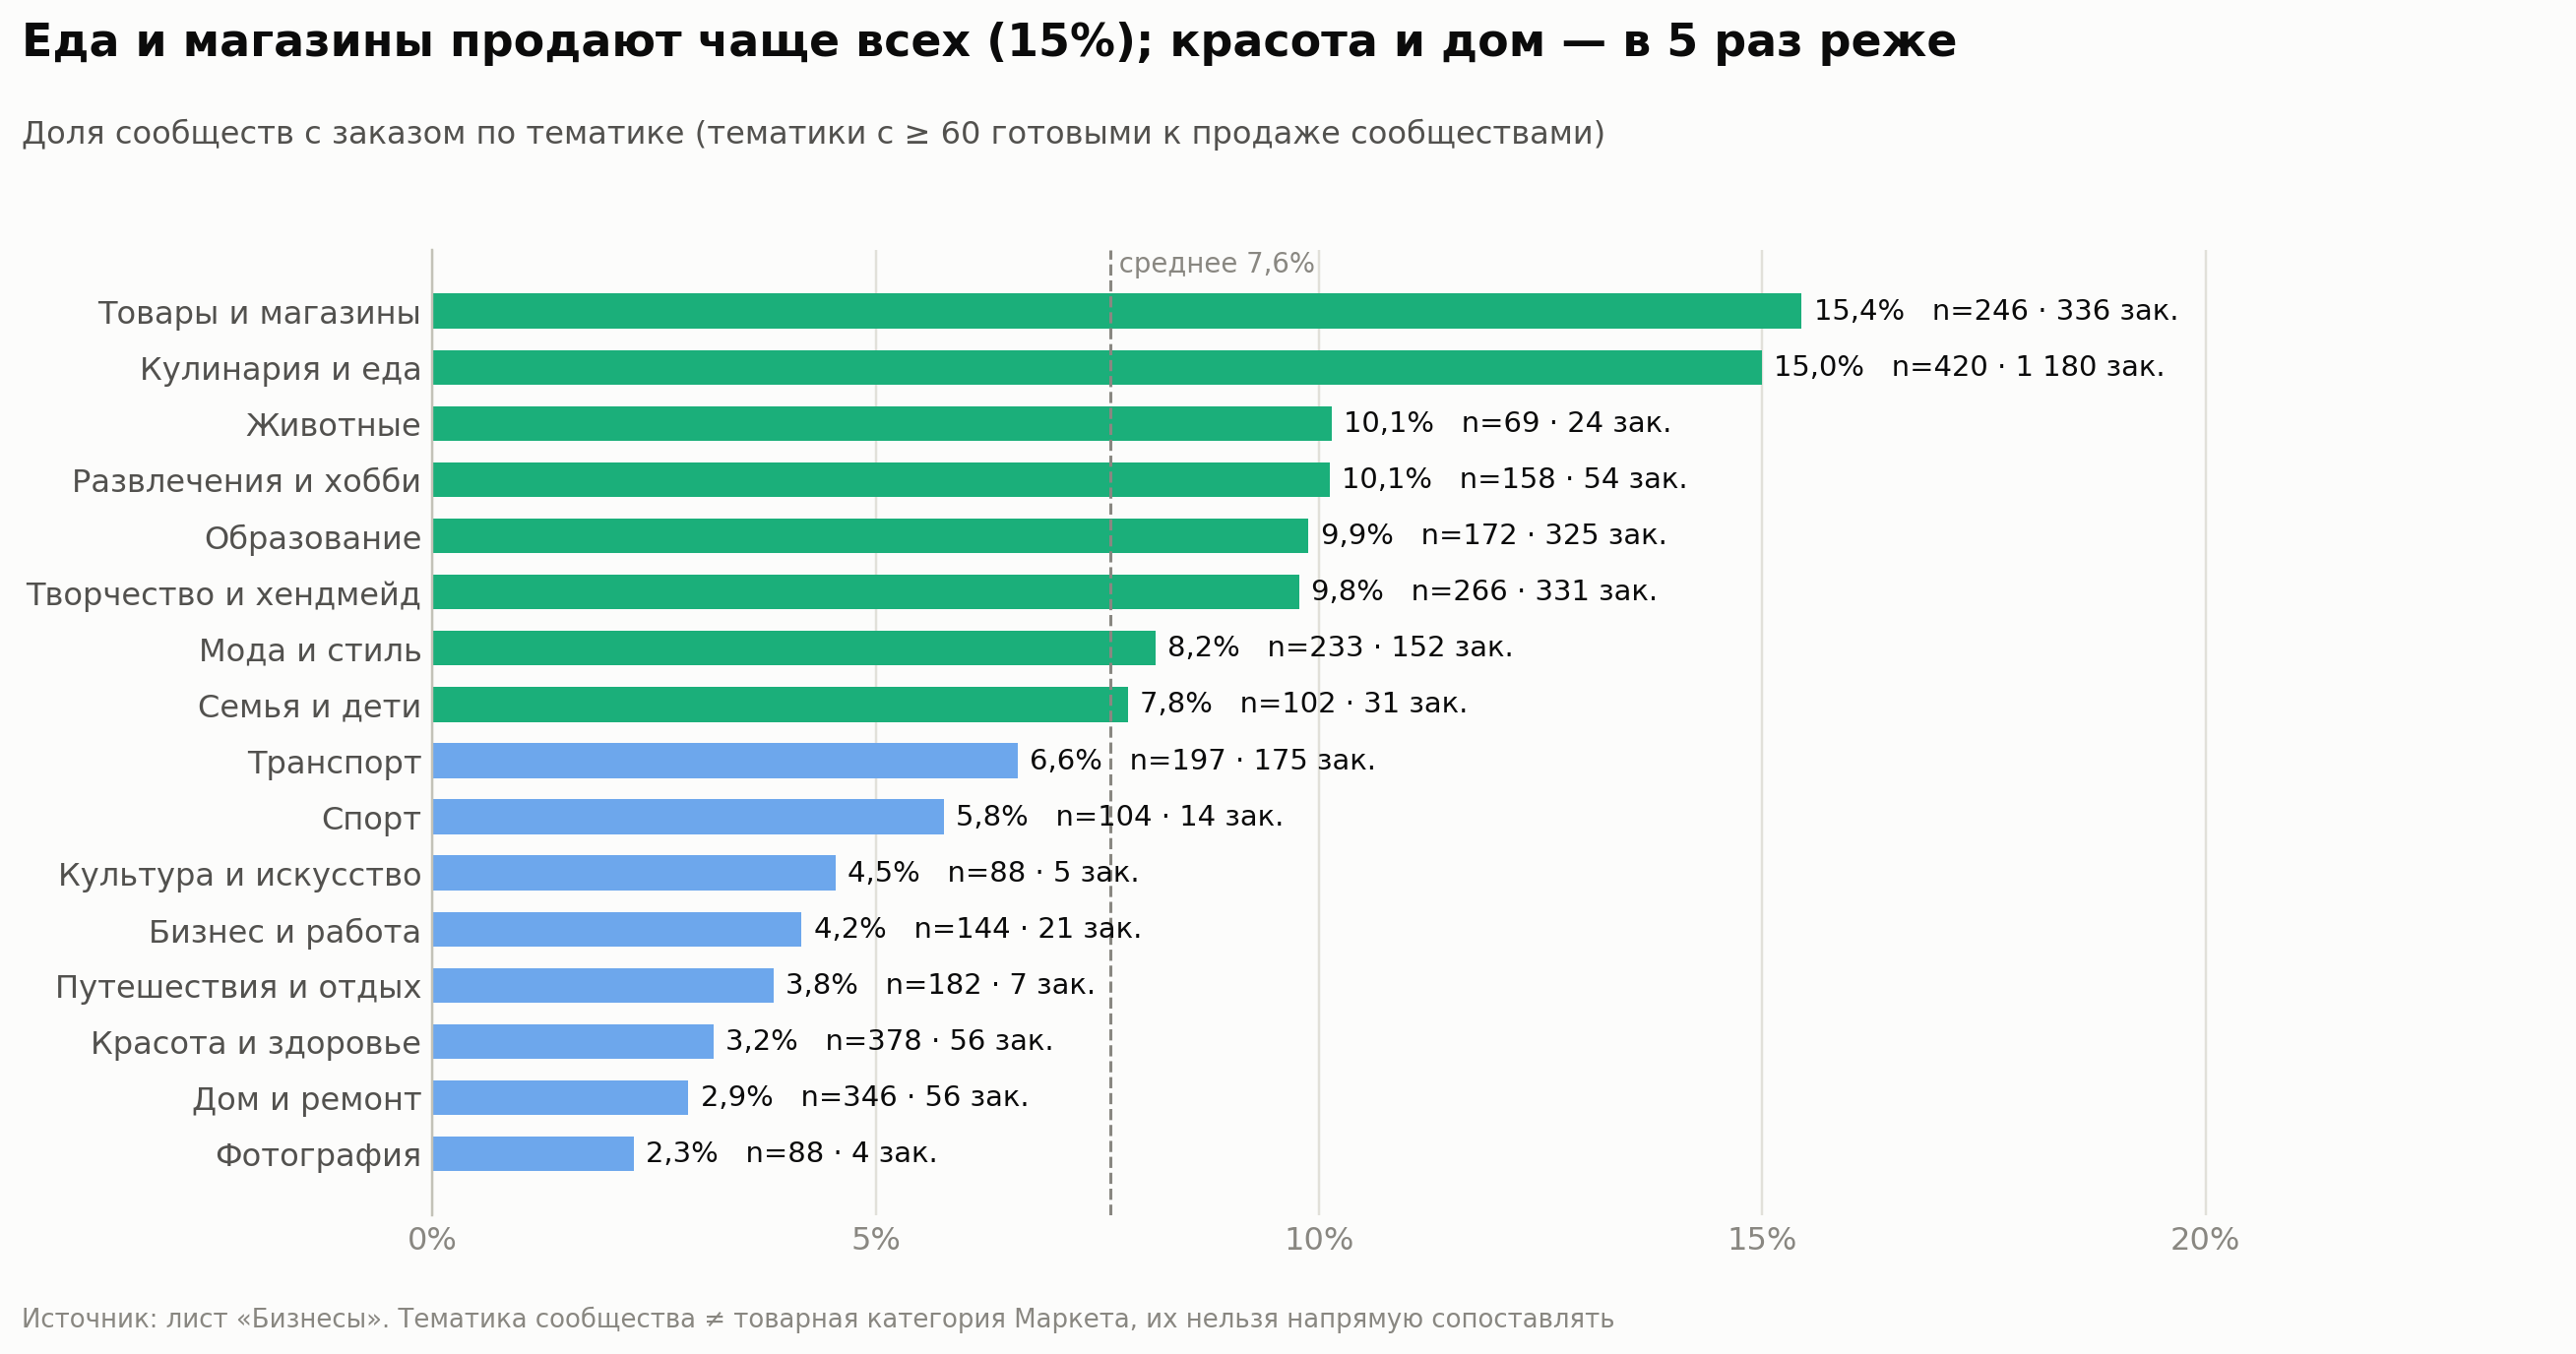

In [14]:
top_topics = rate_by(ready, "topic").query("n >= 60").sort_values("rate")
fig, ax = plt.subplots(figsize=(12, 6.2))
colors = [CAT[2] if r > base_rate else SEQ[2] for r in top_topics.rate]
bars = ax.barh(top_topics.index, top_topics.rate, color=colors, height=0.62)
hbar_labels(ax, bars, [f"{pct(r)}   n={ru(n)} · {ru(o)} зак." for r, n, o in zip(top_topics.rate, top_topics.n, top_topics.orders)])
ax.axvline(base_rate, color=MUTED, lw=1, ls="--"); ax.text(base_rate, len(top_topics) - 0.3, f" среднее {pct(base_rate)}", color=MUTED, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_xlim(0, top_topics.rate.max() * 1.55); hgrid(ax)
finish(fig, "Еда и магазины продают чаще всех (15%); красота и дом — в 5 раз реже",
       "Доля сообществ с заказом по тематике (тематики с ≥ 60 готовыми к продаже сообществами)",
       "Источник: лист «Бизнесы». Тематика сообщества ≠ товарная категория Маркета, их нельзя напрямую сопоставлять")

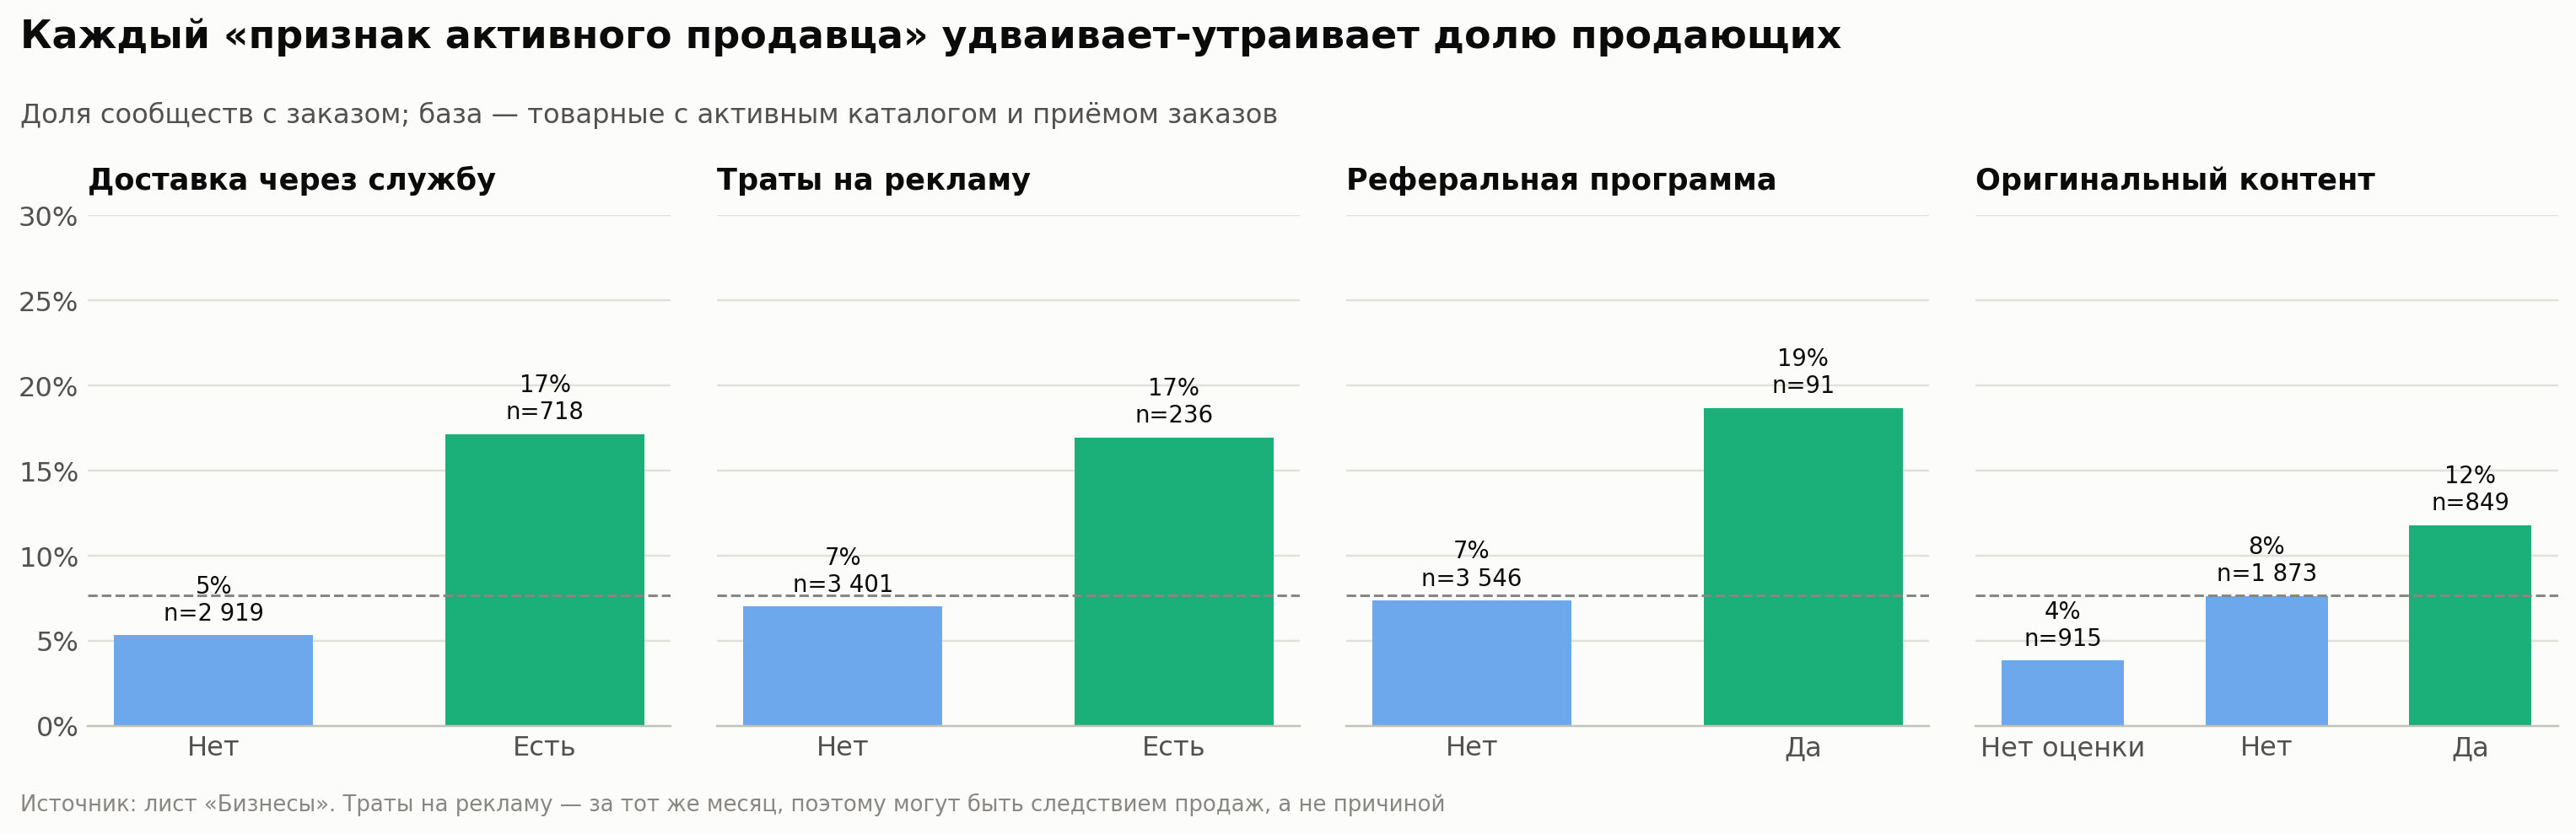

In [15]:
ready["ads_flag"] = np.where(ready.ads > 0, "Есть", "Нет")
ready["ref_flag"] = np.where(ready.ref == 1, "Да", "Нет")
ready["orig_flag"] = ready.orig.map({1.0: "Да", 0.0: "Нет"}).fillna("Нет оценки")
ready["deliv_flag"] = np.where(ready.delivery == 1, "Есть", "Нет")
panels = [("deliv_flag", "Доставка через службу", ["Нет", "Есть"]), ("ads_flag", "Траты на рекламу", ["Нет", "Есть"]),
          ("ref_flag", "Реферальная программа", ["Нет", "Да"]), ("orig_flag", "Оригинальный контент", ["Нет оценки", "Нет", "Да"])]
fig, axes = plt.subplots(1, 4, figsize=(14, 4.4), sharey=True)
for ax, (col, title, order) in zip(axes, panels):
    tab = rate_by(ready, col).reindex(order)
    bars = ax.bar(tab.index, tab.rate, color=[SEQ[2]] * (len(order) - 1) + [CAT[2]], width=0.6)
    vbar_labels(ax, bars, [f"{pct(r, 0)}\nn={ru(n)}" for r, n in zip(tab.rate, tab.n)], fs=9)
    ax.axhline(base_rate, color=MUTED, lw=1, ls="--"); ax.set_title(title)
    ax.tick_params(axis="x", colors=INK2)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); axes[0].set_ylim(0, 0.3)
finish(fig, "Каждый «признак активного продавца» удваивает-утраивает долю продающих",
       "Доля сообществ с заказом; база — товарные с активным каталогом и приёмом заказов",
       "Источник: лист «Бизнесы». Траты на рекламу — за тот же месяц, поэтому могут быть следствием продаж, а не причиной")

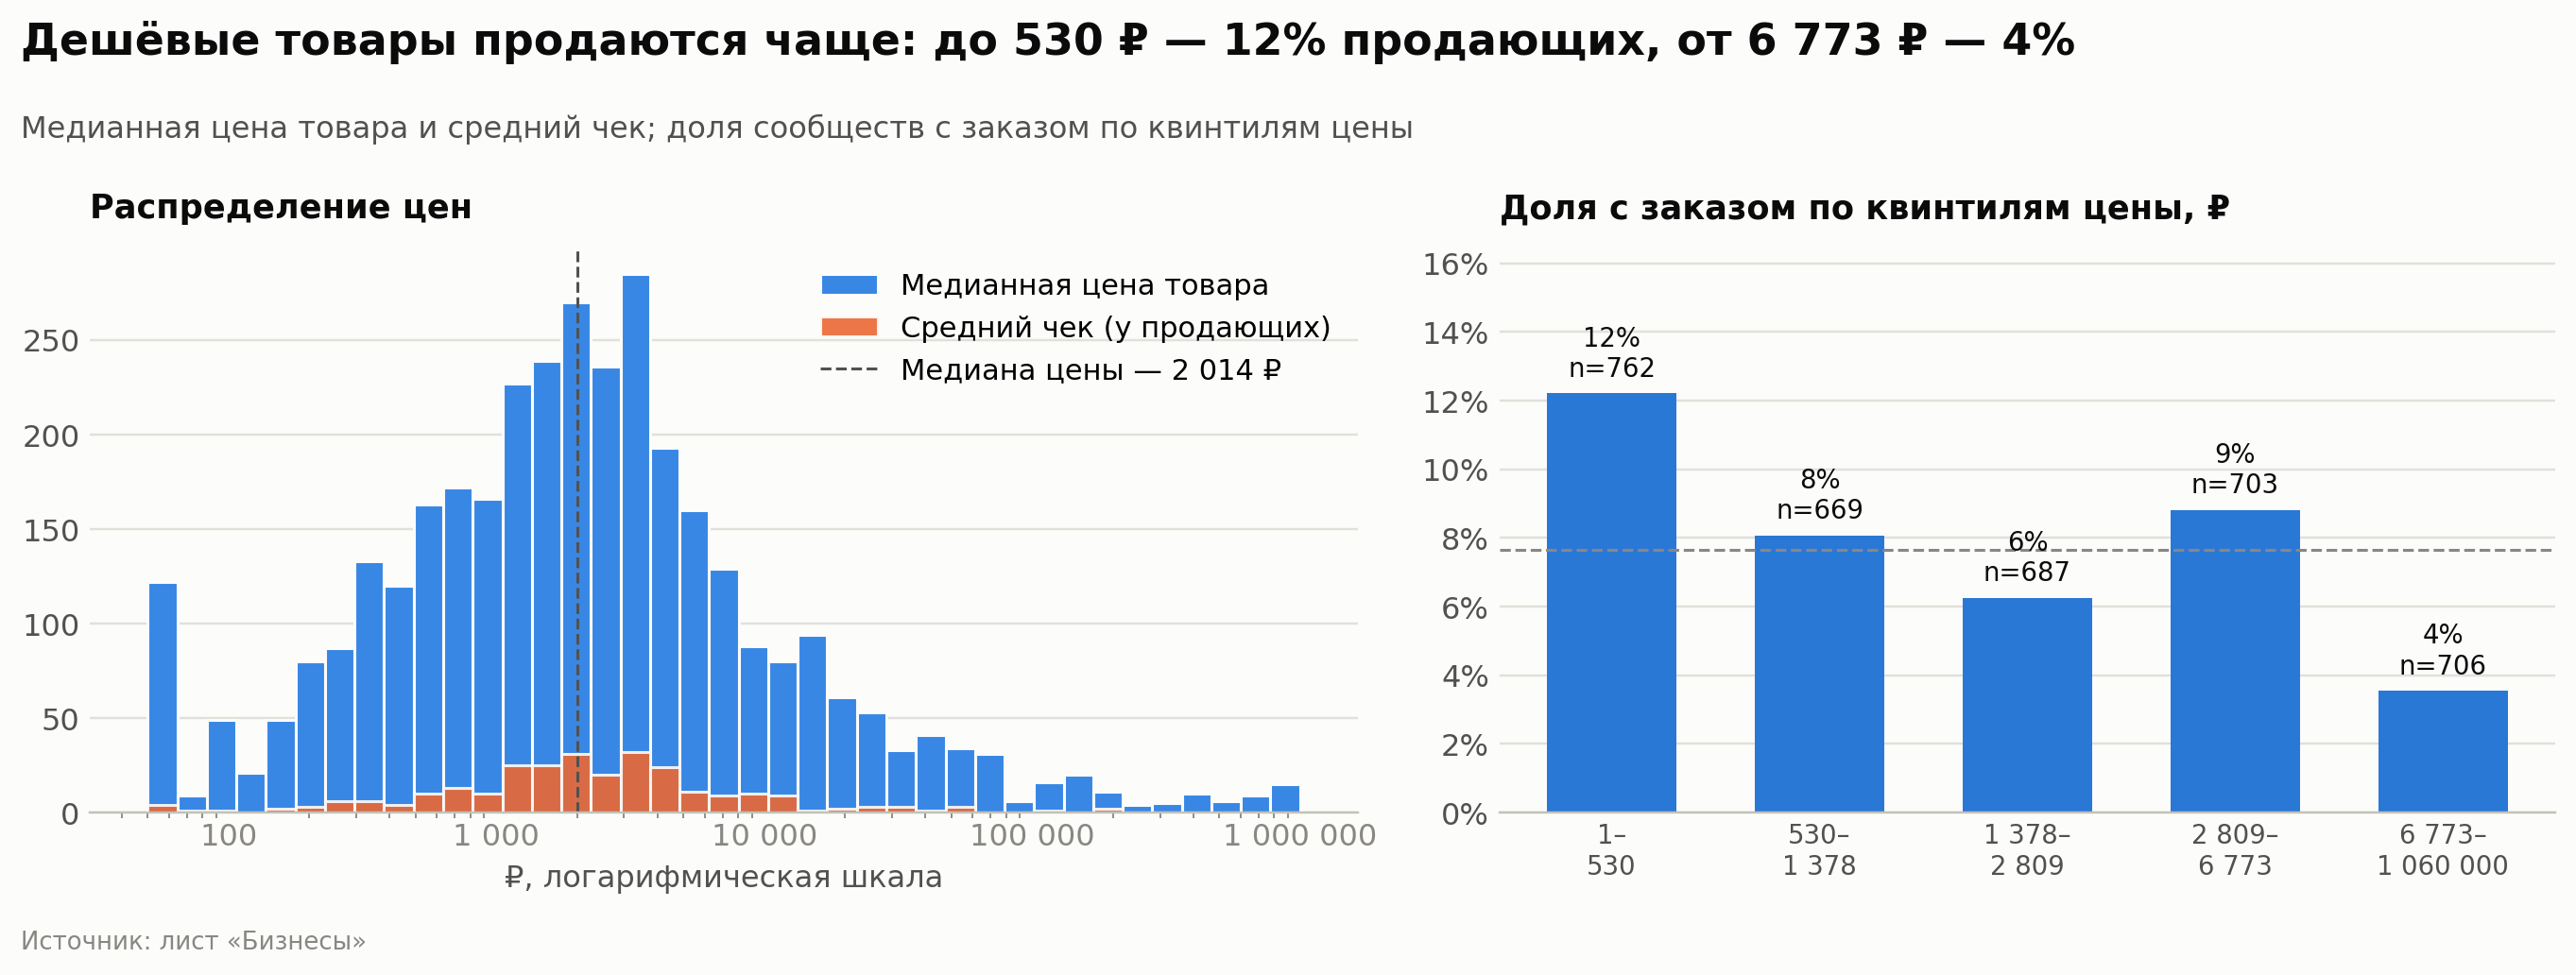

In [16]:
pr = ready[ready.price > 0].copy()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
bins = np.logspace(np.log10(50), np.log10(1e6), 40)
ax.hist(pr.price.clip(50, 1e6), bins=bins, color=SEQ[3], edgecolor=SURF, linewidth=1, label="Медианная цена товара")
ax.hist(ready.aov.dropna().clip(50, 1e6), bins=bins, color=CAT[1], edgecolor=SURF, linewidth=1, alpha=0.9, label="Средний чек (у продающих)")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: ru(v)))
ax.axvline(pr.price.median(), color=INK2, lw=1, ls="--")
ax.lines[-1].set_label(f"Медиана цены — {ru(pr.price.median())} ₽")
ax.set_xlabel("₽, логарифмическая шкала"); ax.legend(loc="upper right"); ax.set_title("Распределение цен")
ax = axes[1]
pr["q"] = pd.qcut(pr.price, 5)
tab = pr.groupby("q", observed=True).agg(n=("id", "size"), rate=("has_order", "mean"))
tab.index = [f"{ru(i.left)}–\n{ru(i.right)}" for i in tab.index]
rate_panel(ax, tab, "Доля с заказом по квинтилям цены, ₽")
finish(fig, f"Дешёвые товары продаются чаще: до {ru(pr.price.quantile(.2))} ₽ — {pct(tab.rate.iloc[0], 0)} продающих, от {ru(pr.price.quantile(.8))} ₽ — {pct(tab.rate.iloc[-1], 0)}",
       "Медианная цена товара и средний чек; доля сообществ с заказом по квинтилям цены",
       "Источник: лист «Бизнесы»")

## 4. Сегментация товарных продавцов

Взаимоисключающие сегменты по **главному барьеру** — что должно случиться, чтобы сообщество получило (больше) заказов. Порядок проверки: каталог → приём заказов → онлайн-оплата/доставка → спрос → продажи.

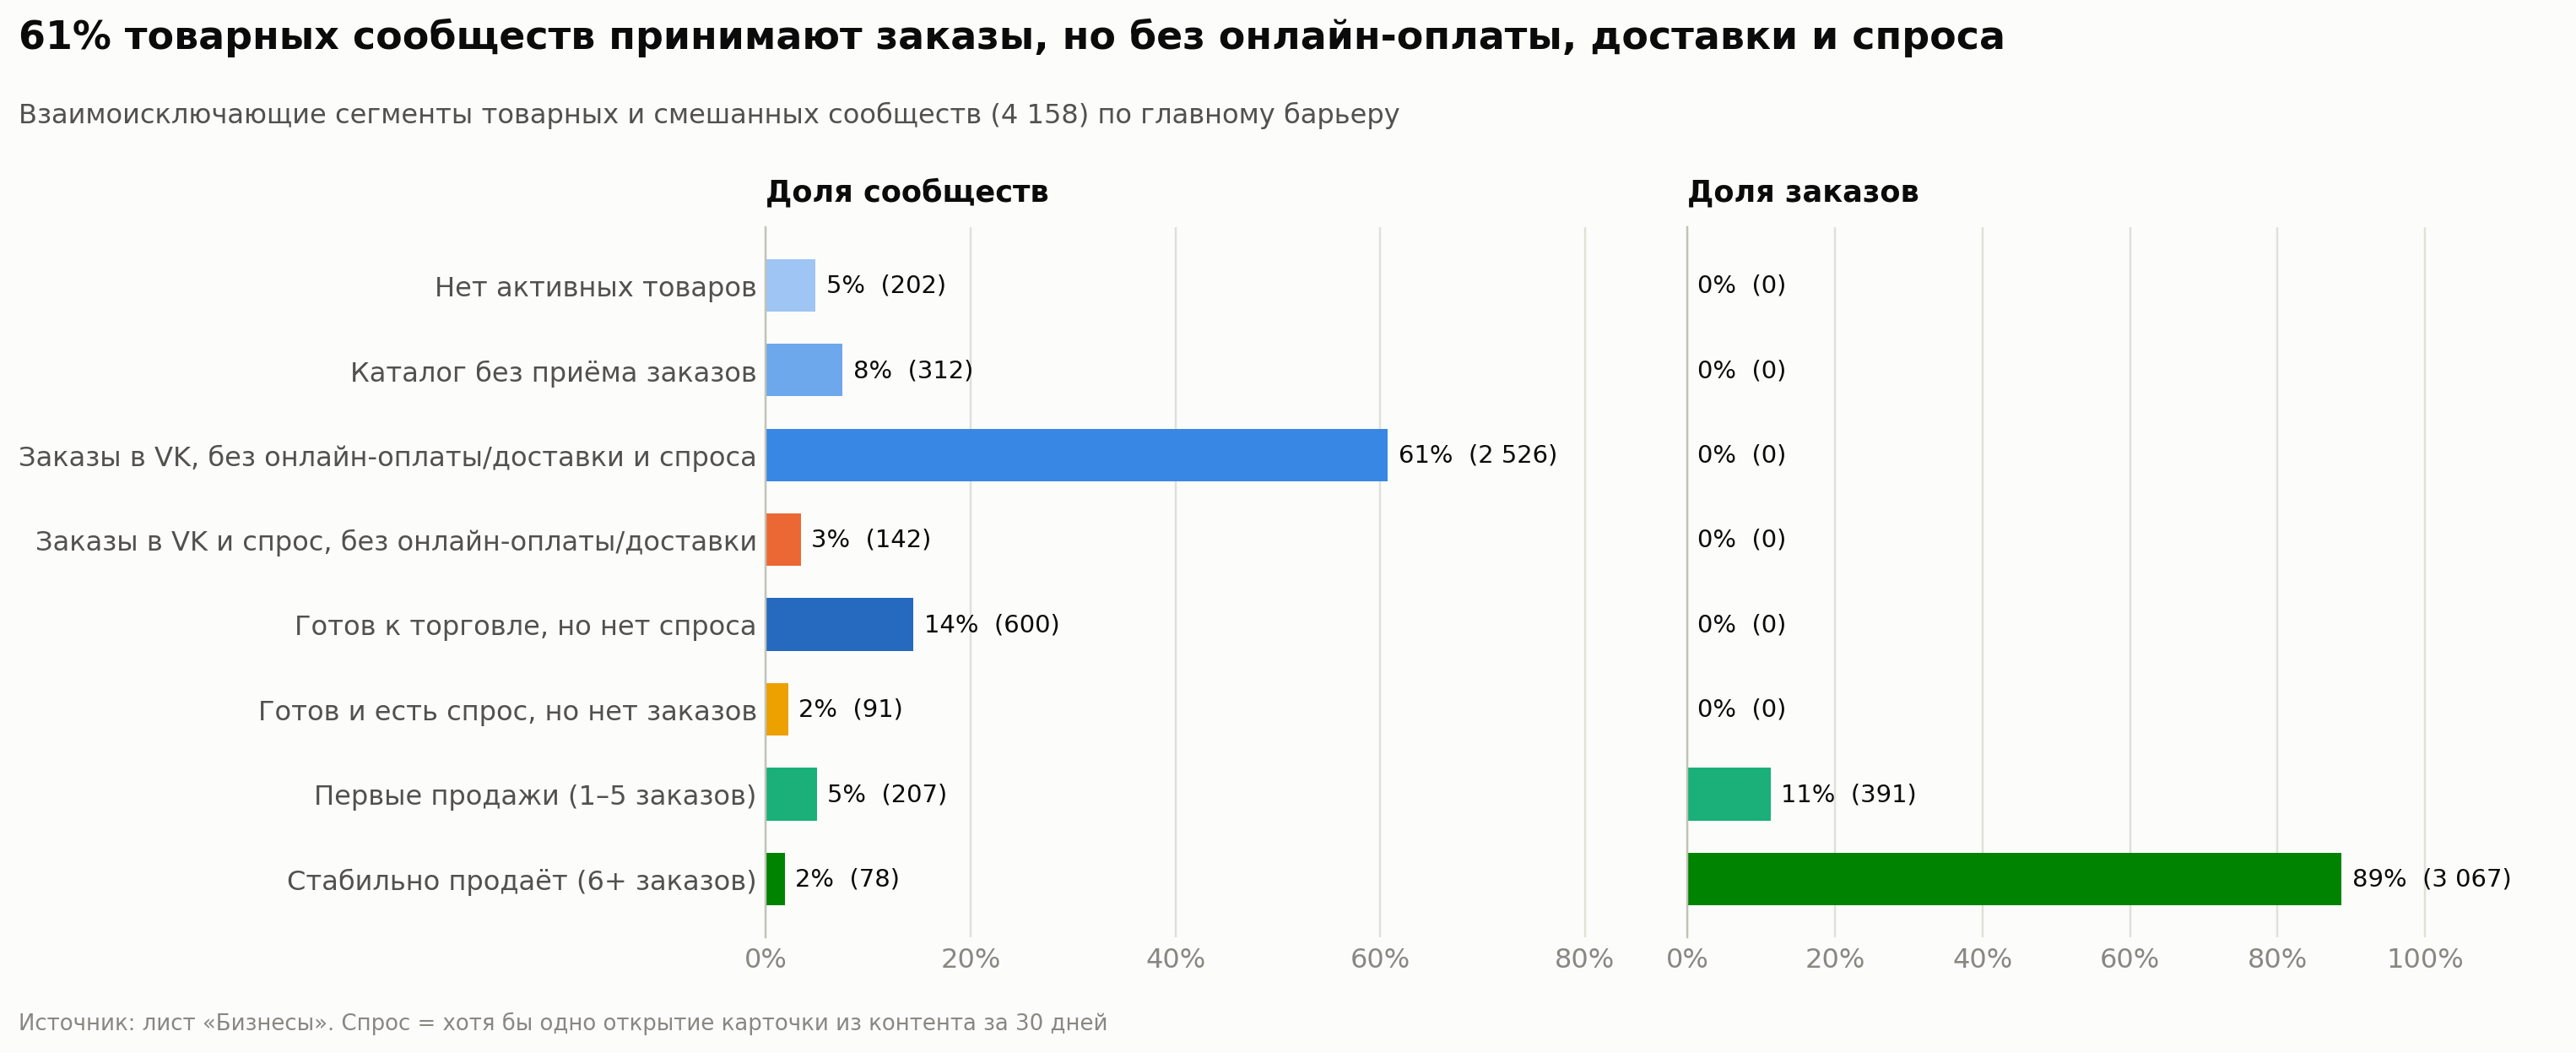

,сообществ,медиана подписчиков,медиана товаров,"медиана цены, ₽",открытий карточки,заказов,"GMV, ₽",доля сообществ,доля заказов
segment,,,,,,,,,
A. Нет активных товаров,202,1200.0,0.0,10176.0,7,0,0,"4,9%","0,0%"
B. Каталог без приёма заказов,312,1300.0,19.0,1616.5,2223,0,0,"7,5%","0,0%"
"C. Заказы в VK, без онлайн-оплаты/доставки и спроса",2526,590.0,8.0,2014.0,0,0,0,"60,8%","0,0%"
"D. Заказы в VK и спрос, без онлайн-оплаты/доставки",142,850.0,11.0,2650.0,2453,0,0,"3,4%","0,0%"
"E. Готов к торговле, но нет спроса",600,960.0,27.0,2067.0,0,0,0,"14,4%","0,0%"
"E2. Готов и есть спрос, но нет заказов",91,770.0,49.0,2538.0,2204,0,0,"2,2%","0,0%"
F. Первые продажи (1–5 заказов),207,2400.0,53.0,1590.0,1346,391,2926987,"5,0%","11,3%"
G. Стабильно продаёт (6+ заказов),78,8950.0,170.0,614.5,13464,3067,6938080,"1,9%","88,7%"


In [17]:
def segment(d):
    has_tools = (d.delivery == 1) | (d.payment == 1)
    has_demand = d.opens > 0
    return np.select([
        d.orders >= 6,
        d.orders >= 1,
        d.active == 0,
        d.checkout == 0,
        ~has_tools & ~has_demand,
        ~has_tools & has_demand,
        has_tools & ~has_demand,
    ], [
        "G. Стабильно продаёт (6+ заказов)",
        "F. Первые продажи (1–5 заказов)",
        "A. Нет активных товаров",
        "B. Каталог без приёма заказов",
        "C. Заказы в VK, без онлайн-оплаты/доставки и спроса",
        "D. Заказы в VK и спрос, без онлайн-оплаты/доставки",
        "E. Готов к торговле, но нет спроса",
    ], default="E2. Готов и есть спрос, но нет заказов")
goods["segment"] = segment(goods)
seg = goods.groupby("segment").agg(n=("id", "size"), subs_med=("subs", "median"), active_med=("active", "median"),
                                   price_med=("price", "median"), opens=("opens", "sum"), orders=("orders", "sum"), gmv=("gmv", "sum")).sort_index()
seg["share_n"] = seg.n / seg.n.sum(); seg["share_orders"] = seg.orders / seg.orders.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), sharey=True, gridspec_kw={"width_ratios": [1, 1]})
names = [s.split(". ", 1)[1] for s in seg.index]
seg_col = [SEQ[1], SEQ[2], SEQ[3], CAT[1], SEQ[4], CAT[3], CAT[2], CAT[5]][: len(seg)]
for ax, col, title in [(axes[0], "share_n", "Доля сообществ"), (axes[1], "share_orders", "Доля заказов")]:
    bars = ax.barh(names, seg[col], color=seg_col, height=0.62)
    vals = seg.n if col == "share_n" else seg.orders
    hbar_labels(ax, bars, [f"{pct(v, 0)}  ({ru(c)})" for v, c in zip(seg[col], vals)])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_xlim(0, min(seg[col].max() * 1.4, 1.18)); hgrid(ax)
    ax.xaxis.set_major_locator(mtick.FixedLocator([0, .2, .4, .6, .8, 1.0]))
    ax.set_title(title)
axes[0].invert_yaxis()
finish(fig, f"{pct(seg.share_n.iloc[2], 0)} товарных сообществ принимают заказы, но без онлайн-оплаты, доставки и спроса",
       "Взаимоисключающие сегменты товарных и смешанных сообществ (4 158) по главному барьеру",
       "Источник: лист «Бизнесы». Спрос = хотя бы одно открытие карточки из контента за 30 дней", top=0.86)
seg.assign(share_n=seg.share_n.map(pct), share_orders=seg.share_orders.map(pct)).rename(columns={
    "n": "сообществ", "subs_med": "медиана подписчиков", "active_med": "медиана товаров", "price_med": "медиана цены, ₽",
    "opens": "открытий карточки", "orders": "заказов", "gmv": "GMV, ₽", "share_n": "доля сообществ", "share_orders": "доля заказов"})

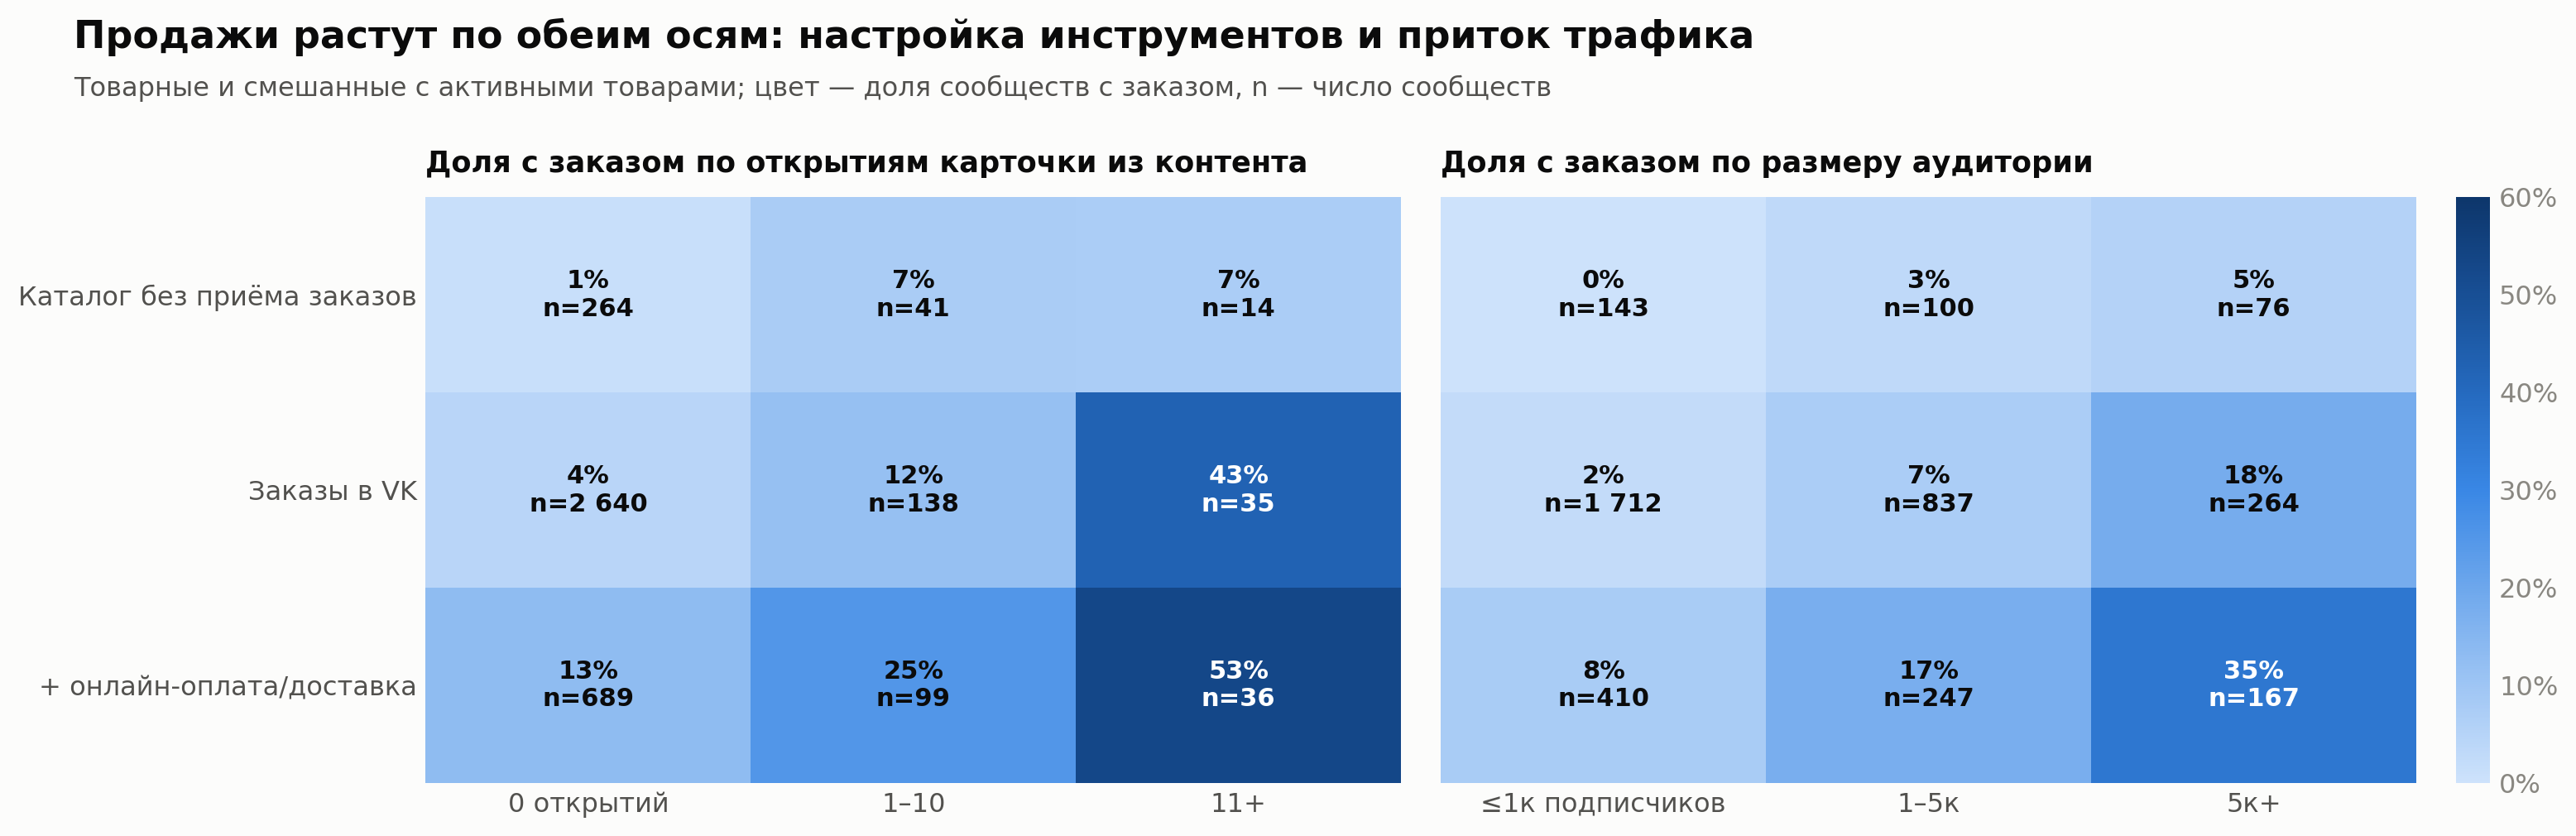

In [18]:
# Карта «готовность × спрос»: где сообществ много, а продаж мало
g2 = goods[goods.active > 0].copy()
g2["ready_lvl"] = np.select([g2.checkout == 0, (g2.delivery == 0) & (g2.payment == 0)],
                            ["Каталог без приёма заказов", "Заказы в VK"], default="+ онлайн-оплата/доставка")
g2["demand"] = pd.cut(g2.opens, [-1, 0, 10, 1e9], labels=["0 открытий", "1–10", "11+"])
g2["aud"] = pd.cut(g2.subs, [-1, 1000, 5000, 1e9], labels=["≤1к подписчиков", "1–5к", "5к+"])
rows_o = ["Каталог без приёма заказов", "Заказы в VK", "+ онлайн-оплата/доставка"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1, 0.035]})
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", SEQ)
for ax, colkey, title in [(axes[0], "demand", "по открытиям карточки из контента"), (axes[1], "aud", "по размеру аудитории")]:
    rate = g2.pivot_table(index="ready_lvl", columns=colkey, values="has_order", aggfunc="mean", observed=True).reindex(rows_o)
    n = g2.pivot_table(index="ready_lvl", columns=colkey, values="id", aggfunc="size", observed=True).reindex(rows_o)
    im = ax.imshow(rate.values, cmap=cmap, vmin=0, vmax=0.6, aspect="auto")
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            v = rate.values[i, j]
            ax.text(j, i, f"{pct(v, 0)}\nn={ru(n.values[i, j])}", ha="center", va="center", fontsize=10,
                    color="white" if v > 0.3 else INK, fontweight="bold")
    ax.set_xticks(range(rate.shape[1]), rate.columns.astype(str)); ax.set_yticks(range(len(rows_o)), rows_o)
    ax.grid(False); ax.spines["bottom"].set_visible(False); ax.set_title("Доля с заказом " + title)
    ax.tick_params(axis="x", colors=INK2)
axes[1].set_yticklabels([])
cb = fig.colorbar(im, cax=axes[2], format=mtick.PercentFormatter(1, decimals=0))
cb.outline.set_visible(False); cb.ax.tick_params(colors=MUTED)
fig.text(0.012, 0.985, "Продажи растут по обеим осям: настройка инструментов и приток трафика", fontsize=15, fontweight="bold", color=INK, va="top")
fig.text(0.012, 0.92, "Товарные и смешанные с активными товарами; цвет — доля сообществ с заказом, n — число сообществ", fontsize=10.5, color=INK2, va="top")
fig.subplots_adjust(top=0.78, left=0.15, right=0.96, wspace=0.06)
plt.show()

## 5. Маркет ВКонтакте vs Партнёр

Партнёр — условный внешний маркетплейс, чьи товары показываются во ВКонтакте (шопсы, реферальные публикации). Заказ Партнёра оформляется на его площадке; заказ Маркета — внутри VK.

In [19]:
tot = pd.read_excel(xls, "Маркет Вконтакте — итоги")
tot.columns = ["metric", "vk", "partner", "all"]
tot = tot.set_index("metric")
num = lambda v: pd.to_numeric(v, errors="coerce")
T = {k: (num(tot.loc[k, "vk"]), num(tot.loc[k, "partner"])) for k in tot.index}
general = tot["all"].dropna()
print("Общие метрики Маркета ВКонтакте:")
for k, v in general.items():
    print(f"  {k}: {ru(v, 0 if float(v).is_integer() else 1) if isinstance(v, (int, float, np.integer, np.floating)) else v}")

Общие метрики Маркета ВКонтакте:
  Период: 2026-09-01 — 2026-09-30
  DAU Маркета Вконтакте (среднее за день): 127 406
  MAU Маркета Вконтакте (уникальные за 30 дней): 2 997 341
  Пользователи, видевшие товары за 30 дней: 66 617 967
  Пользователи, открывавшие карточку товара за 30 дней: 27 333 960
  Открытия карточки товара из постов и клипов: 86 321 893
  в т.ч. из реферальных постов и клипов: 82 324 081
  Запросы в товарном поиске: 28 585 243
  Доля поисковых запросов с открытием карточки, %: 18,4


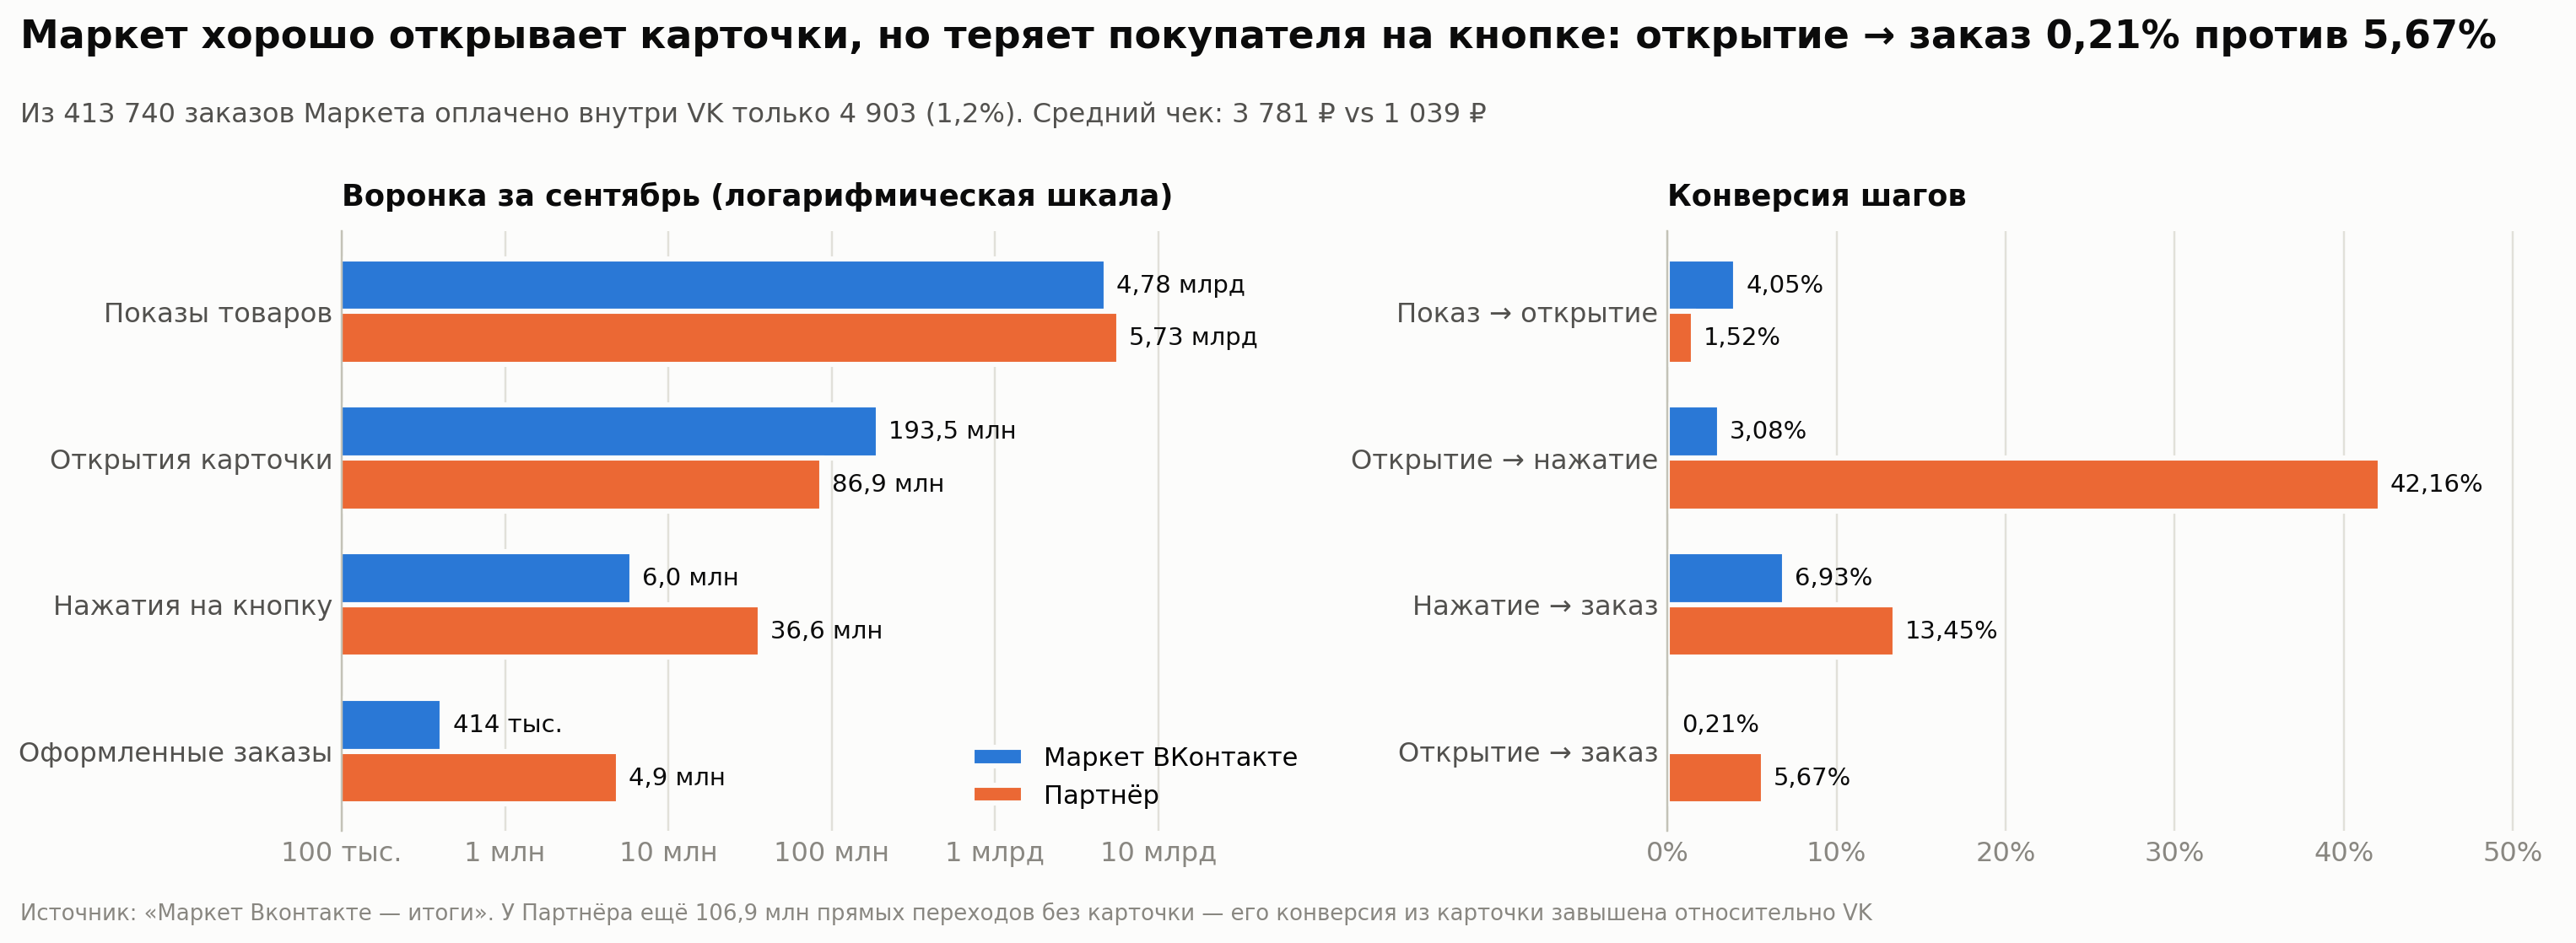

In [20]:
funnel = pd.DataFrame({
    "Показы товаров": T["Показы товаров"], "Открытия карточки": T["Открытия карточки товара"],
    "Нажатия на кнопку": T["Нажатия на кнопку в карточке"], "Оформленные заказы": T["Оформленные заказы"],
}, index=["vk", "partner"]).T
conv = pd.DataFrame({
    "Показ → открытие": funnel.iloc[1] / funnel.iloc[0],
    "Открытие → нажатие": funnel.iloc[2] / funnel.iloc[1],
    "Нажатие → заказ": funnel.iloc[3] / funnel.iloc[2],
    "Открытие → заказ": funnel.iloc[3] / funnel.iloc[1],
}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
y = np.arange(len(funnel)); h = 0.36
b1 = ax.barh(y - h / 2, funnel.vk, h, color=VK, label="Маркет ВКонтакте", edgecolor=SURF, linewidth=2)
b2 = ax.barh(y + h / 2, funnel.partner, h, color=PARTNER, label="Партнёр", edgecolor=SURF, linewidth=2)
fmt_big = lambda v: ru(v / 1e9, 2) + " млрд" if v >= 1e9 else (ru(v / 1e6, 1) + " млн" if v >= 1e6 else ru(v / 1e3, 0) + " тыс.")
hbar_labels(ax, b1, [fmt_big(v) for v in funnel.vk]); hbar_labels(ax, b2, [fmt_big(v) for v in funnel.partner])
ax.set_xscale("log"); ax.set_yticks(y, funnel.index); ax.invert_yaxis(); ax.set_xlim(1e5, 1e11); hgrid(ax)
ax.xaxis.set_major_locator(mtick.FixedLocator([1e5, 1e6, 1e7, 1e8, 1e9, 1e10])); ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.set_xticklabels(["100 тыс.", "1 млн", "10 млн", "100 млн", "1 млрд", "10 млрд"]); ax.legend(loc="lower right")
ax.set_title("Воронка за сентябрь (логарифмическая шкала)")

ax = axes[1]
y = np.arange(len(conv))
b1 = ax.barh(y - h / 2, conv.vk, h, color=VK, edgecolor=SURF, linewidth=2)
b2 = ax.barh(y + h / 2, conv.partner, h, color=PARTNER, edgecolor=SURF, linewidth=2)
hbar_labels(ax, b1, [pct(v, 2) for v in conv.vk]); hbar_labels(ax, b2, [pct(v, 2) for v in conv.partner])
ax.set_yticks(y, conv.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, conv.values.max() * 1.25); hgrid(ax); ax.set_title("Конверсия шагов")
paid = T["Оплаченные заказы"][0] / T["Оформленные заказы"][0]
finish(fig, f"Маркет хорошо открывает карточки, но теряет покупателя на кнопке: открытие → заказ {pct(conv.loc['Открытие → заказ','vk'], 2)} против {pct(conv.loc['Открытие → заказ','partner'], 2)}",
       f"Из {ru(T['Оформленные заказы'][0])} заказов Маркета оплачено внутри VK только {ru(T['Оплаченные заказы'][0])} ({pct(paid, 1)}). Средний чек: {ru(T['Средний чек, ₽'][0])} ₽ vs {ru(T['Средний чек, ₽'][1])} ₽",
       "Источник: «Маркет Вконтакте — итоги». У Партнёра ещё 106,9 млн прямых переходов без карточки — его конверсия из карточки завышена относительно VK")

In [21]:
kpi = pd.DataFrame({
    "Маркет ВКонтакте": [T[k][0] for k in ["Оформленные заказы", "GMV, ₽", "Средний чек, ₽", "Уникальные покупатели за 30 дней", "Заказов на покупателя", "Доля повторных покупателей (2+ заказа), %"]],
    "Партнёр": [T[k][1] for k in ["Оформленные заказы", "GMV, ₽", "Средний чек, ₽", "Уникальные покупатели за 30 дней", "Заказов на покупателя", "Доля повторных покупателей (2+ заказа), %"]],
}, index=["Заказы", "GMV, ₽", "Средний чек, ₽", "Покупатели", "Заказов на покупателя", "Повторные покупатели, %"])
kpi["Партнёр / Маркет"] = (kpi["Партнёр"] / kpi["Маркет ВКонтакте"]).round(1)
kpi.style.format({"Маркет ВКонтакте": lambda v: ru(v, 1 if v < 100 else 0), "Партнёр": lambda v: ru(v, 1 if v < 100 else 0), "Партнёр / Маркет": lambda v: ru(v, 1) + "×"})

,Маркет ВКонтакте,Партнёр,Партнёр / Маркет
Заказы,413 740,4 927 525,"11,9×"
"GMV, ₽",1 564 546 740,5 119 514 685,"3,3×"
"Средний чек, ₽",3 781,1 039,"0,3×"
Покупатели,296 148,2 901 334,"9,8×"
Заказов на покупателя,"1,4","1,7","1,2×"
"Повторные покупатели, %","19,0","26,6","1,4×"


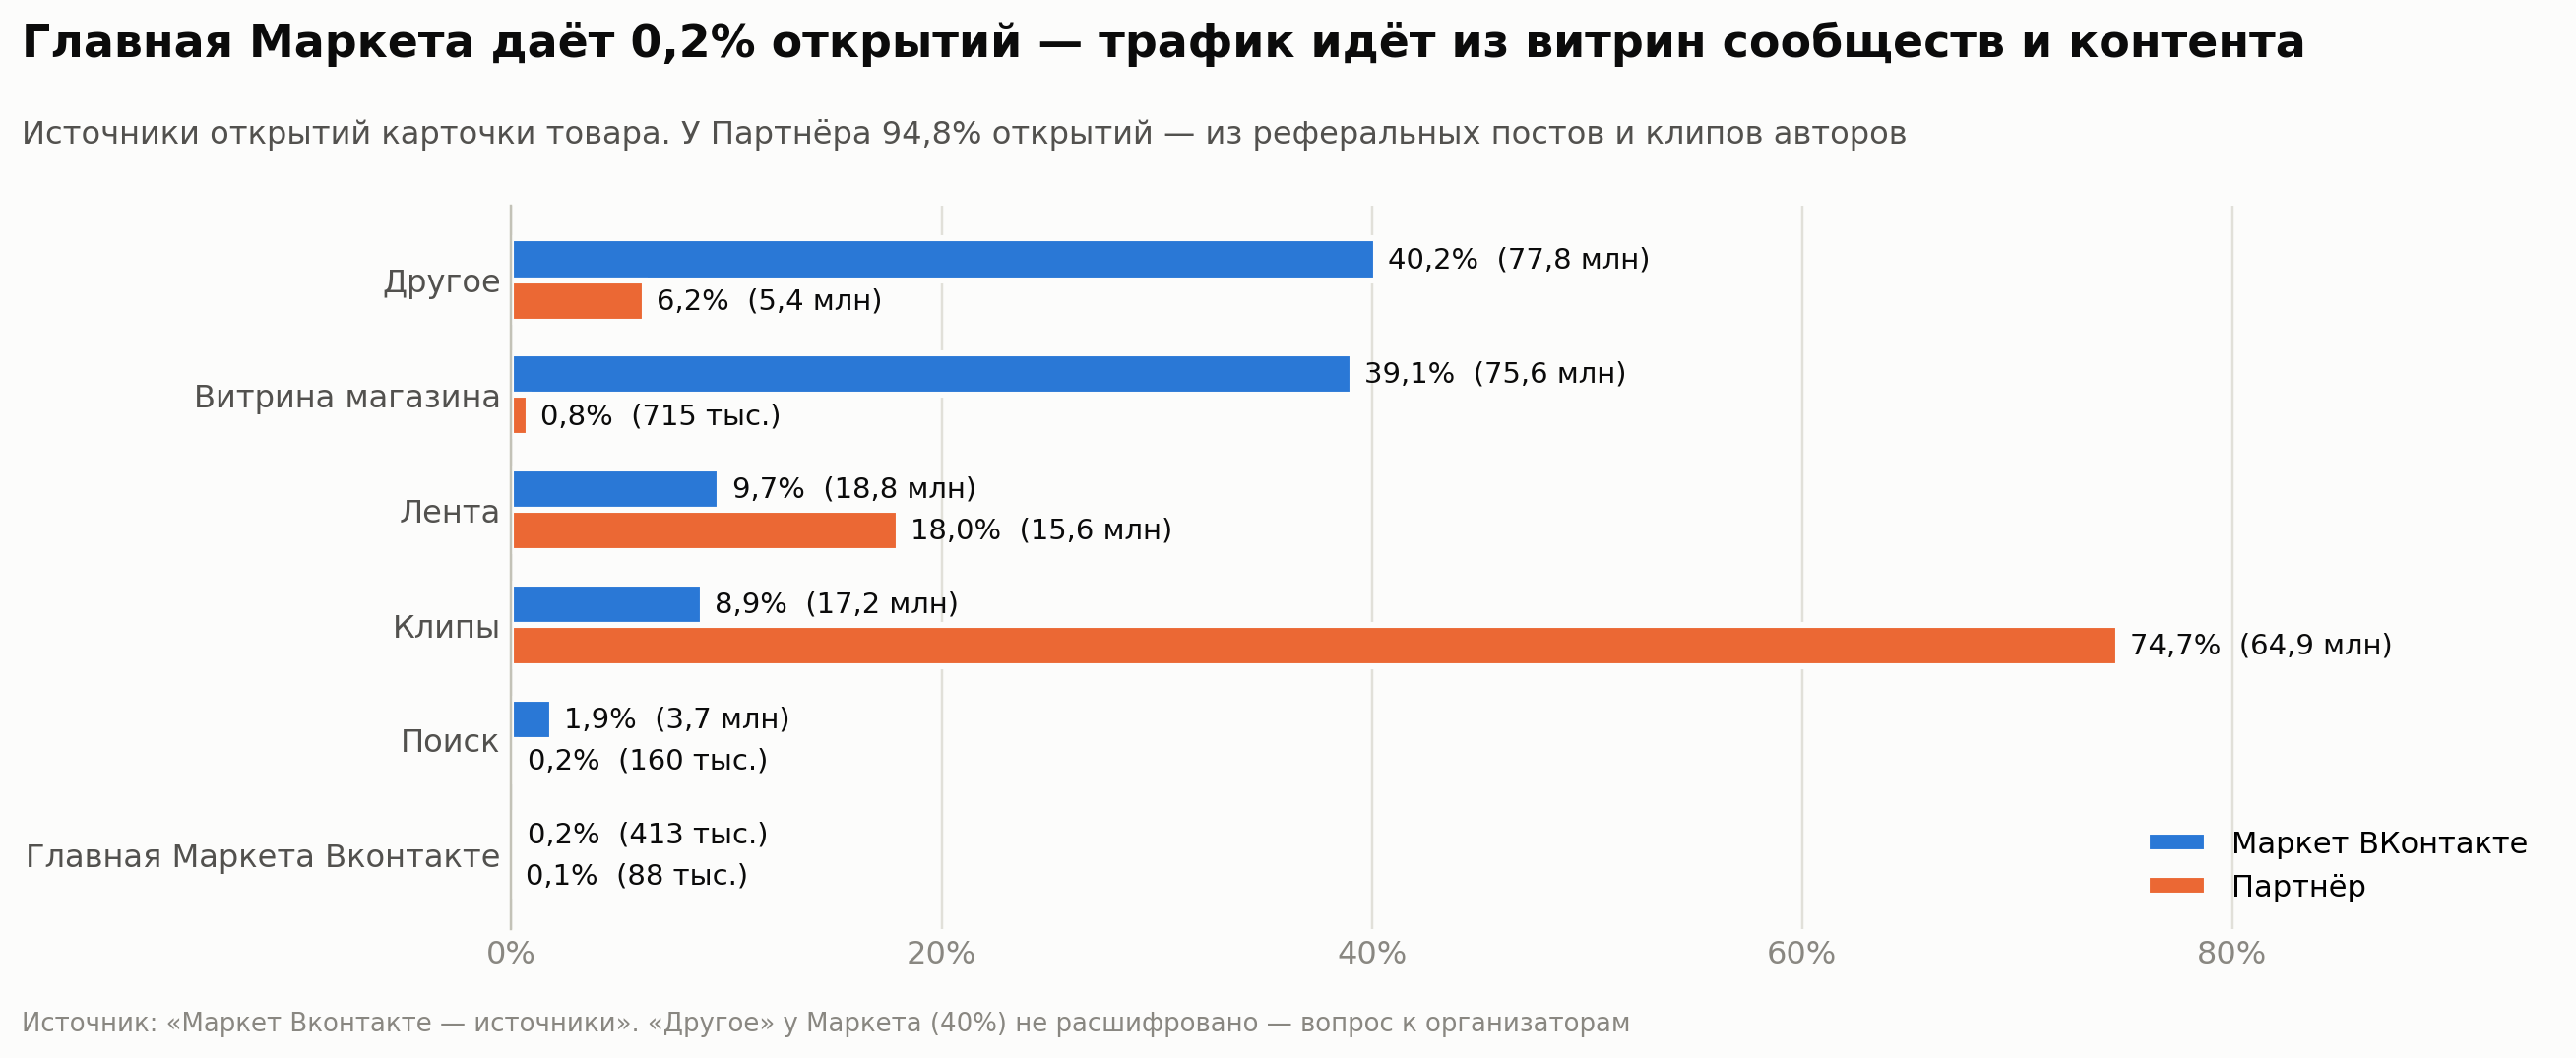

In [22]:
srcs = pd.read_excel(xls, "Маркет Вконтакте — источники")
srcs.columns = ["source", "vk", "vk_share", "partner", "partner_share"]
main = srcs[~srcs.source.str.startswith("в т.ч.")].set_index("source")
main = main.sort_values("vk_share")
fig, ax = plt.subplots(figsize=(12, 4.8))
y = np.arange(len(main)); h = 0.36
b1 = ax.barh(y + h / 2, main.vk_share / 100, h, color=VK, label="Маркет ВКонтакте", edgecolor=SURF, linewidth=2)
b2 = ax.barh(y - h / 2, main.partner_share / 100, h, color=PARTNER, label="Партнёр", edgecolor=SURF, linewidth=2)
hbar_labels(ax, b1, [f"{ru(v, 1)}%  ({fmt_big(a)})" for v, a in zip(main.vk_share, main.vk)])
hbar_labels(ax, b2, [f"{ru(v, 1)}%  ({fmt_big(a)})" for v, a in zip(main.partner_share, main.partner)])
ax.set_yticks(y, main.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_xlim(0, 0.95); hgrid(ax)
ax.legend(loc="lower right")
ref_share = srcs.loc[srcs.source.str.startswith("в т.ч."), "partner_share"].iloc[0]
finish(fig, "Главная Маркета даёт 0,2% открытий — трафик идёт из витрин сообществ и контента",
       f"Источники открытий карточки товара. У Партнёра {ru(ref_share, 1)}% открытий — из реферальных постов и клипов авторов",
       "Источник: «Маркет Вконтакте — источники». «Другое» у Маркета (40%) не расшифровано — вопрос к организаторам")

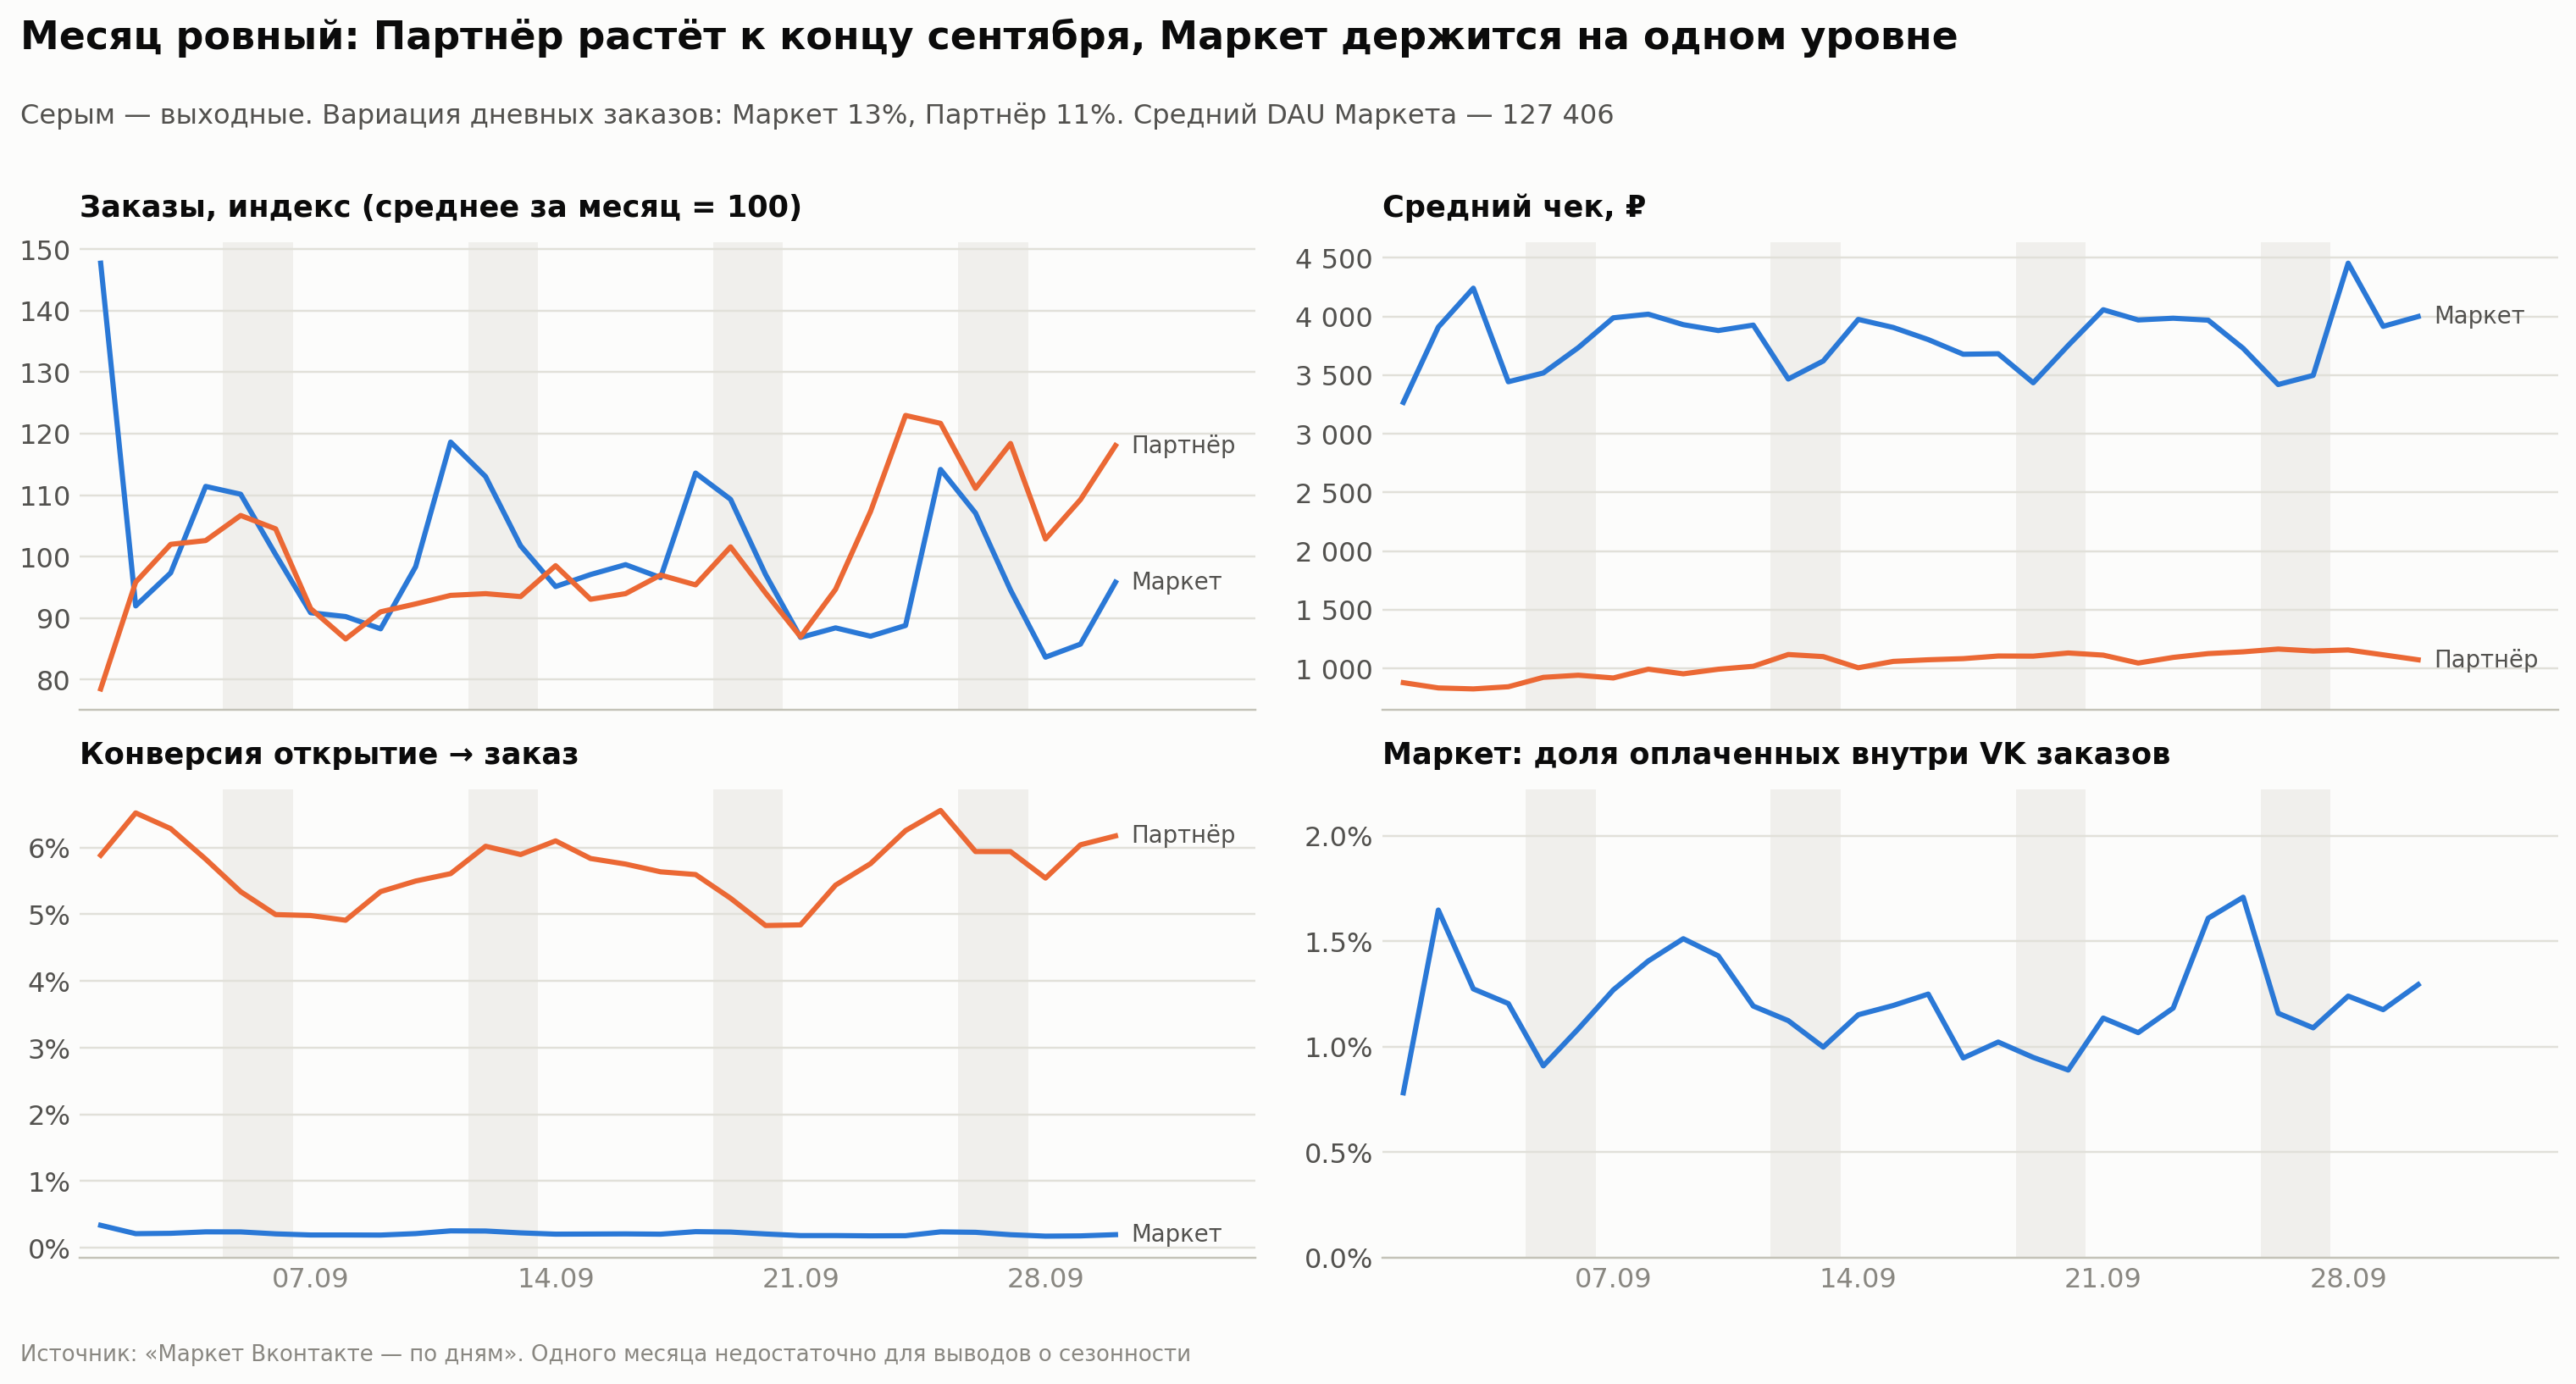

In [23]:
daily = pd.read_excel(xls, "Маркет Вконтакте — по дням")
daily.columns = ["date", "dau", "saw", "opened", "search", "search_open", "imp_vk", "imp_p", "open_vk", "open_p",
                 "click_vk", "click_p", "ord_vk", "ord_p", "paid_vk", "gmv_vk", "gmv_p", "buy_vk", "buy_p"]
daily["date"] = pd.to_datetime(daily.date)
weekend = daily.date.dt.dayofweek >= 5

fig, axes = plt.subplots(2, 2, figsize=(14, 7.4), sharex=True)
def shade(ax):
    for d in daily.date[weekend]:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="#f0efec", lw=0, zorder=0)
def line2(ax, a, b, title, fmt, la="Маркет ВКонтакте", lb="Партнёр"):
    shade(ax)
    ax.plot(daily.date, a, color=VK, label=la); ax.plot(daily.date, b, color=PARTNER, label=lb)
    ax.set_title(title); ax.yaxis.set_major_formatter(fmt)
    ax.annotate(la if la else "", (daily.date.iloc[-1], a.iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK2, fontsize=9, va="center")
    ax.annotate(lb if lb else "", (daily.date.iloc[-1], b.iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK2, fontsize=9, va="center")
idx = mtick.FuncFormatter(lambda v, _: ru(v))
line2(axes[0, 0], 100 * daily.ord_vk / daily.ord_vk.mean(), 100 * daily.ord_p / daily.ord_p.mean(), "Заказы, индекс (среднее за месяц = 100)", idx, "Маркет", "Партнёр")
line2(axes[0, 1], daily.gmv_vk / daily.ord_vk, daily.gmv_p / daily.ord_p, "Средний чек, ₽", idx, "Маркет", "Партнёр")
line2(axes[1, 0], daily.ord_vk / daily.open_vk, daily.ord_p / daily.open_p, "Конверсия открытие → заказ", mtick.PercentFormatter(1, decimals=0), "Маркет", "Партнёр")
ax = axes[1, 1]; shade(ax)
ax.plot(daily.date, daily.paid_vk / daily.ord_vk, color=VK)
ax.set_title("Маркет: доля оплаченных внутри VK заказов"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_ylim(0, (daily.paid_vk / daily.ord_vk).max() * 1.3)
import matplotlib.dates as mdates
for a in axes.flat:
    a.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0)); a.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    a.set_xlim(daily.date.min() - pd.Timedelta(days=0.6), daily.date.max() + pd.Timedelta(days=4))
cv = (daily.ord_vk.std() / daily.ord_vk.mean(), daily.ord_p.std() / daily.ord_p.mean())
finish(fig, "Месяц ровный: Партнёр растёт к концу сентября, Маркет держится на одном уровне",
       f"Серым — выходные. Вариация дневных заказов: Маркет {pct(cv[0], 0)}, Партнёр {pct(cv[1], 0)}. Средний DAU Маркета — {ru(daily.dau.mean())}",
       "Источник: «Маркет Вконтакте — по дням». Одного месяца недостаточно для выводов о сезонности", top=0.88)

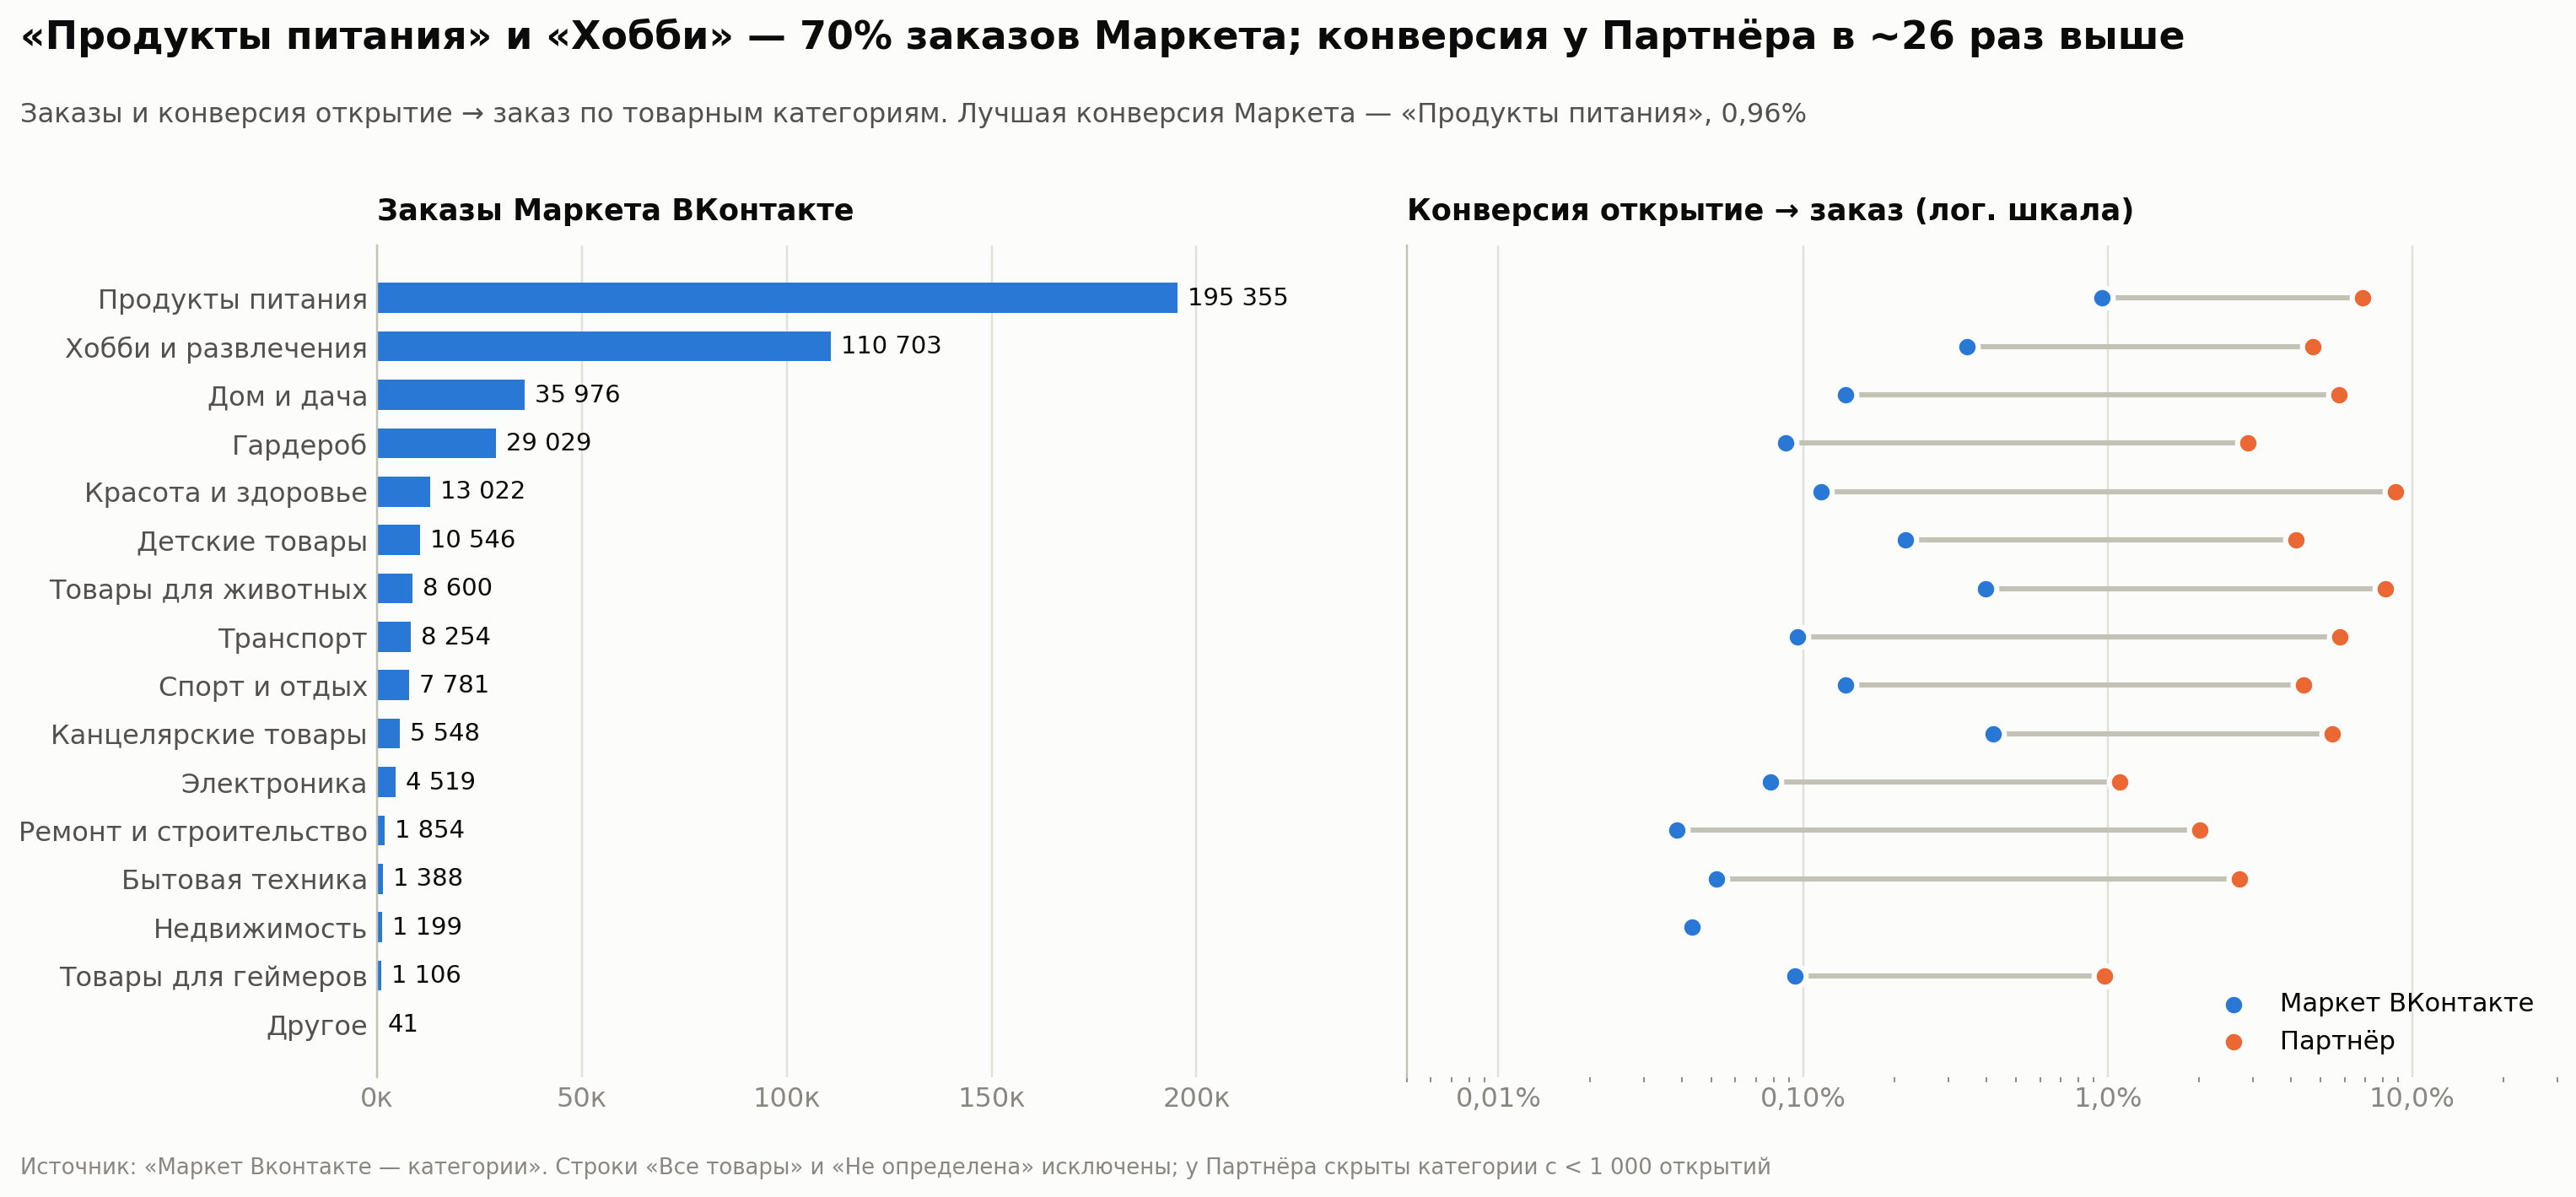

In [24]:
cats = pd.read_excel(xls, "Маркет Вконтакте — категории")
cats.columns = ["cat", "open_vk", "ord_vk", "open_p", "ord_p"]
cats = cats.set_index("cat")
cats["cr_vk"] = cats.ord_vk / cats.open_vk
cats["cr_p"] = cats.ord_p / cats.open_p.replace(0, np.nan)
cc = cats.drop(index=["Не определена", "Все товары"]).sort_values("ord_vk")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), sharey=True, gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
bars = ax.barh(cc.index, cc.ord_vk, color=VK, height=0.62)
hbar_labels(ax, bars, [ru(v) for v in cc.ord_vk]); hgrid(ax); ax.set_xlim(0, cc.ord_vk.max() * 1.25)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: ru(v / 1000) + "к")); ax.set_title("Заказы Маркета ВКонтакте")
ax = axes[1]
yy = np.arange(len(cc))
valid = cc.cr_p.notna() & (cc.open_p > 1000)
for i, (a, b, ok) in enumerate(zip(cc.cr_vk, cc.cr_p, valid)):
    if ok: ax.plot([a, b], [i, i], color=BASE, lw=2, zorder=1)
ax.scatter(cc.cr_vk, yy, s=70, color=VK, edgecolor=SURF, linewidth=2, zorder=3, label="Маркет ВКонтакте")
ax.scatter(cc.cr_p[valid], yy[valid.values], s=70, color=PARTNER, edgecolor=SURF, linewidth=2, zorder=3, label="Партнёр")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: (ru(100 * v, 2 if v < 0.01 else 1) + "%")))
ax.set_xlim(5e-5, 0.3); hgrid(ax); ax.legend(loc="lower right"); ax.set_title("Конверсия открытие → заказ (лог. шкала)")
two = cc.ord_vk.nlargest(2).sum() / cats.ord_vk.sum()
gap = (cc.cr_p[valid] / cc.cr_vk[valid]).median()
finish(fig, f"«Продукты питания» и «Хобби» — {pct(two, 0)} заказов Маркета; конверсия у Партнёра в ~{ru(gap)} раз выше",
       f"Заказы и конверсия открытие → заказ по товарным категориям. Лучшая конверсия Маркета — «Продукты питания», {pct(cc.cr_vk.max(), 2)}",
       "Источник: «Маркет Вконтакте — категории». Строки «Все товары» и «Не определена» исключены; у Партнёра скрыты категории с < 1 000 открытий",
       top=0.86)

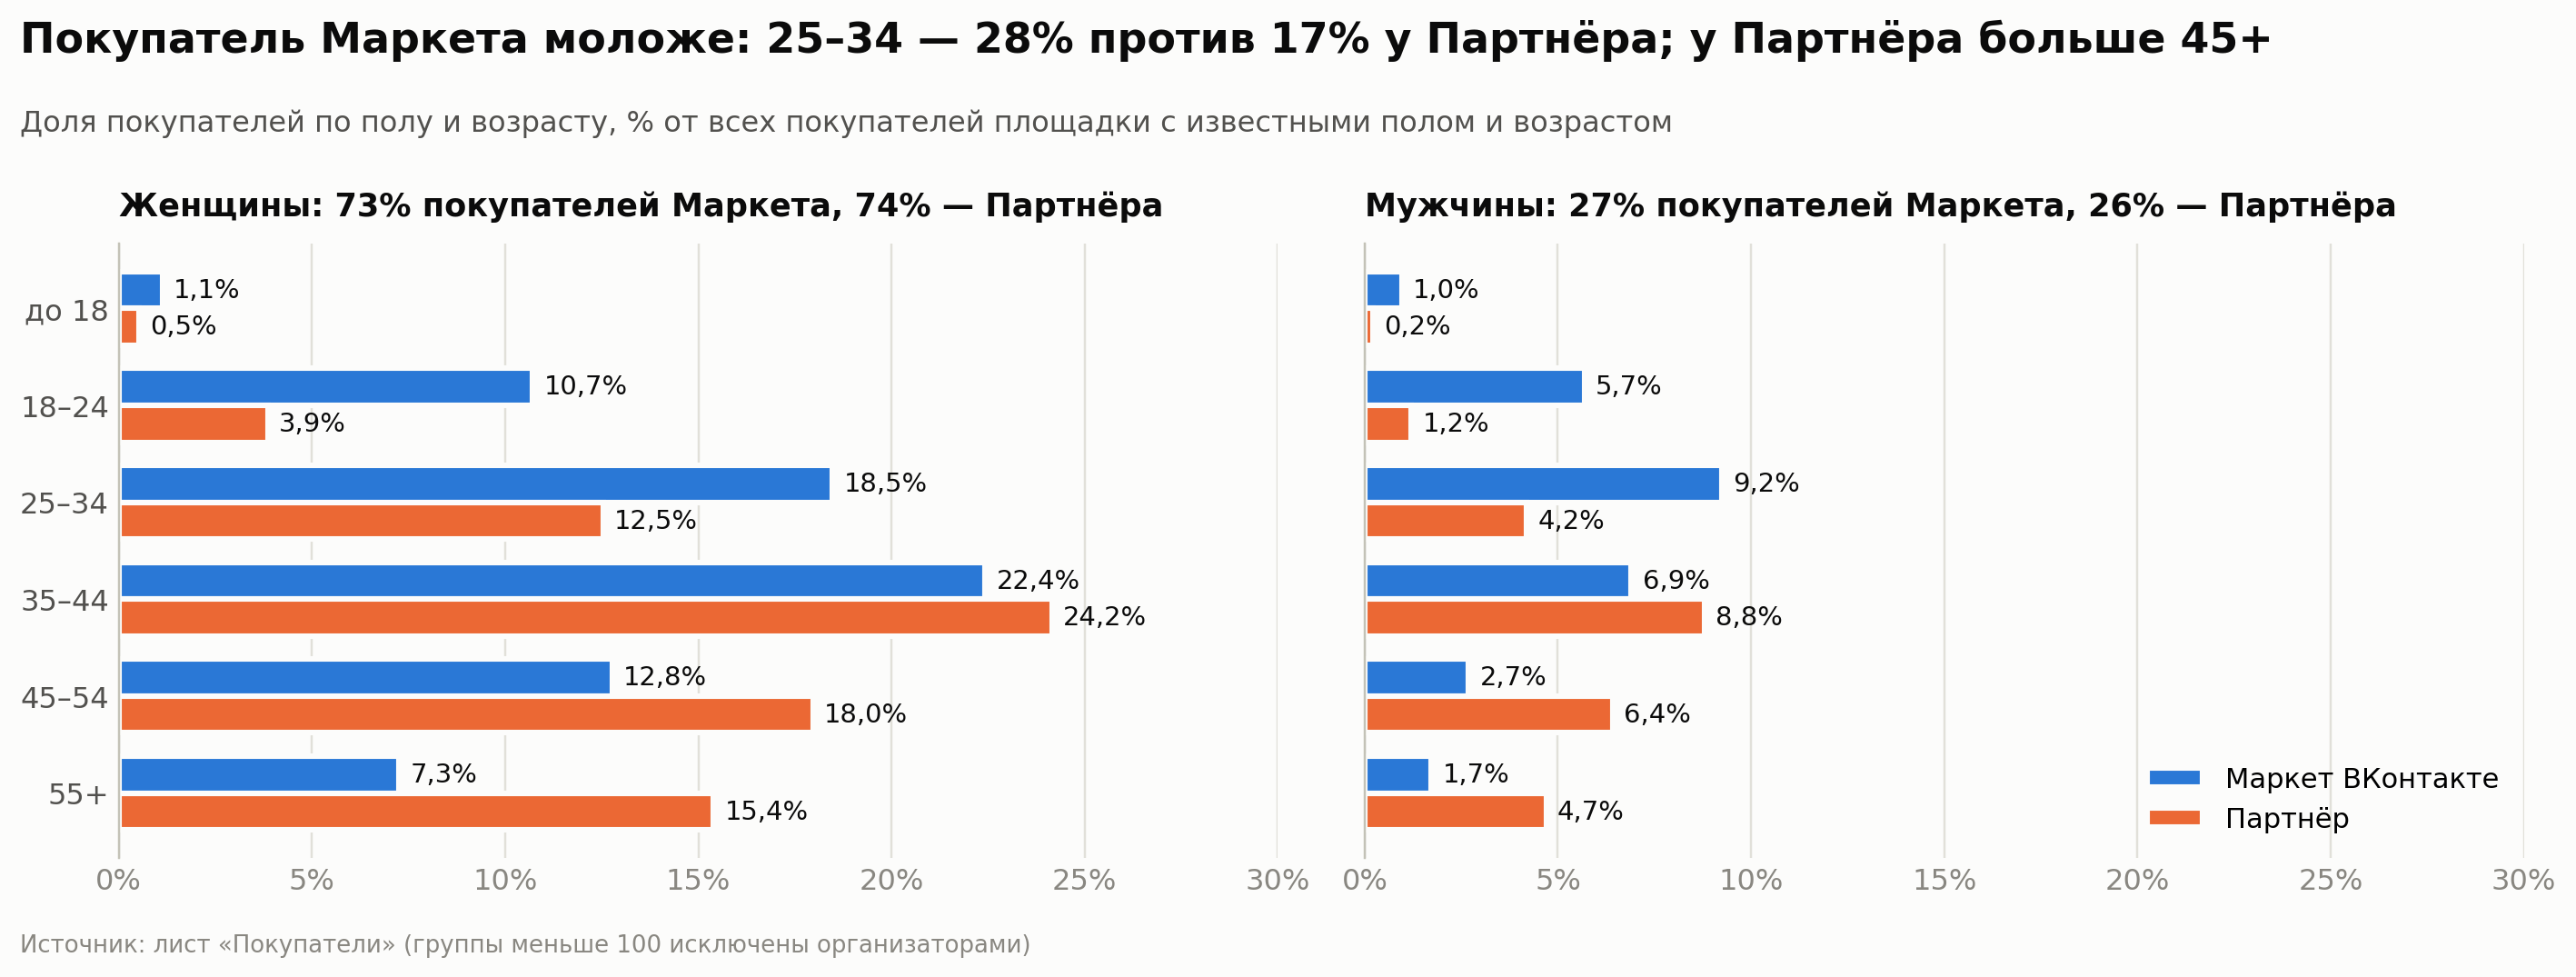

In [25]:
dem = pd.read_excel(xls, "Покупатели")
dem.columns = ["sex", "age", "buy_vk", "ord_vk", "buy_p", "ord_p"]
dem = dem[(dem.sex != "н/д") & (dem.age != "н/д")]
AGES = ["до 18", "18–24", "25–34", "35–44", "45–54", "55+"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, sex, title in [(axes[0], "Ж", "Женщины"), (axes[1], "М", "Мужчины")]:
    d = dem[dem.sex == sex].set_index("age").reindex(AGES)
    sv = d.buy_vk / dem.buy_vk.sum(); sp = d.buy_p / dem.buy_p.sum()
    y = np.arange(len(AGES)); h = 0.38
    b1 = ax.barh(y - h / 2, sv, h, color=VK, label="Маркет ВКонтакте", edgecolor=SURF, linewidth=2)
    b2 = ax.barh(y + h / 2, sp, h, color=PARTNER, label="Партнёр", edgecolor=SURF, linewidth=2)
    hbar_labels(ax, b1, [pct(v, 1) for v in sv]); hbar_labels(ax, b2, [pct(v, 1) for v in sp])
    ax.set_yticks(y, AGES); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); hgrid(ax)
    ax.set_xlim(0, 0.3); ax.set_title(f"{title}: {pct(d.buy_vk.sum() / dem.buy_vk.sum(), 0)} покупателей Маркета, {pct(d.buy_p.sum() / dem.buy_p.sum(), 0)} — Партнёра")
axes[0].invert_yaxis(); axes[1].legend(loc="lower right")
finish(fig, "Покупатель Маркета моложе: 25–34 — 28% против 17% у Партнёра; у Партнёра больше 45+",
       "Доля покупателей по полу и возрасту, % от всех покупателей площадки с известными полом и возрастом",
       "Источник: лист «Покупатели» (группы меньше 100 исключены организаторами)")

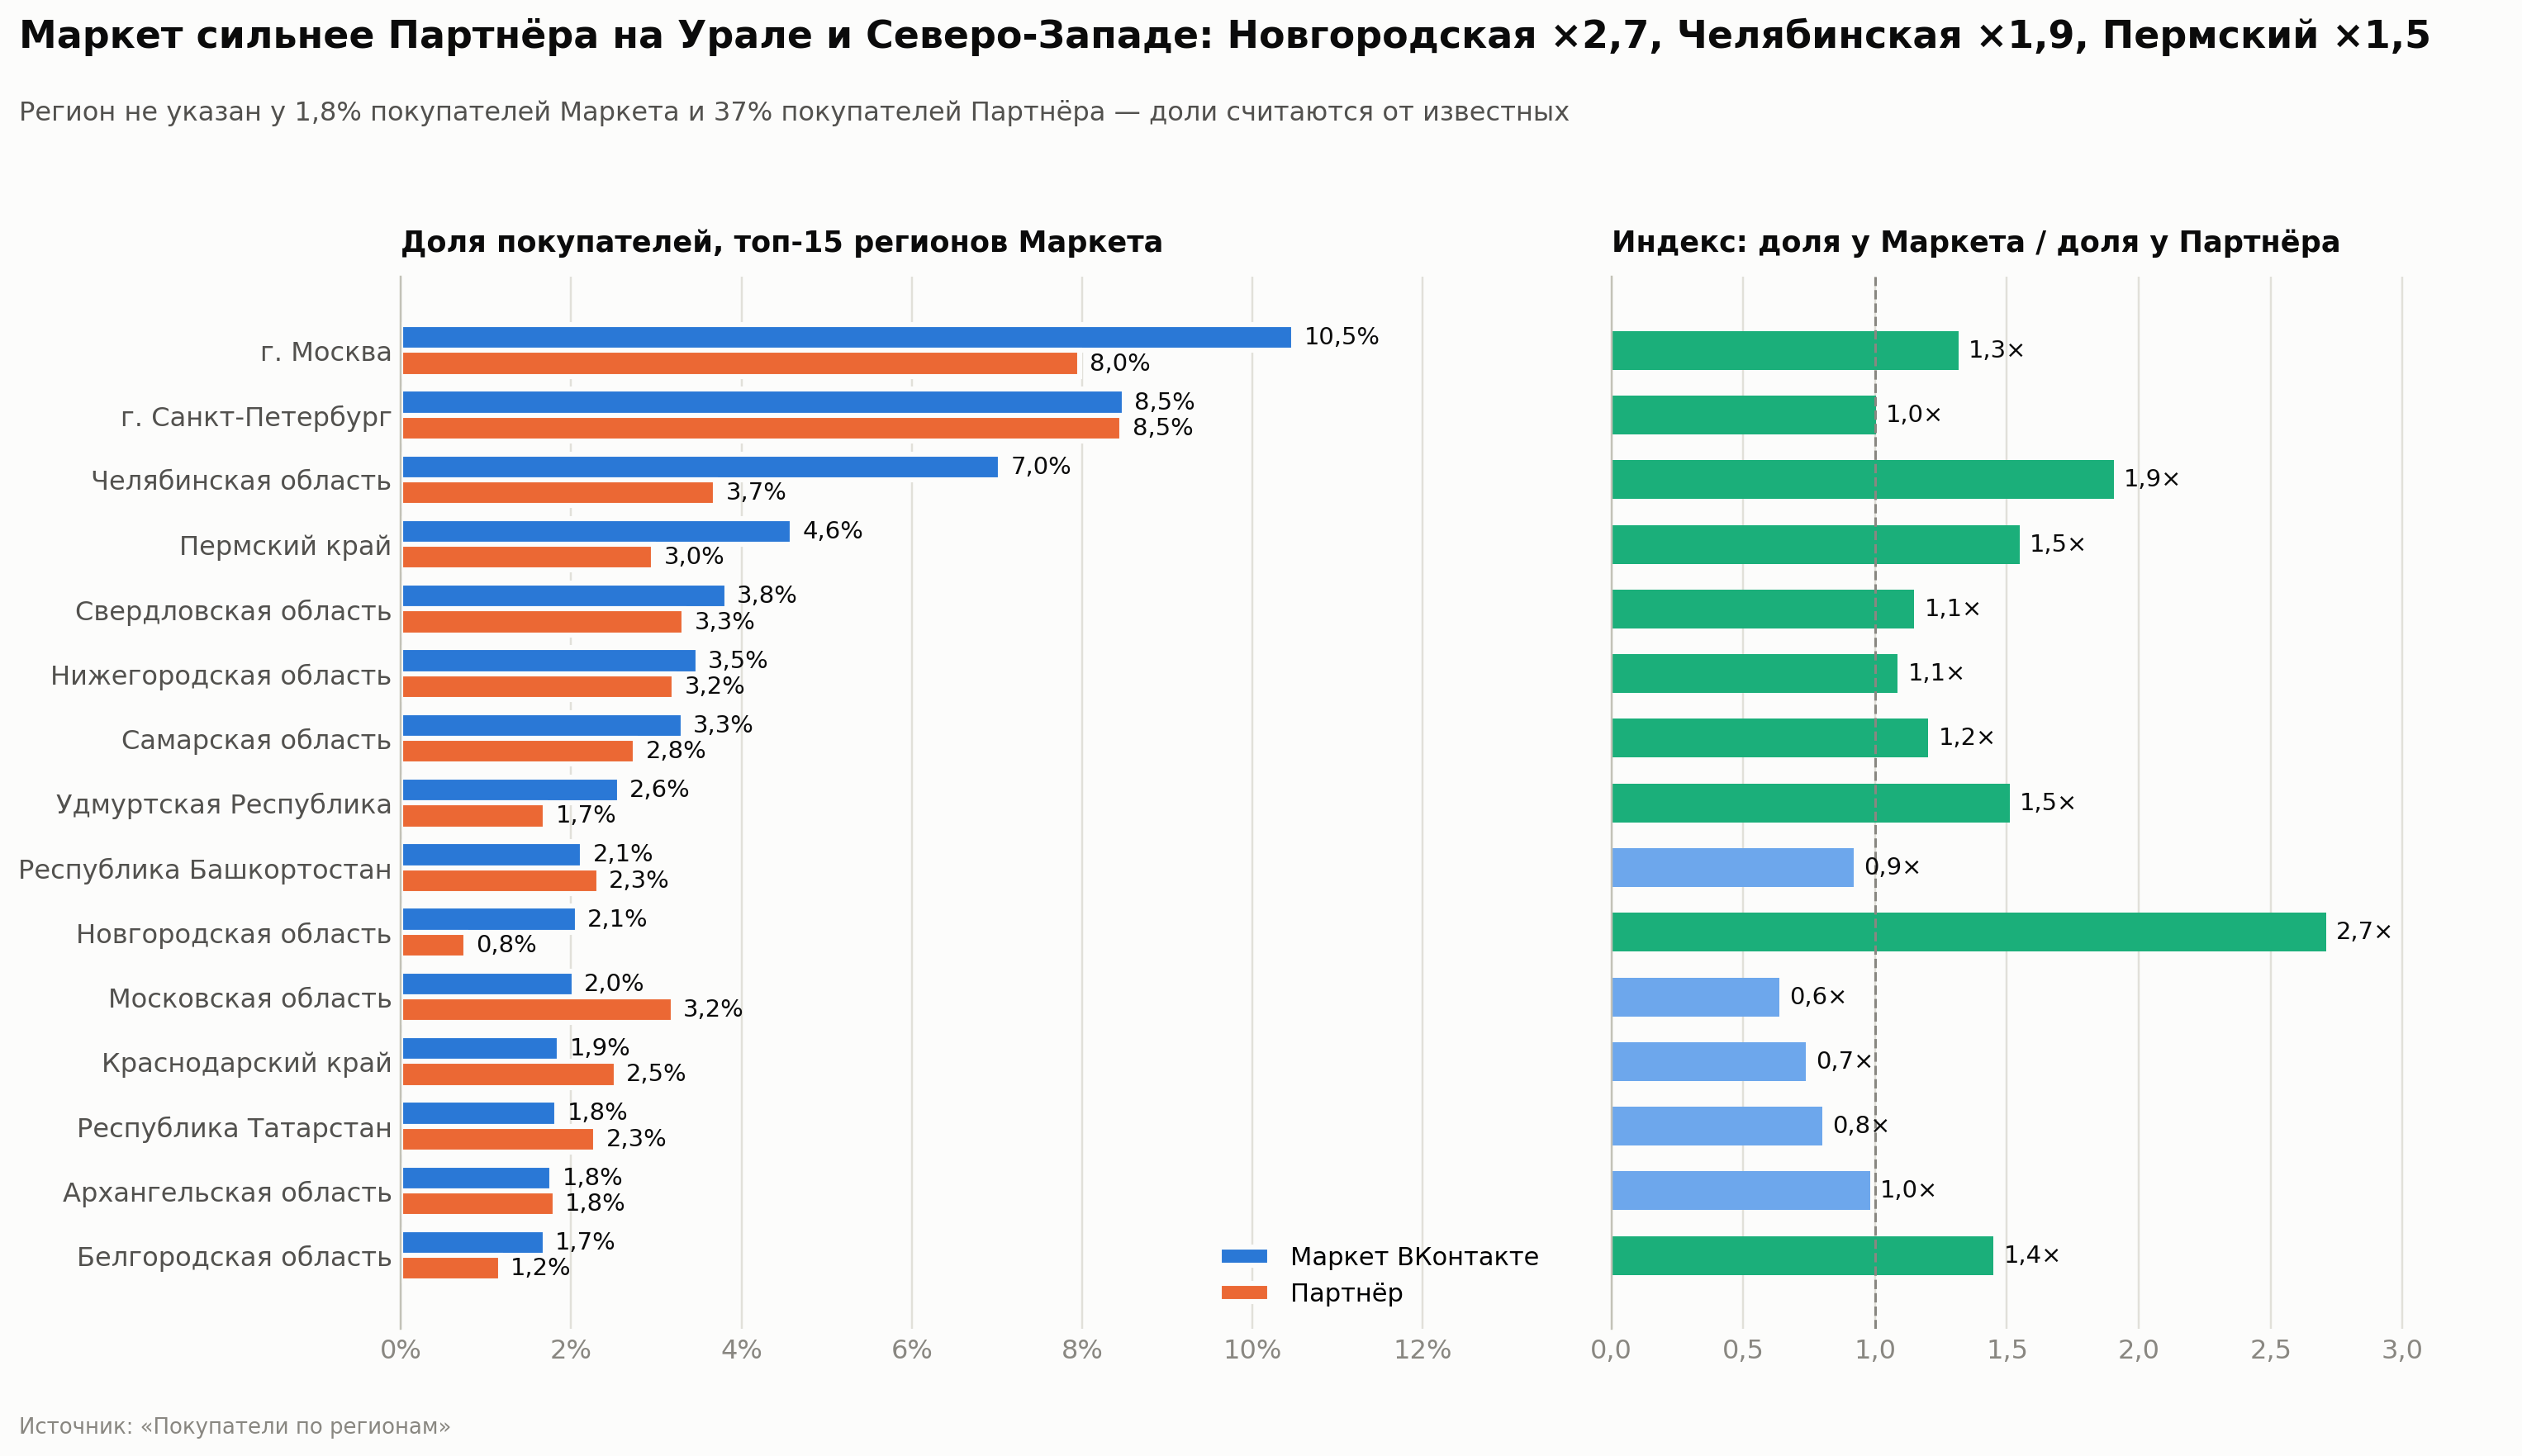

In [26]:
reg = pd.read_excel(xls, "Покупатели по регионам")
reg.columns = ["region", "buy_vk", "ord_vk", "buy_p", "ord_p"]
unknown = reg.set_index("region").loc["Не указан"]
known = reg[reg.region != "Не указан"].copy()
known["sv"] = known.buy_vk / known.buy_vk.sum(); known["sp"] = known.buy_p / known.buy_p.sum()
known["idx"] = known.sv / known.sp
top = known.nlargest(15, "buy_vk").iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True, gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
y = np.arange(len(top)); h = 0.4
b1 = ax.barh(y + h / 2, top.sv, h, color=VK, label="Маркет ВКонтакте", edgecolor=SURF, linewidth=2)
b2 = ax.barh(y - h / 2, top.sp, h, color=PARTNER, label="Партнёр", edgecolor=SURF, linewidth=2)
hbar_labels(ax, b1, [pct(v, 1) for v in top.sv]); hbar_labels(ax, b2, [pct(v, 1) for v in top.sp])
ax.set_yticks(y, top.region.str.replace(" (Татарстан)", "")); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, top.sv.max() * 1.3); hgrid(ax); ax.legend(loc="lower right"); ax.set_title("Доля покупателей, топ-15 регионов Маркета")
ax = axes[1]
colors = [CAT[2] if v > 1 else SEQ[2] for v in top.idx]
bars = ax.barh(y, top.idx, color=colors, height=0.6)
hbar_labels(ax, bars, [ru(v, 1) + "×" for v in top.idx]); ax.axvline(1, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, top.idx.max() * 1.25); hgrid(ax); ax.set_title("Индекс: доля у Маркета / доля у Партнёра")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: ru(v, 1)))
hi = top.sort_values("idx", ascending=False).head(3)
finish(fig, "Маркет сильнее Партнёра на Урале и Северо-Западе: " + ", ".join(f"{r.split()[0]} ×{ru(i, 1)}" for r, i in zip(hi.region, hi.idx)),
       f"Регион не указан у {pct(unknown.buy_vk / reg.buy_vk.sum(), 1)} покупателей Маркета и {pct(unknown.buy_p / reg.buy_p.sum(), 0)} покупателей Партнёра — доли считаются от известных",
       "Источник: «Покупатели по регионам»", top=0.86)

## 6. Сверки и расхождения

Синтетический датасет намеренно содержит противоречия (бриф: «часть данных могла быть искажена»). Ниже — автоматические проверки: что сходится и что нет. Расхождения — кандидаты в вопросы к организаторам и в оговорки на слайдах.

In [27]:
v = lambda k, i: T[k][i]
checks = []
def chk(name, got, expected, tol=0):
    ok = abs(got - expected) <= tol
    checks.append({"Проверка": name, "Факт": ru(got), "Ожидание": ru(expected), "Разница": ru(got - expected), "Статус": "сходится" if ok else "РАСХОЖДЕНИЕ"})

for col, key, i in [("imp_vk", "Показы товаров", 0), ("imp_p", "Показы товаров", 1), ("open_vk", "Открытия карточки товара", 0),
                    ("open_p", "Открытия карточки товара", 1), ("ord_vk", "Оформленные заказы", 0), ("ord_p", "Оформленные заказы", 1),
                    ("paid_vk", "Оплаченные заказы", 0), ("gmv_vk", "GMV, ₽", 0), ("gmv_p", "GMV, ₽", 1)]:
    chk(f"Сумма по дням = итог: {key} ({'Маркет' if i == 0 else 'Партнёр'})", daily[col].sum(), v(key, i), tol=1)
chk("Категории: заказы Маркета = итог", cats.ord_vk.sum(), v("Оформленные заказы", 0))
chk("Категории: заказы Партнёра = итог", cats.ord_p.sum(), v("Оформленные заказы", 1))
chk("Категории: открытия Маркета = итог", cats.open_vk.sum(), v("Открытия карточки товара", 0))
chk("Источники: открытия Маркета = итог", main.vk.sum(), v("Открытия карточки товара", 0))
chk("Источники: открытия Партнёра = итог", main.partner.sum(), v("Открытия карточки товара", 1))
chk("Демография: заказы Партнёра = итог", pd.read_excel(xls, "Покупатели").iloc[:, 5].sum(), v("Оформленные заказы", 1))
chk("Демография: заказы Партнёра = контрольная строка", pd.read_excel(xls, "Покупатели").iloc[:, 5].sum(), num(tot.loc[tot.index[15], "partner"]))
chk("Регионы: заказы Маркета = контрольная строка", reg.ord_vk.sum(), num(tot.loc[tot.index[15], "vk"]))
chk("Лента + Клипы Партнёра ≥ реферальные открытия", main.loc[["Лента", "Клипы"], "partner"].sum(), srcs.partner.iloc[-1])
chk("GMV / заказы = средний чек Маркета", v("GMV, ₽", 0) / v("Оформленные заказы", 0), v("Средний чек, ₽", 0), tol=1)
chk("Бизнесы: заказы при выключенном чекауте", ((biz.checkout == 0) & biz.has_order).sum(), 0)
chk("Бизнесы: товарных постов больше всех постов", (biz.posts_p > biz.posts).sum(), 0)
res = pd.DataFrame(checks)
res.style.hide(axis="index").map(lambda s: f"color: {BAD}; font-weight: bold" if s == "РАСХОЖДЕНИЕ" else f"color: {GOOD}", subset=["Статус"])

Проверка,Факт,Ожидание,Разница,Статус
Сумма по дням = итог: Показы товаров (Маркет),4 777 750 023,4 777 750 023,0,сходится
Сумма по дням = итог: Показы товаров (Партнёр),5 729 628 790,5 729 628 790,0,сходится
Сумма по дням = итог: Открытия карточки товара (Маркет),193 512 461,193 512 461,0,сходится
Сумма по дням = итог: Открытия карточки товара (Партнёр),86 882 822,86 882 822,0,сходится
Сумма по дням = итог: Оформленные заказы (Маркет),413 740,413 740,0,сходится
Сумма по дням = итог: Оформленные заказы (Партнёр),4 927 525,4 927 525,0,сходится
Сумма по дням = итог: Оплаченные заказы (Маркет),4 903,4 903,0,сходится
"Сумма по дням = итог: GMV, ₽ (Маркет)",1 564 546 740,1 564 546 740,0,сходится
"Сумма по дням = итог: GMV, ₽ (Партнёр)",5 119 514 684,5 119 514 685,-1,сходится
Категории: заказы Маркета = итог,435 285,413 740,21 545,РАСХОЖДЕНИЕ


**Как читать расхождения:**

- Дневные ряды полностью сходятся с итогами — для динамики им можно доверять.
- Категорийный срез **не равен** итогам (у Маркета на +21 545 заказов больше, у Партнёра на −370 008 меньше) — категории пересекаются или считаются в другом окне. Категории используем для **структуры**, а не для абсолютов.
- Сумма источников = итог открытий, а реферальные открытия Партнёра (82,3 млн) **больше**, чем Лента + Клипы (80,5 млн) — определение вложенной строки шире.
- Демография и регионы сходятся со своими контрольными строками (итоги, строки 16–17), но у Партнёра теряется ~370 тыс. заказов против общего итога — вероятно, прямые переходы без карточки.
- В листе «Бизнесы» 14 сообществ с заказами при выключенном чекауте и 11 с товарными постами больше общего числа: признаки фиксируются на дату выгрузки, а заказы — за месяц.

## 7. Выводы для стратегии

**Про бизнесы (4 158 товарных и смешанных сообществ)**

1. **Заказы принимают почти все, а онлайн-оплату и доставку — единицы.** Приём заказов в VK включён у 92% товарных сообществ, онлайн-оплату или доставку через службу подключили ~20%, онлайн-оплату — около 5%. С ними доля продающих выше в 3,1 раза (16% против 5%). Подключают в основном крупные продавцы; причины проверяются интервью (раздел 2.2).
2. **Самый большой сегмент — «заказы в VK принимают, но нет ни онлайн-оплаты и доставки, ни трафика»** (61% базы, ноль заказов). Это кандидат для отдельного теста контента и привлечения спроса. Для теста оформления проверяем сообщества с активным каталогом, чекаутом и открытиями карточки.
3. **Продажи сильно сконцентрированы:** 10 сообществ дают более половины заказов, медианный продавец — 2 заказа в месяц. Цель «больше продающих бизнесов» требует работы с хвостом, а не с лидерами.
4. **Товарный контент — редкость, но работает.** Его публикуют ~6% готовых сообществ; у тех, кто публикует 11+ товарных постов/клипов, доля с заказом в разы выше. Наличие открытий карточки из контента — самый сильный сигнал продаж.
5. **Тезис брифа «товарный контент распространяется хуже» подтверждается только частично.** По просмотрам на публикацию товарные посты не хуже обычных (медиана ×1,9), но лайкают их почти вдвое реже (0,83% vs 1,42%), а до карточки доходят лишь ~3 из 1 000 просмотров. Проблема — не охват, а превращение просмотра в действие.
6. **Лучше продают дешёвые повседневные товары и еду** (до ~530 ₽; «Кулинария и еда», «Товары и магазины», хендмейд); «Красота» и «Дом и ремонт» многочисленны, но почти не продают — кандидаты на отдельный сценарий (через сообщения/заявки).

**Про Маркет ВКонтакте**

7. **Показы, открытия и заказы различаются по маршрутам.** Отношение заказов к открытиям — 0,21% у VK и 5,67% у Партнёра. В агрегате Партнёра есть прямые переходы. Для оценки барьера оформления нужны события одной когорты.
8. **Внутри VK оплачено около 1,2% оформленных заказов.** Возможна оплата вне VK, а итоговые статусы остальных заказов неизвестны. Основная метрика — оформленные заказы собственных продавцов.
9. **Главная Маркета даёт 0,2% открытий карточки**, витрины сообществ — 39%, контент — ~19%. Общая витрина как точка входа почти не используется: роль Маркета — **инфраструктура карточки, оформления заказа и онлайн-оплаты для витрин сообществ и контента**, а не отдельная витрина-маркетплейс.
10. **Аудитория Маркета моложе и регионально иная** (25–34 — 28% против 17% у Партнёра; перевес в Новгородской, Челябинской областях и Пермском крае), средний чек выше (3 781 ₽ vs 1 039 ₽), но повторных покупателей меньше (19% vs 26,6%).

**Ограничения:** данные синтетические, за один месяц, без связи «сообщество ↔ заказы Маркета». Сравнения описательные: для причинных выводов нужен пилот с контрольной группой.